# 🛒 Brazilian E-Commerce (Olist) — End-to-End Analytics & ML Pipeline

Cleaning → star schema → EDA → satisfaction & delivery-time models → Excel / Power BI exports.

**How to run:** `Runtime ▸ Run all`. The data loads automatically (local files → Drive → Kaggle → upload prompt as the last resort).

## Part 0 — Setup

In [1]:
# Only install what is missing, so a normal Colab session skips pip completely
import importlib.util, subprocess, sys
missing = [p for p in ('xlsxwriter',) if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print(f'✅ Installed: {missing}' if missing else '✅ All required libraries are already available')

✅ Installed: ['xlsxwriter']


In [2]:
%config InlineBackend.figure_format = 'retina'

import os, time, zipfile, warnings
from contextlib import contextmanager
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display, HTML

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

SEED = 42
np.random.seed(SEED)

IN_COLAB = Path('/content').exists()
BASE_DIR = Path('/content') if IN_COLAB else Path.cwd()
OUTPUT_DIR = BASE_DIR / 'output'
OUTPUT_DIR.mkdir(exist_ok=True)

# One palette for every chart and table
C = dict(blue='#2E5B88', navy='#1B365D', green='#2E9E6B', red='#D64545', orange='#E8913A',
         purple='#7B5EA7', teal='#1A9E9E', gray='#8A94A6', light='#EEF3F9')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300,
    'figure.constrained_layout.use': True,        # keeps titles, labels and legends from overlapping
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'axes.labelsize': 11, 'legend.frameon': False,
})

fmt_int = mticker.FuncFormatter(lambda x, _: f'{x:,.0f}')
fmt_brl = mticker.FuncFormatter(lambda x, _: f'R${x:,.0f}')
fmt_pct = mticker.FuncFormatter(lambda x, _: f'{x:.0f}%')


@contextmanager
def timed(label):
    t0 = time.perf_counter()
    yield
    print(f'⏱️  {label}: {time.perf_counter() - t0:.1f}s')


def banner(text, icon='📌'):
    print(f'\n{icon} {text}\n' + '─' * (len(text) + 4))


def show(df, caption=None, heat=None, bars=None, cmap='YlGnBu', index=False, precision=2):
    """Styled table: navy header, zebra rows, optional heatmap / data bars."""
    try:
        if not index:
            df = df.reset_index(drop=True)             # Styler needs a unique index
        st = df.style.format(precision=precision, thousands=',', na_rep='–')
        if not index:
            st = st.hide(axis='index')
        st = st.set_table_styles([
            {'selector': 'th', 'props': [('background-color', C['navy']), ('color', 'white'),
                                         ('font-weight', '600'), ('padding', '6px 10px'), ('text-align', 'center')]},
            {'selector': 'td', 'props': [('padding', '5px 10px'), ('color', '#1f2933'), ('background-color', 'white')]},
            {'selector': 'tbody tr:nth-child(even) td', 'props': [('background-color', C['light'])]},
            {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '15px'), ('font-weight', 'bold'),
                                              ('color', C['blue']), ('text-align', 'left'), ('padding-bottom', '6px')]},
        ])
        if caption:
            st = st.set_caption(caption)
        if heat:
            st = st.background_gradient(subset=heat, cmap=cmap)
        if bars:                                   # soft shading, clearly limited to the cell
            st = st.background_gradient(subset=bars, cmap='Blues', low=0, high=.45)
        text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
        if text_cols:
            st = st.set_properties(subset=text_cols, **{'text-align': 'left'})
        display(HTML(st.to_html()))                 # rendering errors are caught here, not in the browser
    except Exception:
        display(df)


def new_fig(w=10, h=5.2):
    """One chart = one figure."""
    return plt.subplots(figsize=(w, h))


print(f'✅ Ready  |  pandas {pd.__version__}  |  numpy {np.__version__}  |  output → {OUTPUT_DIR}')

✅ Ready  |  pandas 2.2.3  |  numpy 2.4.6  |  output → /content/output


## Part 1 — Data Ingestion
Finds the nine Olist CSV files (or `archive.zip`) automatically and loads them in parallel.

`DATA_SOURCE` options: `'auto'` (default) · `'drive'` · `'kaggle'` · `'upload'`. Upload is the slowest, so it is only used when nothing else works.

In [3]:
DATA_SOURCE = 'auto'
DRIVE_FOLDER = Path('/content/drive/MyDrive/olist_data')

FILES = {
    'orders':      'olist_orders_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'reviews':     'olist_order_reviews_dataset.csv',
    'customers':   'olist_customers_dataset.csv',
    'products':    'olist_products_dataset.csv',
    'payments':    'olist_order_payments_dataset.csv',
    'sellers':     'olist_sellers_dataset.csv',
    'category_tr': 'product_category_name_translation.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
}

REQUIRED = {
    'orders':      ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp'],
    'order_items': ['order_id', 'product_id', 'seller_id', 'price', 'freight_value'],
    'reviews':     ['order_id', 'review_score'],
    'customers':   ['customer_id', 'customer_state'],
    'products':    ['product_id', 'product_category_name'],
    'payments':    ['order_id', 'payment_type', 'payment_value'],
    'sellers':     ['seller_id', 'seller_state'],
    'category_tr': ['product_category_name', 'product_category_name_english'],
    'geolocation': ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng'],
}


def find_data_dir():
    """Return the folder that holds the CSVs; unzip archive.zip when that is what we find."""
    for folder in (BASE_DIR, Path.cwd(), BASE_DIR / 'data', BASE_DIR / 'olist_data', DRIVE_FOLDER):
        if not folder.exists():
            continue
        if (folder / FILES['orders']).exists():
            return folder
        for z in folder.glob('*.zip'):
            if z.name == 'PowerBI_CSV_Exports.zip':          # our own export, not the dataset
                continue
            with zipfile.ZipFile(z) as zf:
                if any(FILES['orders'] in name for name in zf.namelist()):
                    target = BASE_DIR / 'olist_data'
                    zf.extractall(target)
                    print(f'📦 Extracted {z.name} → {target}')
                    return next(target.rglob(FILES['orders'])).parent
    return None


def get_data_dir():
    if DATA_SOURCE == 'drive' and IN_COLAB:
        from google.colab import drive
        drive.mount('/content/drive')
    folder = find_data_dir()
    if folder:
        return folder
    if DATA_SOURCE in ('auto', 'kaggle'):
        try:
            import kagglehub
            return Path(kagglehub.dataset_download('olistbr/brazilian-ecommerce'))
        except Exception as e:
            print(f'ℹ️  Kaggle download skipped ({type(e).__name__}) — falling back to manual upload')
    if IN_COLAB:
        from google.colab import files
        print("📂 Upload 'archive.zip' (or the 9 CSV files):")
        for name, data in files.upload().items():
            (BASE_DIR / name).write_bytes(data)
        folder = find_data_dir()
        if folder:
            return folder
    raise FileNotFoundError('Olist files not found. Put archive.zip or the 9 CSVs next to the notebook.')


def read_csv_fast(path):
    try:
        return pd.read_csv(path, engine='pyarrow')     # multi-threaded reader
    except Exception:
        return pd.read_csv(path)


with timed('Loading the 9 CSV files'):
    DATA_DIR = get_data_dir()
    absent = [f for f in FILES.values() if not (DATA_DIR / f).exists()]
    if absent:
        raise FileNotFoundError(f'Missing in {DATA_DIR}: {absent}')
    with ThreadPoolExecutor(max_workers=4) as pool:
        raw = dict(zip(FILES, pool.map(lambda f: read_csv_fast(DATA_DIR / f), FILES.values())))

print(f'📁 Data folder: {DATA_DIR}')

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
⏱️  Loading the 9 CSV files: 8.3s
📁 Data folder: /kaggle/input/brazilian-ecommerce


In [4]:
# Overview of all raw tables + required-column check
rows = []
for key, df in raw.items():
    lacking = [c for c in REQUIRED[key] if c not in df.columns]
    rows.append({
        'Table': key, 'Rows': len(df), 'Columns': df.shape[1],
        'Missing cells': int(df.isna().sum().sum()), 'Duplicate rows': int(df.duplicated().sum()),
        'Memory (MB)': df.memory_usage(deep=True).sum() / 1e6,
        'Status': '✅ OK' if not lacking else f'❌ missing {lacking}',
    })
overview = pd.DataFrame(rows)
show(overview, '📋 Raw tables overview', heat=['Rows'], bars=['Missing cells'])
assert overview['Status'].eq('✅ OK').all(), 'Fix the missing columns before continuing'

for key in ('orders', 'order_items', 'products'):
    show(raw[key].head(3), f'📌 Sample — {key}')

Table,Rows,Columns,Missing cells,Duplicate rows,Memory (MB),Status
orders,"99,441",8,"4,908",0,25.85,✅ OK
order_items,"112,650",7,0,0,30.98,✅ OK
reviews,"99,224",7,"145,903",0,27.95,✅ OK
customers,"99,441",5,0,0,27.88,✅ OK
products,"32,951",9,"2,448",0,6.60,✅ OK
payments,"103,886",5,0,0,17.02,✅ OK
sellers,"3,095",4,0,0,0.62,✅ OK
category_tr,71,2,0,0,0.01,✅ OK
geolocation,"1,000,163",5,0,"261,831",136.59,✅ OK


order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87


product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.00,287.00,1.00,225.00,16.00,10.00,14.00
3aa071139cb16b67ca9e5dea641aaa2f,artes,44.00,276.00,1.00,"1,000.00",30.00,18.00,20.00
96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.00,250.00,1.00,154.00,18.00,9.00,15.00


## Part 2 — Data Cleaning
Small reusable functions (one job each), a shared audit log, and one pipeline that runs them on every table.

In [5]:
cleaning_log = []

def log_step(step, table, column, issue, action, affected):
    cleaning_log.append({'step': step, 'table': table, 'column': str(column),
                         'issue': issue, 'action': action, 'affected': int(affected)})

def is_text(s):
    return pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s)

print('✅ Cleaning log ready')

✅ Cleaning log ready


### 2.1 — Profiling (`profile_data`)

In [6]:
def profile_data(df):
    """One row per column: type, gaps, cardinality and basic stats for numeric columns."""
    out = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                        'missing_%': df.isna().mean() * 100, 'unique': df.nunique()})
    num = df.select_dtypes('number')
    for name, fn in [('mean', num.mean), ('median', num.median), ('std', num.std),
                     ('min', num.min), ('max', num.max), ('skew', num.skew)]:
        out[name] = fn()
    return out.rename_axis('column').reset_index()

show(profile_data(raw['products']), '🔍 Profile — products', heat=['missing_%'], cmap='OrRd')
show(profile_data(raw['orders']),   '🔍 Profile — orders',   heat=['missing_%'], cmap='OrRd')

column,dtype,missing,missing_%,unique,mean,median,std,min,max,skew
product_id,object,0,0.00,"32,951",–,–,–,–,–,–
product_category_name,object,610,1.85,73,–,–,–,–,–,–
product_name_lenght,float64,610,1.85,66,48.48,51.00,10.25,5.00,76.00,-0.90
product_description_lenght,float64,610,1.85,"2,960",771.50,595.00,635.12,4.00,"3,992.00",1.96
product_photos_qty,float64,610,1.85,19,2.19,1.00,1.74,1.00,20.00,2.19
product_weight_g,float64,2,0.01,"2,204","2,276.47",700.00,"4,282.04",0.00,"40,425.00",3.60
product_length_cm,float64,2,0.01,99,30.82,25.00,16.91,7.00,105.00,1.75
product_height_cm,float64,2,0.01,102,16.94,13.00,13.64,2.00,105.00,2.14
product_width_cm,float64,2,0.01,95,23.20,20.00,12.08,6.00,118.00,1.67


column,dtype,missing,missing_%,unique,mean,median,std,min,max,skew
order_id,object,0,0.00,"99,441",–,–,–,–,–,–
customer_id,object,0,0.00,"99,441",–,–,–,–,–,–
order_status,object,0,0.00,8,–,–,–,–,–,–
order_purchase_timestamp,datetime64[s],0,0.00,"98,875",–,–,–,–,–,–
order_approved_at,datetime64[s],160,0.16,"90,733",–,–,–,–,–,–
order_delivered_carrier_date,datetime64[s],"1,783",1.79,"81,018",–,–,–,–,–,–
order_delivered_customer_date,datetime64[s],"2,965",2.98,"95,664",–,–,–,–,–,–
order_estimated_delivery_date,datetime64[s],0,0.00,459,–,–,–,–,–,–


**Note:** delivery timestamps are empty for orders that were never delivered, and review comments are optional.

### 2.2 — Duplicates, Missing Values and Data Types

In [7]:
def handle_duplicates(df, table, subset=None):
    """Drop exact duplicates (optionally by key). Multi-row tables such as order items are skipped by the pipeline."""
    dup = df.duplicated(subset=subset)
    n = int(dup.sum())
    log_step('duplicates', table, subset or 'all columns', f'{n:,} duplicate rows',
             'kept first occurrence' if n else 'nothing to remove', n)
    return df.loc[~dup].reset_index(drop=True), n


PLACEHOLDERS = ['', ' ', 'N/A', 'NA', 'n/a', 'na', '?', 'None', 'none', 'NaN', 'nan', '-']

def handle_missing(df, table, drop_thresh=0.60):
    """Fill gaps: median (skewed) / mean (symmetric) for numbers, mode or 'Unknown' for text.
    Columns above `drop_thresh` are dropped. Datetime gaps are kept: they mean 'not delivered yet'."""
    df = df.copy()
    text_cols = [c for c in df.columns if is_text(df[c])]
    if text_cols:
        df[text_cols] = df[text_cols].replace(PLACEHOLDERS, np.nan)

    report, n = [], len(df)
    for col in df.columns[df.isna().any().to_numpy()]:
        s = df[col]
        if pd.api.types.is_datetime64_any_dtype(s):
            continue
        miss = int(s.isna().sum())
        if miss / n > drop_thresh:
            action = f'Dropped column (>{drop_thresh:.0%} missing)'
            df = df.drop(columns=col)
        elif pd.api.types.is_numeric_dtype(s):
            skewed = abs(s.skew()) > 1
            fill = s.median() if skewed else s.mean()
            action = f"{'Median' if skewed else 'Mean'} imputation ({fill:,.2f})"
            df[col] = s.fillna(fill)
        else:
            mode = s.mode(dropna=True)
            if len(mode) and (s == mode.iloc[0]).mean() > 0.40:
                fill, action = mode.iloc[0], f"Mode imputation ('{mode.iloc[0]}')"
            else:
                fill, action = 'Unknown', "Tagged as 'Unknown'"
            df[col] = s.fillna(fill)
        report.append({'Column': col, 'Missing': miss, 'Missing %': miss / n * 100,
                       'Remaining': int(df[col].isna().sum()) if col in df.columns else 0, 'Action': action})
        log_step('missing', table, col, f'{miss:,} missing ({miss / n:.1%})', action, miss)
    return df, pd.DataFrame(report)


SPELLING = {'product_name_lenght': 'product_name_length',
            'product_description_lenght': 'product_description_length'}
DATE_SUFFIXES = ('_date', '_timestamp', '_at')

def fix_dtypes(df, table):
    """snake_case names, source typos fixed, text trimmed, date columns parsed to datetime."""
    df = df.rename(columns=lambda c: SPELLING.get(c.strip().lower(), c.strip().lower()))
    for col in df.columns:
        if not is_text(df[col]):
            continue
        if col.endswith(DATE_SUFFIXES):
            df[col] = pd.to_datetime(df[col], errors='coerce')
            log_step('dtypes', table, col, 'dates stored as text', 'parsed to datetime', 0)
        else:
            try:
                df[col] = df[col].str.strip()
            except AttributeError:                 # mixed column, leave it alone
                pass
    return df


# Demo: missing values in products, before vs after
products_demo, products_gaps = handle_missing(raw['products'], 'products (demo)')
cleaning_log.clear()                              # demo calls should not pollute the real audit log
print(f"Missing cells in products: {int(raw['products'].isna().sum().sum()):,} → {int(products_demo.isna().sum().sum()):,}")
show(products_gaps, '🩹 Missing-value treatment — products', heat=['Missing %'], cmap='OrRd')

Missing cells in products: 2,448 → 0


Column,Missing,Missing %,Remaining,Action
product_category_name,610,1.85,0,Tagged as 'Unknown'
product_name_lenght,610,1.85,0,Mean imputation (48.48)
product_description_lenght,610,1.85,0,Median imputation (595.00)
product_photos_qty,610,1.85,0,Median imputation (1.00)
product_weight_g,2,0.01,0,Median imputation (700.00)
product_length_cm,2,0.01,0,Median imputation (25.00)
product_height_cm,2,0.01,0,Median imputation (13.00)
product_width_cm,2,0.01,0,Median imputation (20.00)


### 2.3 — Outliers (`detect_outliers`, `treat_outliers`)
Detection uses the IQR rule (or z-score). Treatment clips to the 1.5×IQR lower fence (never below 0) and the 99th percentile.
Price and freight are **not** capped in the main tables, because that would understate revenue. They are capped later, inside the ML feature step only.

Column,Method,Lower fence,Upper fence,Min,Max,Outliers,Outlier %
price,IQR,-102.60,277.40,0.85,"6,735.00","8,427",7.48
freight_value,IQR,0.98,33.25,0.00,409.68,"12,134",10.77


Column,Max before,Max after,Mean before,Mean after,Values capped
price,"6,735.00",890.00,120.65,115.27,"1,117"
freight_value,409.68,84.52,19.99,19.61,"1,645"


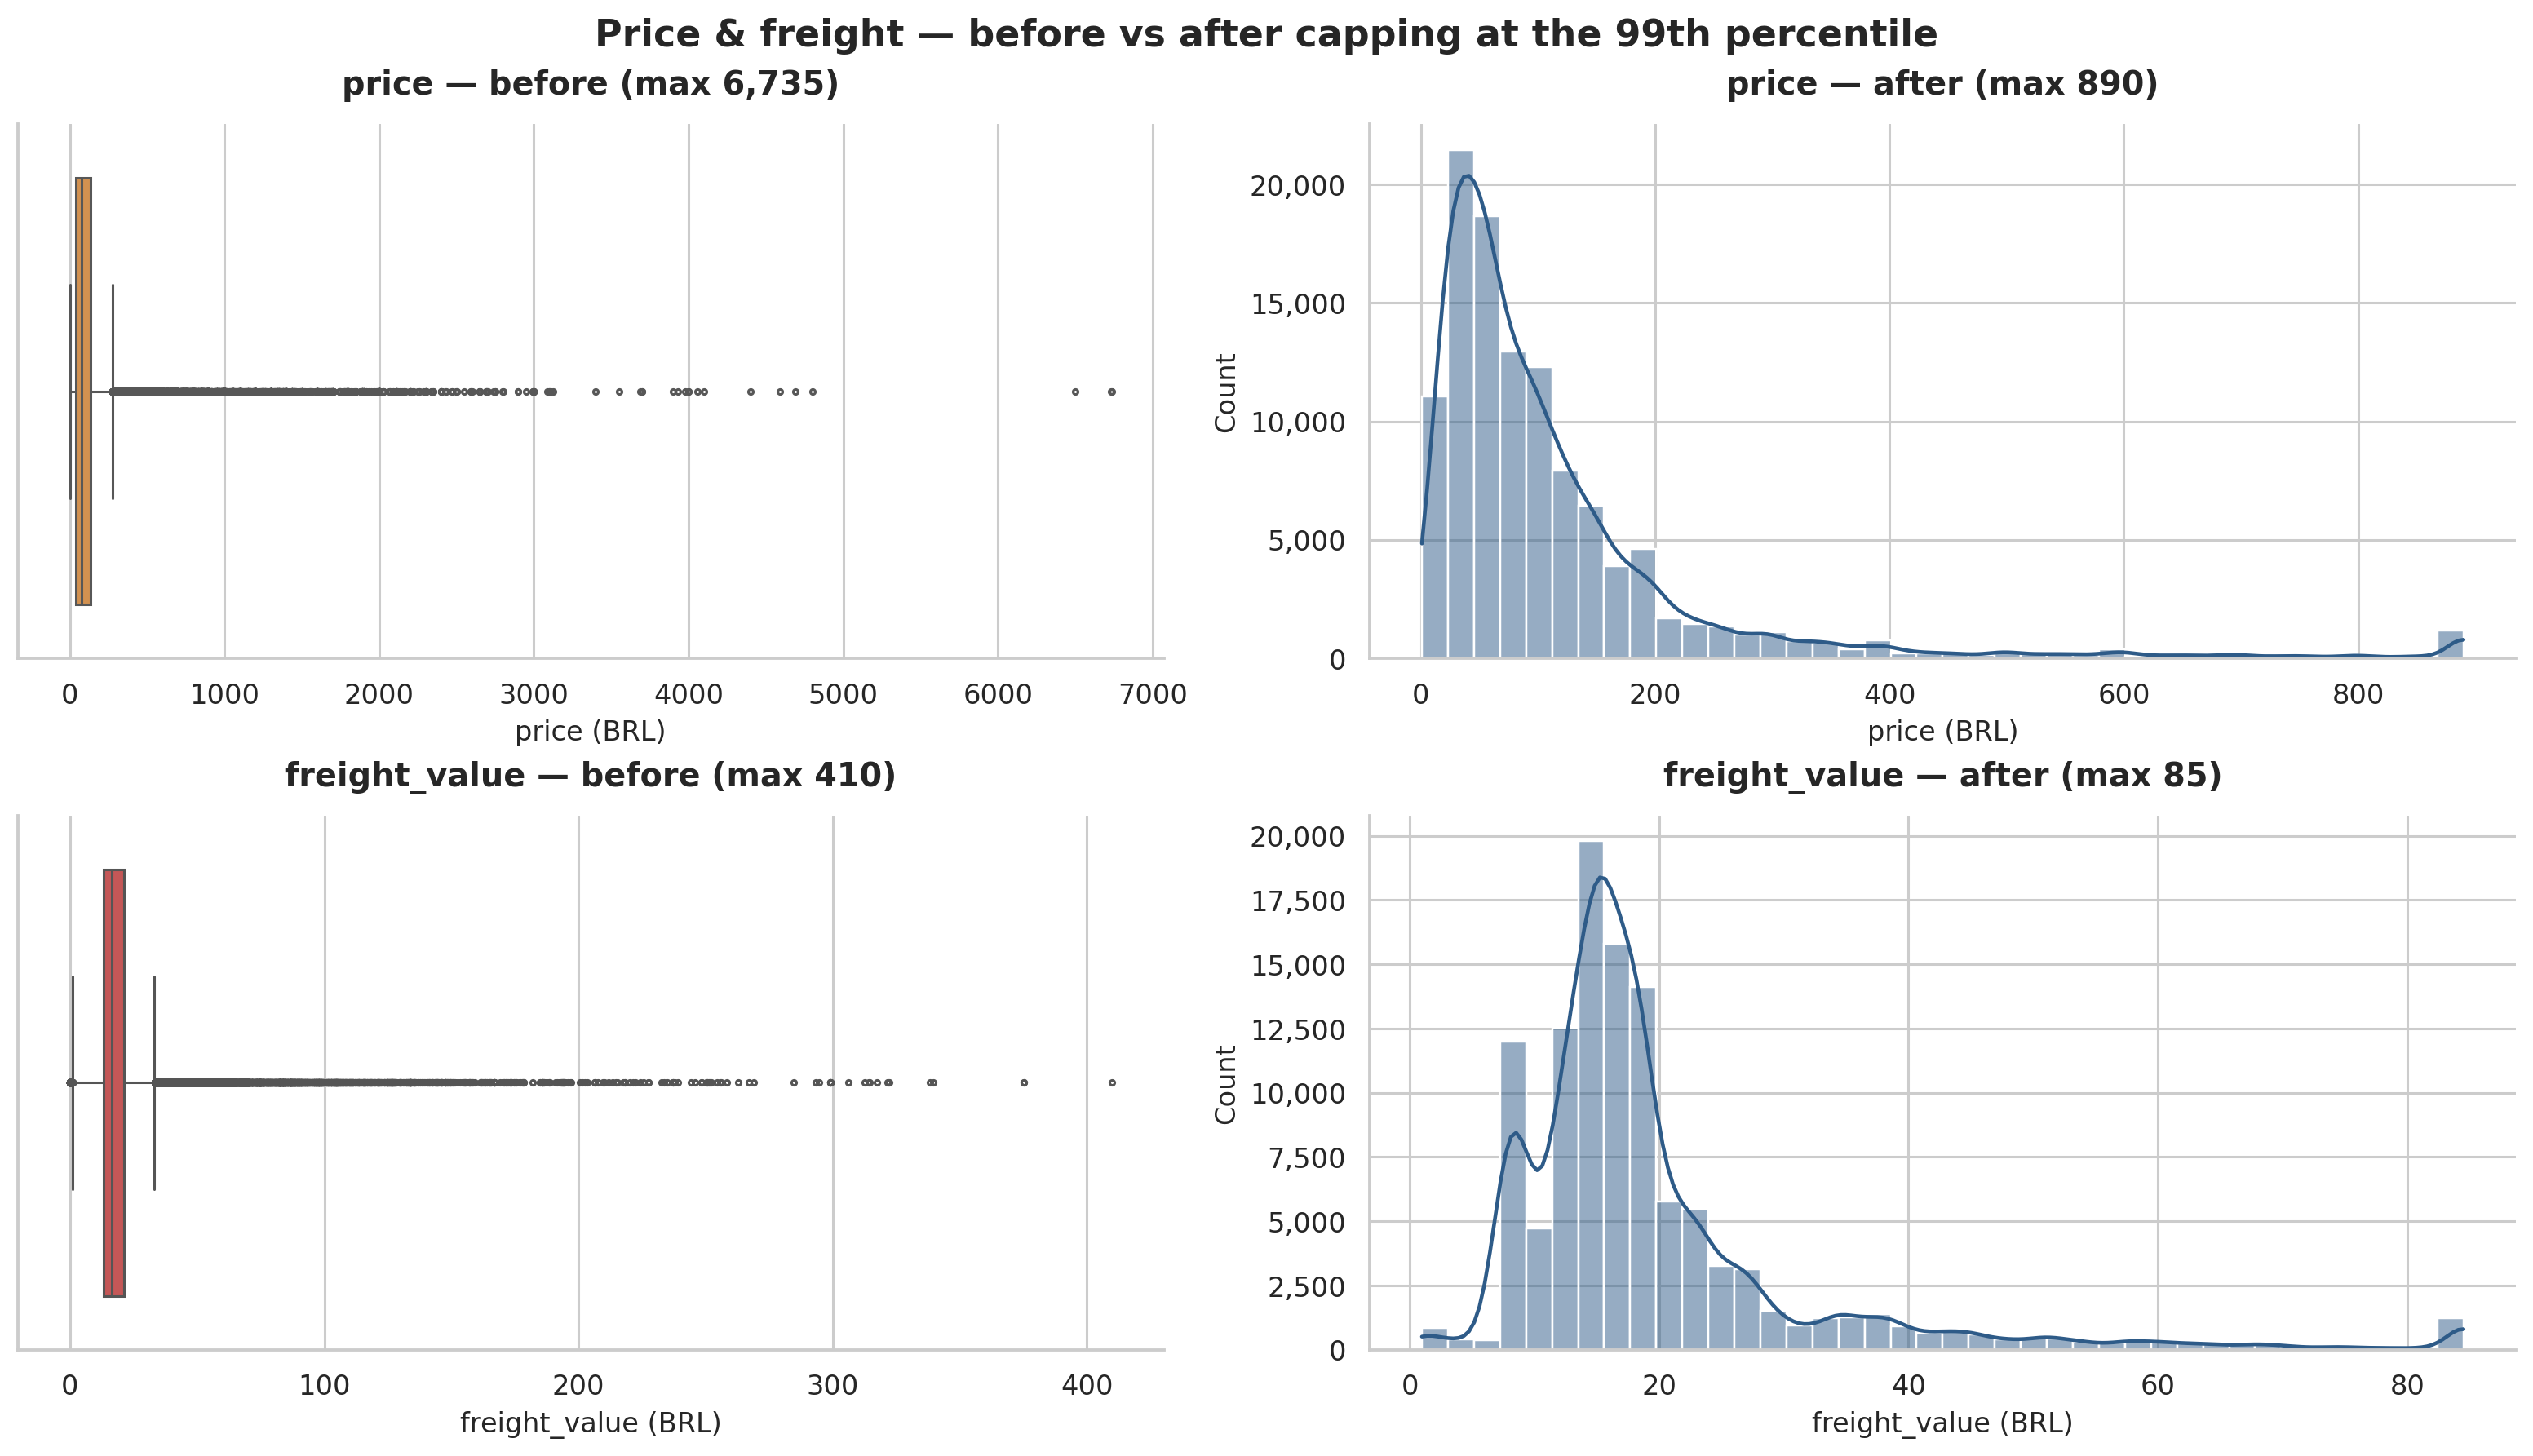

In [8]:
def detect_outliers(df, cols, method='iqr'):
    rows = []
    for col in cols:
        s = df[col].dropna()
        if method == 'iqr':
            q1, q3 = s.quantile([.25, .75])
            lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        else:
            lo, hi = s.mean() - 3 * s.std(), s.mean() + 3 * s.std()
        n_out = int(((s < lo) | (s > hi)).sum())
        rows.append({'Column': col, 'Method': method.upper(), 'Lower fence': lo, 'Upper fence': hi,
                     'Min': s.min(), 'Max': s.max(), 'Outliers': n_out, 'Outlier %': n_out / len(s) * 100})
    return pd.DataFrame(rows)


def treat_outliers(df, cols, table):
    """Winsorize: clip each column to [max(0, Q1 - 1.5·IQR), 99th percentile]."""
    df = df.copy()
    rows = []
    for col in cols:
        before = df[col]
        q1, q3 = before.quantile([.25, .75])
        lo, hi = max(0.0, q1 - 1.5 * (q3 - q1)), before.quantile(.99)
        df[col] = before.clip(lo, hi)
        n = int((before != df[col]).sum())
        rows.append({'Column': col, 'Max before': before.max(), 'Max after': df[col].max(),
                     'Mean before': before.mean(), 'Mean after': df[col].mean(), 'Values capped': n})
        log_step('outliers', table, col, f'{n:,} extreme values', f'clipped to [{lo:,.2f}, {hi:,.2f}]', n)
    return df, pd.DataFrame(rows)


price_cols = ['price', 'freight_value']
show(detect_outliers(raw['order_items'], price_cols), '🚨 Outlier detection — order items (IQR)', heat=['Outlier %'], cmap='OrRd')

items_demo, items_treat = treat_outliers(raw['order_items'], price_cols, 'order_items (demo)')
cleaning_log.clear()
show(items_treat, '✂️ Capping demo — order items (not applied to the real table)')

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Price & freight — before vs after capping at the 99th percentile', fontsize=15, fontweight='bold')
for row, (col, color) in enumerate(zip(price_cols, (C['orange'], C['red']))):
    sns.boxplot(x=raw['order_items'][col], ax=axes[row, 0], color=color, fliersize=2)
    axes[row, 0].set_title(f'{col} — before (max {raw["order_items"][col].max():,.0f})')
    sns.histplot(items_demo[col], bins=40, kde=True, ax=axes[row, 1], color=C['blue'])
    axes[row, 1].set_title(f'{col} — after (max {items_demo[col].max():,.0f})')
    axes[row, 1].yaxis.set_major_formatter(fmt_int)
    for ax in axes[row]:
        ax.set_xlabel(f'{col} (BRL)')
plt.show()

### 2.4 — Rules Engine (`cleaning_recommendations`)
Turns a profile into plain suggestions, using fixed thresholds.

In [9]:
def cleaning_recommendations(profile):
    rules = []
    for _, r in profile.iterrows():
        col, miss, skew = r['column'], r['missing_%'], r.get('skew')
        has_skew = pd.notna(skew)
        if miss > 60:
            rules.append(('🔴 Critical', col, f'{miss:.1f}% missing — drop or isolate the column.'))
        elif miss > 0:
            if has_skew and abs(skew) > 1:
                rules.append(('🟠 Warning', col, f'{miss:.1f}% missing in a skewed column (skew {skew:.1f}) — use the median.'))
            elif has_skew:
                rules.append(('🔵 Info', col, f'{miss:.1f}% missing in a symmetric column — use the mean.'))
            else:
                rules.append(('🔵 Info', col, f'{miss:.1f}% missing in a text column — use the mode or "Unknown".'))
        if r['dtype'] in ('object', 'str', 'string') and col.endswith(DATE_SUFFIXES):
            rules.append(('🔴 Critical', col, 'Date stored as text — convert to datetime.'))
        if has_skew and skew > 3:
            rules.append(('🟠 Warning', col, f'Strong right skew ({skew:.1f}) — consider capping at the 99th percentile.'))
    return pd.DataFrame(rules, columns=['Severity', 'Column', 'Recommendation'])

recs = pd.concat([cleaning_recommendations(profile_data(raw[t])).assign(Table=t) for t in ('orders', 'products', 'reviews')])
show(recs[['Table', 'Severity', 'Column', 'Recommendation']], '🧭 Suggested cleaning actions')

Table,Severity,Column,Recommendation
orders,🔵 Info,order_approved_at,"0.2% missing in a text column — use the mode or ""Unknown""."
orders,🔵 Info,order_delivered_carrier_date,"1.8% missing in a text column — use the mode or ""Unknown""."
orders,🔵 Info,order_delivered_customer_date,"3.0% missing in a text column — use the mode or ""Unknown""."
products,🔵 Info,product_category_name,"1.9% missing in a text column — use the mode or ""Unknown""."
products,🔵 Info,product_name_lenght,1.9% missing in a symmetric column — use the mean.
products,🟠 Warning,product_description_lenght,1.9% missing in a skewed column (skew 2.0) — use the median.
products,🟠 Warning,product_photos_qty,1.9% missing in a skewed column (skew 2.2) — use the median.
products,🟠 Warning,product_weight_g,0.0% missing in a skewed column (skew 3.6) — use the median.
products,🟠 Warning,product_weight_g,Strong right skew (3.6) — consider capping at the 99th percentile.
products,🟠 Warning,product_length_cm,0.0% missing in a skewed column (skew 1.8) — use the median.


### 2.5 — Pipeline
Order matters: fix types first, remove duplicates, then fill gaps, then cap physical outliers.
Order items and payments legitimately repeat an `order_id`, so they skip de-duplication.

In [10]:
CLEAN_PLAN = {
    'orders':      dict(subset=['order_id']),
    'order_items': dict(dedupe=False),
    'reviews':     dict(subset=None),
    'payments':    dict(dedupe=False),
    'customers':   dict(subset=['customer_id']),
    'products':    dict(subset=['product_id'],
                        outliers=['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']),
    'sellers':     dict(subset=['seller_id']),
    'geolocation': dict(subset=['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng']),
}

def clean_table(df, name, subset=None, dedupe=True, outliers=()):
    before = (len(df), df.shape[1], int(df.isna().sum().sum()))
    df = fix_dtypes(df, name)
    n_dups = 0
    if dedupe:
        df, n_dups = handle_duplicates(df, name, subset)
    df, _ = handle_missing(df, name)
    if outliers:
        df, _ = treat_outliers(df, [c for c in outliers if c in df.columns], name)
    return df, {'Table': name, 'Rows before': before[0], 'Rows after': len(df),
                'Cols before': before[1], 'Cols after': df.shape[1],
                'Missing before': before[2], 'Missing after': int(df.isna().sum().sum()),
                'Duplicates removed': n_dups}

clean, summaries = {}, []
with timed('Cleaning pipeline (8 tables)'):
    for name, plan in CLEAN_PLAN.items():
        clean[name], info = clean_table(raw[name], name, **plan)
        summaries.append(info)
category_tr = raw['category_tr']

quality_summary = pd.DataFrame(summaries)
show(quality_summary, '✅ Before vs after cleaning', bars=['Duplicates removed'])

log_df = pd.DataFrame(cleaning_log)
show(log_df.groupby('step').agg(entries=('column', 'size'), values_affected=('affected', 'sum')).reset_index(),
     '🧾 Audit log by step')
show(log_df.head(12), '🧾 Audit log (first 12 entries)')

⏱️  Cleaning pipeline (8 tables): 3.8s


Table,Rows before,Rows after,Cols before,Cols after,Missing before,Missing after,Duplicates removed
orders,"99,441","99,441",8,8,"4,908","4,908",0
order_items,"112,650","112,650",7,7,0,0,0
reviews,"99,224","99,224",7,6,"145,903",0,0
payments,"103,886","103,886",5,5,0,0,0
customers,"99,441","99,441",5,5,0,0,0
products,"32,951","32,951",9,9,"2,448",0,0
sellers,"3,095","3,095",4,4,0,0,0
geolocation,"1,000,163","720,154",5,5,0,0,"280,009"


step,entries,values_affected
duplicates,6,"280,009"
missing,10,"148,388"
outliers,4,"1,191"


step,table,column,issue,action,affected
duplicates,orders,['order_id'],0 duplicate rows,nothing to remove,0
duplicates,reviews,all columns,0 duplicate rows,nothing to remove,0
missing,reviews,review_comment_title,"87,660 missing (88.3%)",Dropped column (>60% missing),"87,660"
missing,reviews,review_comment_message,"58,280 missing (58.7%)",Tagged as 'Unknown',"58,280"
duplicates,customers,['customer_id'],0 duplicate rows,nothing to remove,0
duplicates,products,['product_id'],0 duplicate rows,nothing to remove,0
missing,products,product_category_name,610 missing (1.9%),Tagged as 'Unknown',610
missing,products,product_name_length,610 missing (1.9%),Mean imputation (48.48),610
missing,products,product_description_length,610 missing (1.9%),Median imputation (595.00),610
missing,products,product_photos_qty,610 missing (1.9%),Median imputation (1.00),610


## Part 3 — Star Schema & Feature Engineering
One row per order in `fact_orders`, one row per purchased item in `fact_order_items`, plus the dimension tables for Power BI.

### 3.1 — Order Items Fact Table

In [11]:
products = clean['products'].merge(category_tr, on='product_category_name', how='left')
products['product_category_en'] = (products['product_category_name_english']
                                   .fillna(products['product_category_name']))

fact_order_items = (
    clean['order_items']
    .merge(products[['product_id', 'product_category_name', 'product_category_en', 'product_weight_g',
                     'product_length_cm', 'product_height_cm', 'product_width_cm']], on='product_id', how='left')
    .merge(clean['sellers'][['seller_id', 'seller_city', 'seller_state', 'seller_zip_code_prefix']],
           on='seller_id', how='left')
)
assert len(fact_order_items) == len(clean['order_items']), 'a join duplicated order items'
print(f'fact_order_items: {fact_order_items.shape}')

fact_order_items: (112650, 16)


### 3.2 — Order Fact Table
Reviews, payments and items are aggregated to **one row per order** before joining, so the grain never changes.

In [12]:
reviews_agg = clean['reviews'].groupby('order_id').agg(
    review_score=('review_score', 'mean'), review_count=('review_score', 'size'))

# The largest payment of an order decides its payment type
payments_agg = (clean['payments'].sort_values('payment_value', ascending=False)
                .groupby('order_id').agg(payment_value=('payment_value', 'sum'),
                                         payment_installments=('payment_installments', 'max'),
                                         payment_type=('payment_type', 'first')))

items_agg = fact_order_items.groupby('order_id').agg(
    total_price=('price', 'sum'), total_freight=('freight_value', 'sum'), n_items=('price', 'size'),
    n_unique_products=('product_id', 'nunique'), n_sellers=('seller_id', 'nunique'))

# Category and seller state of the most expensive item describe the order
main_item = (fact_order_items.sort_values('price', ascending=False).drop_duplicates('order_id')
             .set_index('order_id')[['product_category_en', 'seller_state']])

fact_orders = clean['orders'].merge(
    clean['customers'][['customer_id', 'customer_city', 'customer_state', 'customer_zip_code_prefix']],
    on='customer_id', how='left')
for part in (reviews_agg, payments_agg, items_agg, main_item):
    fact_orders = fact_orders.merge(part, left_on='order_id', right_index=True, how='left')

assert fact_orders['order_id'].is_unique, 'order_id is duplicated after the joins'
print(f'fact_orders: {fact_orders.shape}  ✅ one row per order')

fact_orders: (99441, 23)  ✅ one row per order


In [13]:
# ── Delivery timing ──
purchase  = fact_orders['order_purchase_timestamp']
delivered = fact_orders['order_delivered_customer_date']

fact_orders['delivery_days']           = (delivered - purchase).dt.days
fact_orders['estimated_delivery_days'] = (fact_orders['order_estimated_delivery_date'] - purchase).dt.days
fact_orders['delivery_delay_days']     = fact_orders['delivery_days'] - fact_orders['estimated_delivery_days']   # > 0 = late
fact_orders['is_late'] = (fact_orders['delivery_delay_days'] > 0).astype('Int8').where(delivered.notna())      # blank if not delivered

# ── Calendar parts ──
fact_orders['purchase_year']    = purchase.dt.year
fact_orders['purchase_month']   = purchase.dt.month
fact_orders['purchase_quarter'] = purchase.dt.quarter
fact_orders['purchase_weekday'] = purchase.dt.dayofweek          # 0 = Monday
fact_orders['year_month']       = purchase.dt.strftime('%Y-%m')

# ── Spending ──
fact_orders['freight_ratio'] = (fact_orders['total_freight'] /
                                (fact_orders['total_price'] + fact_orders['total_freight'])
                                ).replace([np.inf, -np.inf], np.nan).round(4)

# ── Classification target: 4-5 stars = satisfied. Orders without a review stay blank (not "unsatisfied") ──
fact_orders['is_satisfied'] = (fact_orders['review_score'] >= 4).astype('Int8').where(fact_orders['review_score'].notna())

show(fact_orders[['order_id', 'delivery_days', 'estimated_delivery_days', 'delivery_delay_days', 'is_late',
                  'total_price', 'total_freight', 'freight_ratio', 'review_score', 'is_satisfied']].head(5),
     '🧮 New features (sample)')
print(f'fact_orders final shape: {fact_orders.shape}  |  unique orders: {fact_orders["order_id"].nunique():,}')

order_id,delivery_days,estimated_delivery_days,delivery_delay_days,is_late,total_price,total_freight,freight_ratio,review_score,is_satisfied
e481f51cbdc54678b7cc49136f2d6af7,8.00,15,-7.00,0,29.99,8.72,0.23,4.00,1
53cdb2fc8bc7dce0b6741e2150273451,13.00,19,-6.00,0,118.70,22.76,0.16,4.00,1
47770eb9100c2d0c44946d9cf07ec65d,9.00,26,-17.00,0,159.90,19.22,0.11,5.00,1
949d5b44dbf5de918fe9c16f97b45f8a,13.00,26,-13.00,0,45.00,27.20,0.38,5.00,1
ad21c59c0840e6cb83a9ceb5573f8159,2.00,12,-10.00,0,19.90,8.72,0.30,5.00,1


fact_orders final shape: (99441, 34)  |  unique orders: 99,441


### 3.3 — Dimension Tables

In [14]:
fact_orders_dates = pd.concat([fact_orders['order_purchase_timestamp'], fact_orders['order_estimated_delivery_date'],
                               fact_orders['order_delivered_customer_date']]).dropna()

dim_date = pd.DataFrame({'date': pd.date_range(fact_orders_dates.min().normalize(), fact_orders_dates.max().normalize())})
dim_date['date_key']   = dim_date['date'].dt.strftime('%Y%m%d').astype(int)
dim_date['year']       = dim_date['date'].dt.year
dim_date['quarter']    = dim_date['date'].dt.quarter
dim_date['month']      = dim_date['date'].dt.month
dim_date['month_name'] = dim_date['date'].dt.strftime('%B')
dim_date['year_month'] = dim_date['date'].dt.strftime('%Y-%m')
dim_date['day']        = dim_date['date'].dt.day
dim_date['day_name']   = dim_date['date'].dt.strftime('%A')
dim_date['is_weekend'] = (dim_date['date'].dt.dayofweek >= 5).astype(int)

dim_customers = clean['customers'][['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
                                    'customer_city', 'customer_state']].drop_duplicates('customer_id').reset_index(drop=True)
dim_products  = products.drop(columns='product_category_name_english').drop_duplicates('product_id').reset_index(drop=True)
dim_sellers   = clean['sellers'][['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']].reset_index(drop=True)

# 1M GPS readings → one row per zip prefix
dim_geolocation = (clean['geolocation'].groupby('geolocation_zip_code_prefix', as_index=False)
                   .agg(latitude=('geolocation_lat', 'mean'), longitude=('geolocation_lng', 'mean'),
                        city=('geolocation_city', 'first'), state=('geolocation_state', 'first'))
                   .rename(columns={'geolocation_zip_code_prefix': 'zip_code_prefix'}))

# Cleaned copies of the two remaining detail tables
fact_order_payments = clean['payments'].copy()
fact_order_reviews  = clean['reviews'].copy()

# Customer state onto the item lines, to flag same-state shipments
fact_order_items = fact_order_items.merge(fact_orders[['order_id', 'customer_state']], on='order_id', how='left')
fact_order_items['seller_customer_same_state'] = (fact_order_items['seller_state'] == fact_order_items['customer_state']).astype(int)

tables = {'fact_orders': fact_orders, 'fact_order_items': fact_order_items, 'fact_order_payments': fact_order_payments,
          'fact_order_reviews': fact_order_reviews, 'dim_customers': dim_customers, 'dim_products': dim_products,
          'dim_sellers': dim_sellers, 'dim_date': dim_date, 'dim_geolocation': dim_geolocation}
show(pd.DataFrame([{'Table': k, 'Rows': len(v), 'Columns': v.shape[1]} for k, v in tables.items()]),
     '⭐ Star schema summary', bars=['Rows'])

Table,Rows,Columns
fact_orders,"99,441",34
fact_order_items,"112,650",18
fact_order_payments,"103,886",5
fact_order_reviews,"99,224",6
dim_customers,"99,441",5
dim_products,"32,951",10
dim_sellers,"3,095",4
dim_date,800,10
dim_geolocation,"19,015",5


## Part 4 — Targets
Classification: `is_satisfied` (review ≥ 4). Regression: `delivery_days`.

In [34]:
sat = fact_orders['is_satisfied'].dropna().astype(int)
class_table = pd.DataFrame({
    'Class': ['😠 Unsatisfied (review ≤ 3)', '😊 Satisfied (review ≥ 4)'],
    'Orders': [int((sat == 0).sum()), int((sat == 1).sum())],
    'Share %': [(sat == 0).mean() * 100, (sat == 1).mean() * 100],
})
baseline_acc = sat.value_counts(normalize=True).max()

dd = fact_orders['delivery_days'].dropna()
delivery_stats = pd.DataFrame([{
    'Valid orders': len(dd), 'Mean (days)': dd.mean(), 'Median': dd.median(), 'Std': dd.std(),
    'IQR': dd.quantile(.75) - dd.quantile(.25), 'Min': dd.min(), 'Max': dd.max()}])

show(class_table, '🎯 Classification target — class balance')
show(delivery_stats, '🚚 Regression target — delivery_days')
print(f'Majority-class baseline accuracy: {baseline_acc:.1%}  (a useful model must beat this on ROC-AUC / macro-F1, not only accuracy)')

Class,Orders,Share %
😠 Unsatisfied (review ≤ 3),"22,645",22.95
😊 Satisfied (review ≥ 4),"76,028",77.05


Valid orders,Mean (days),Median,Std,IQR,Min,Max
"96,476",12.09,10.00,9.55,9.00,0.00,209.00


Majority-class baseline accuracy: 77.1%  (a useful model must beat this on ROC-AUC / macro-F1, not only accuracy)


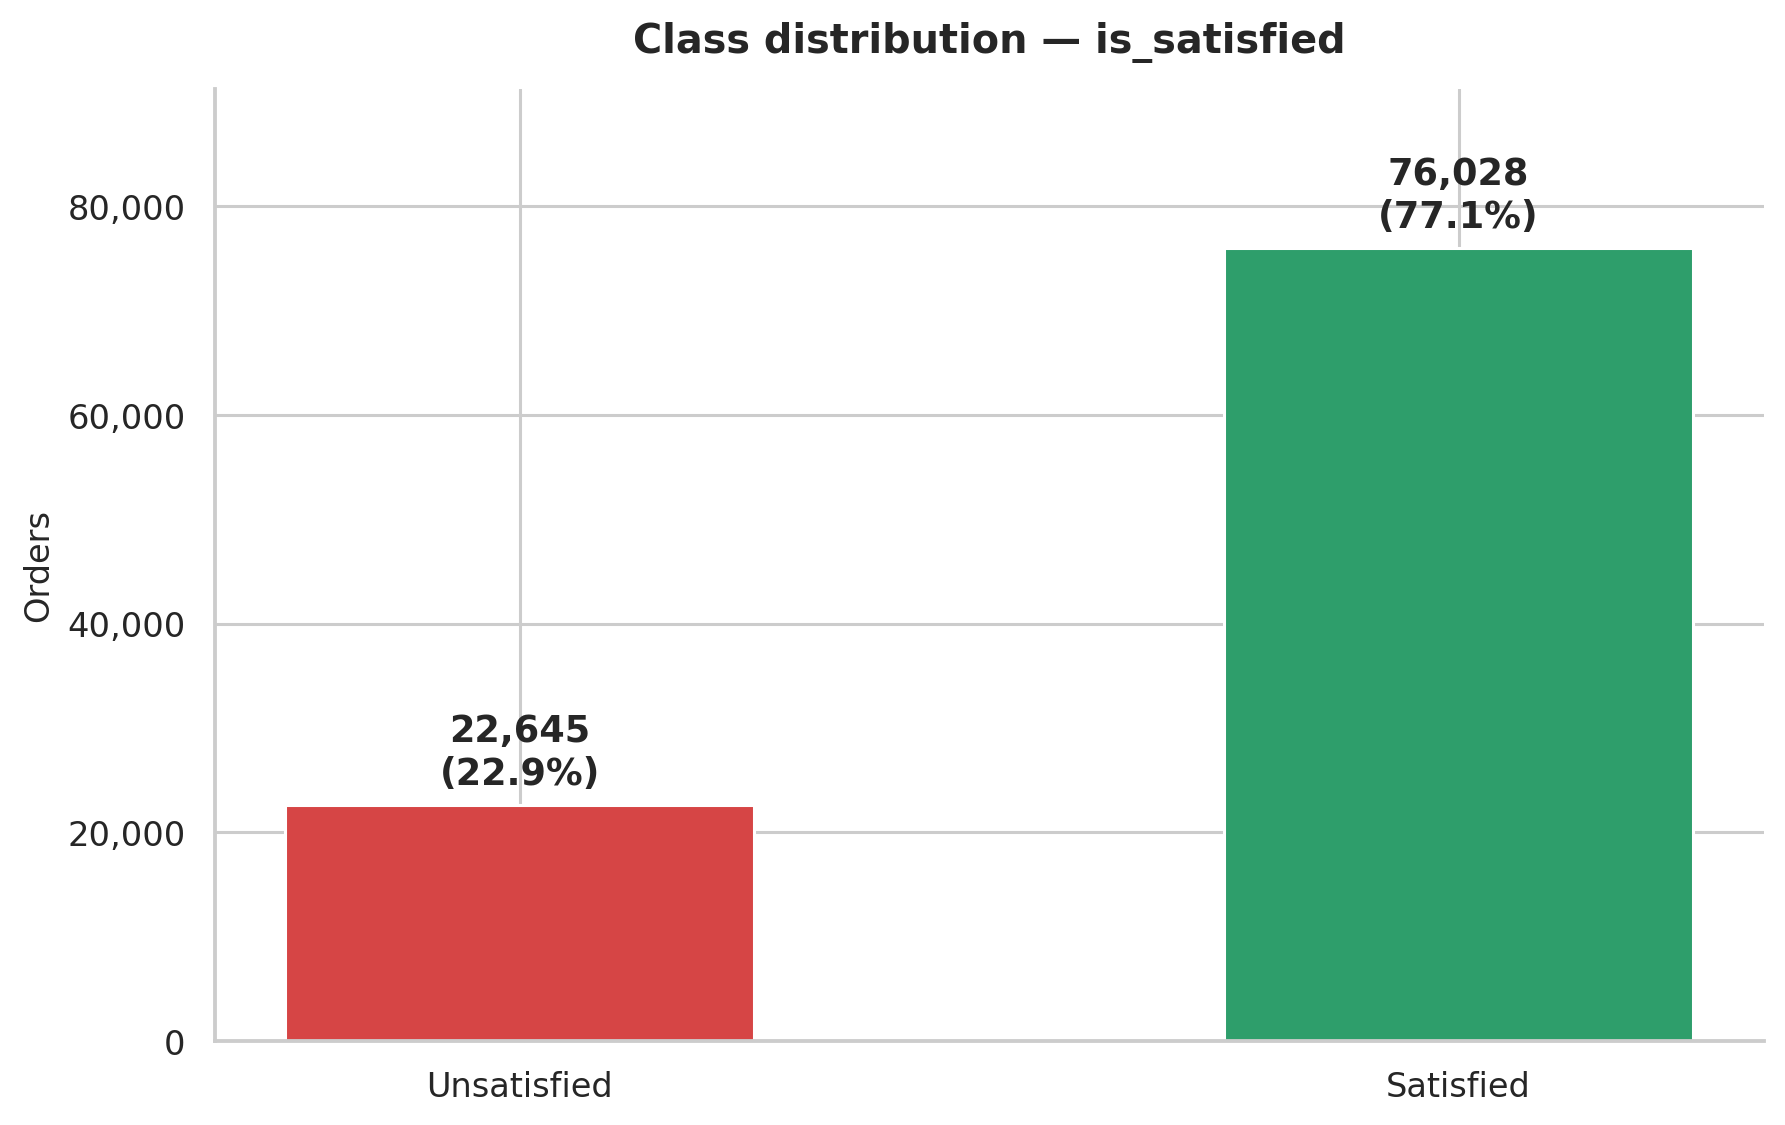

In [16]:
# Chart 1 — class balance
fig, ax = new_fig(8, 5)
bars = ax.bar(['Unsatisfied', 'Satisfied'], class_table['Orders'], color=[C['red'], C['green']], width=.5)
ax.bar_label(bars, labels=[f'{n:,}\n({p:.1f}%)' for n, p in zip(class_table['Orders'], class_table['Share %'])],
             padding=4, fontweight='bold')
ax.set_title('Class distribution — is_satisfied')
ax.set_ylabel('Orders'); ax.yaxis.set_major_formatter(fmt_int)
ax.set_ylim(0, class_table['Orders'].max() * 1.2)
plt.show()

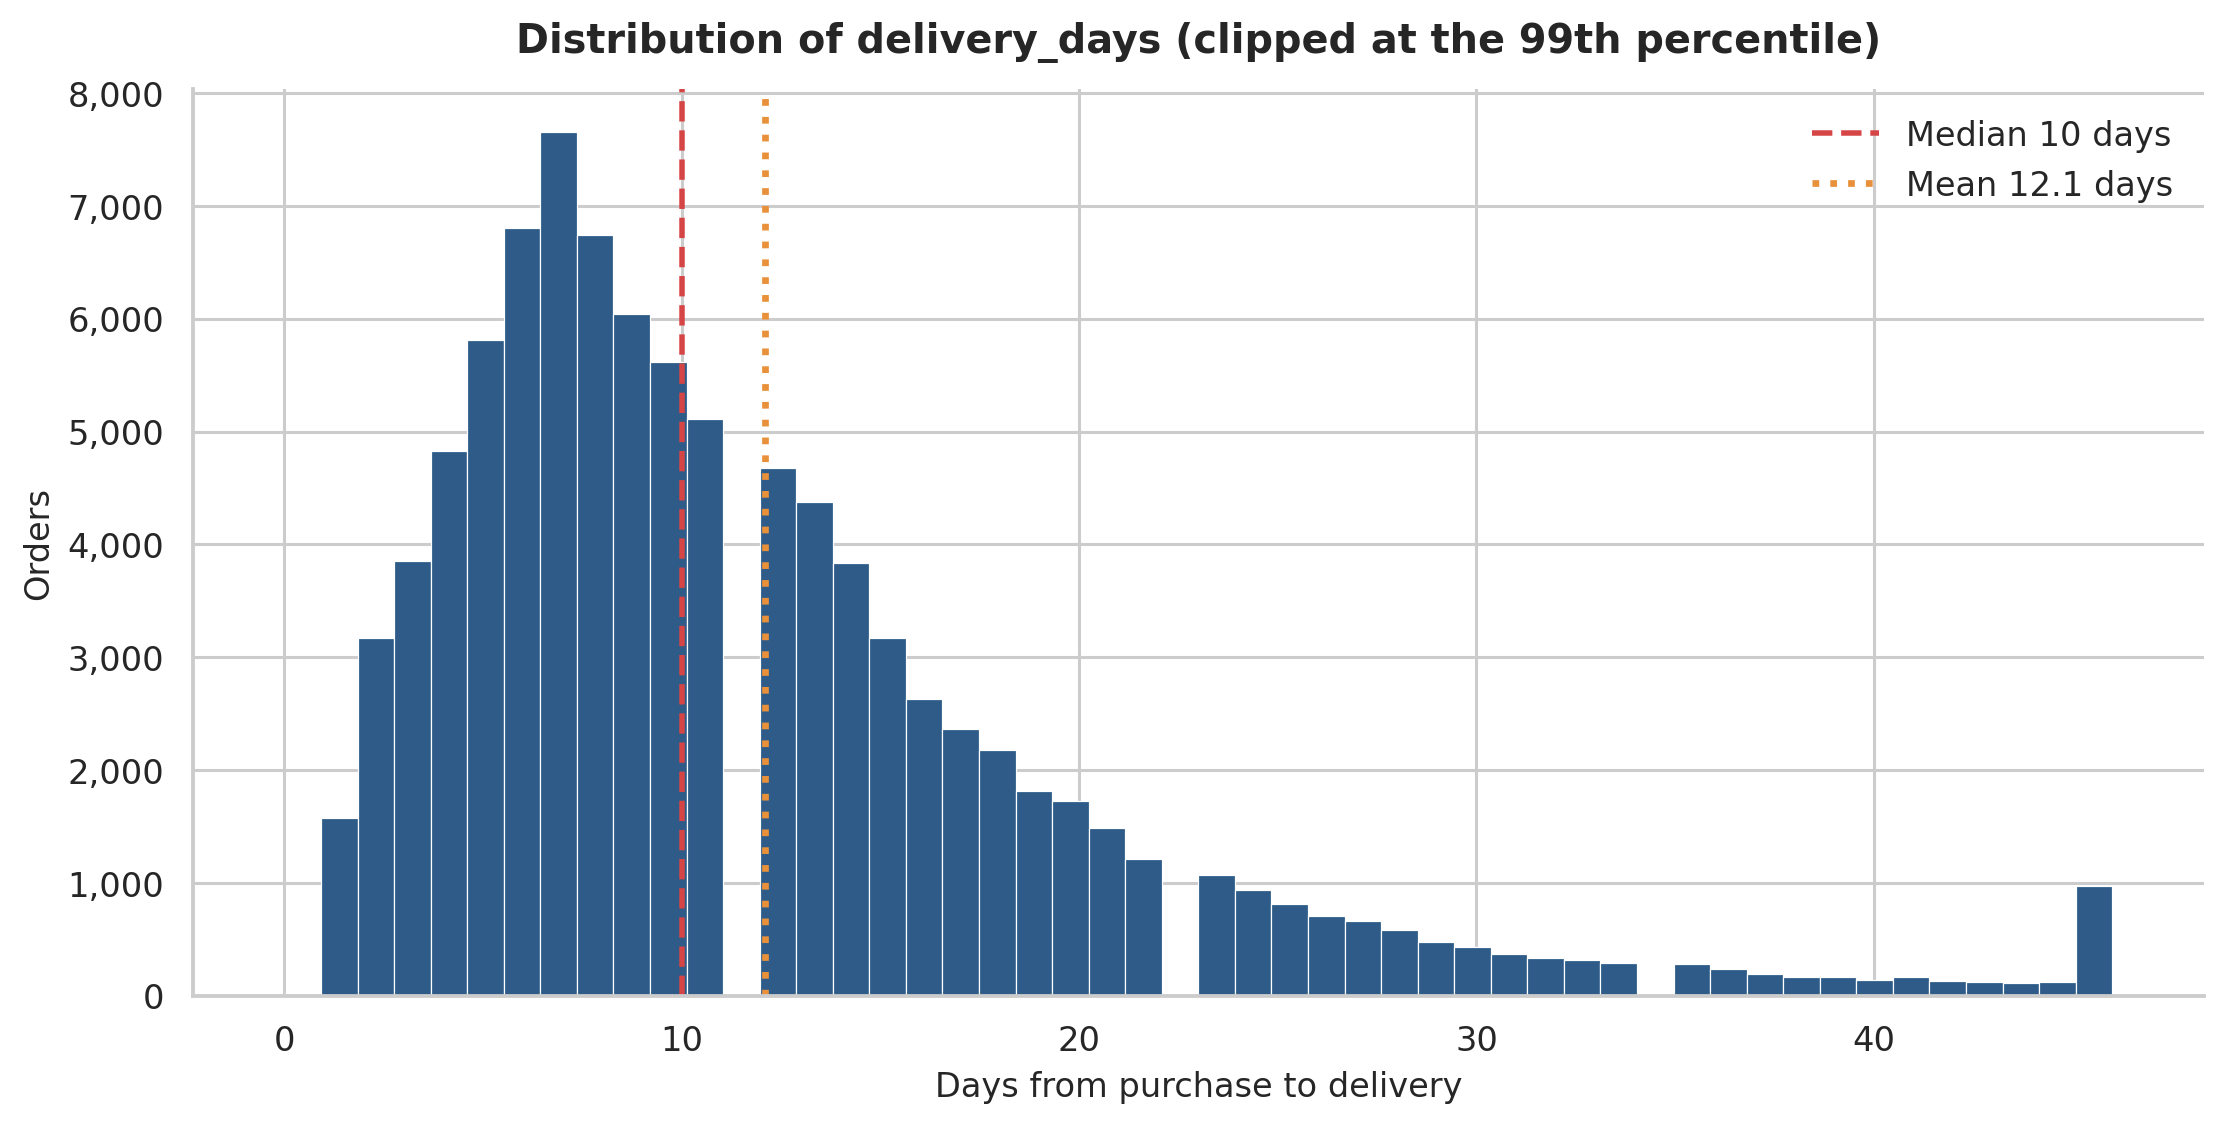

In [17]:
# Chart 2 — delivery_days distribution
fig, ax = new_fig(10, 5)
ax.hist(dd.clip(0, dd.quantile(.99)), bins=50, color=C['blue'], edgecolor='white', linewidth=.4)
ax.axvline(dd.median(), color=C['red'], ls='--', lw=1.8, label=f'Median {dd.median():.0f} days')
ax.axvline(dd.mean(), color=C['orange'], ls=':', lw=2.2, label=f'Mean {dd.mean():.1f} days')
ax.set_title('Distribution of delivery_days (clipped at the 99th percentile)')
ax.set_xlabel('Days from purchase to delivery'); ax.set_ylabel('Orders'); ax.yaxis.set_major_formatter(fmt_int)
ax.legend()
plt.show()

### 4.3 — Leakage rules
* **Satisfaction model:** uses checkout data plus delivery outcome (delay, late flag). All of it is known *before* the customer writes a review. Review text and score are excluded.
* **Delivery-time model:** only data known at checkout. Delivery date, delay and late flag are excluded because they contain the answer.
* Only **delivered** orders are modelled, so `delivery_days` and `is_late` are real values and never imputed.

## Part 5 — Exploratory Data Analysis
One chart per figure, so nothing is squeezed and no labels collide. Numbers quoted in the "Key takeaways" cell are computed from the data.

### 5.1 — Numerical Distributions

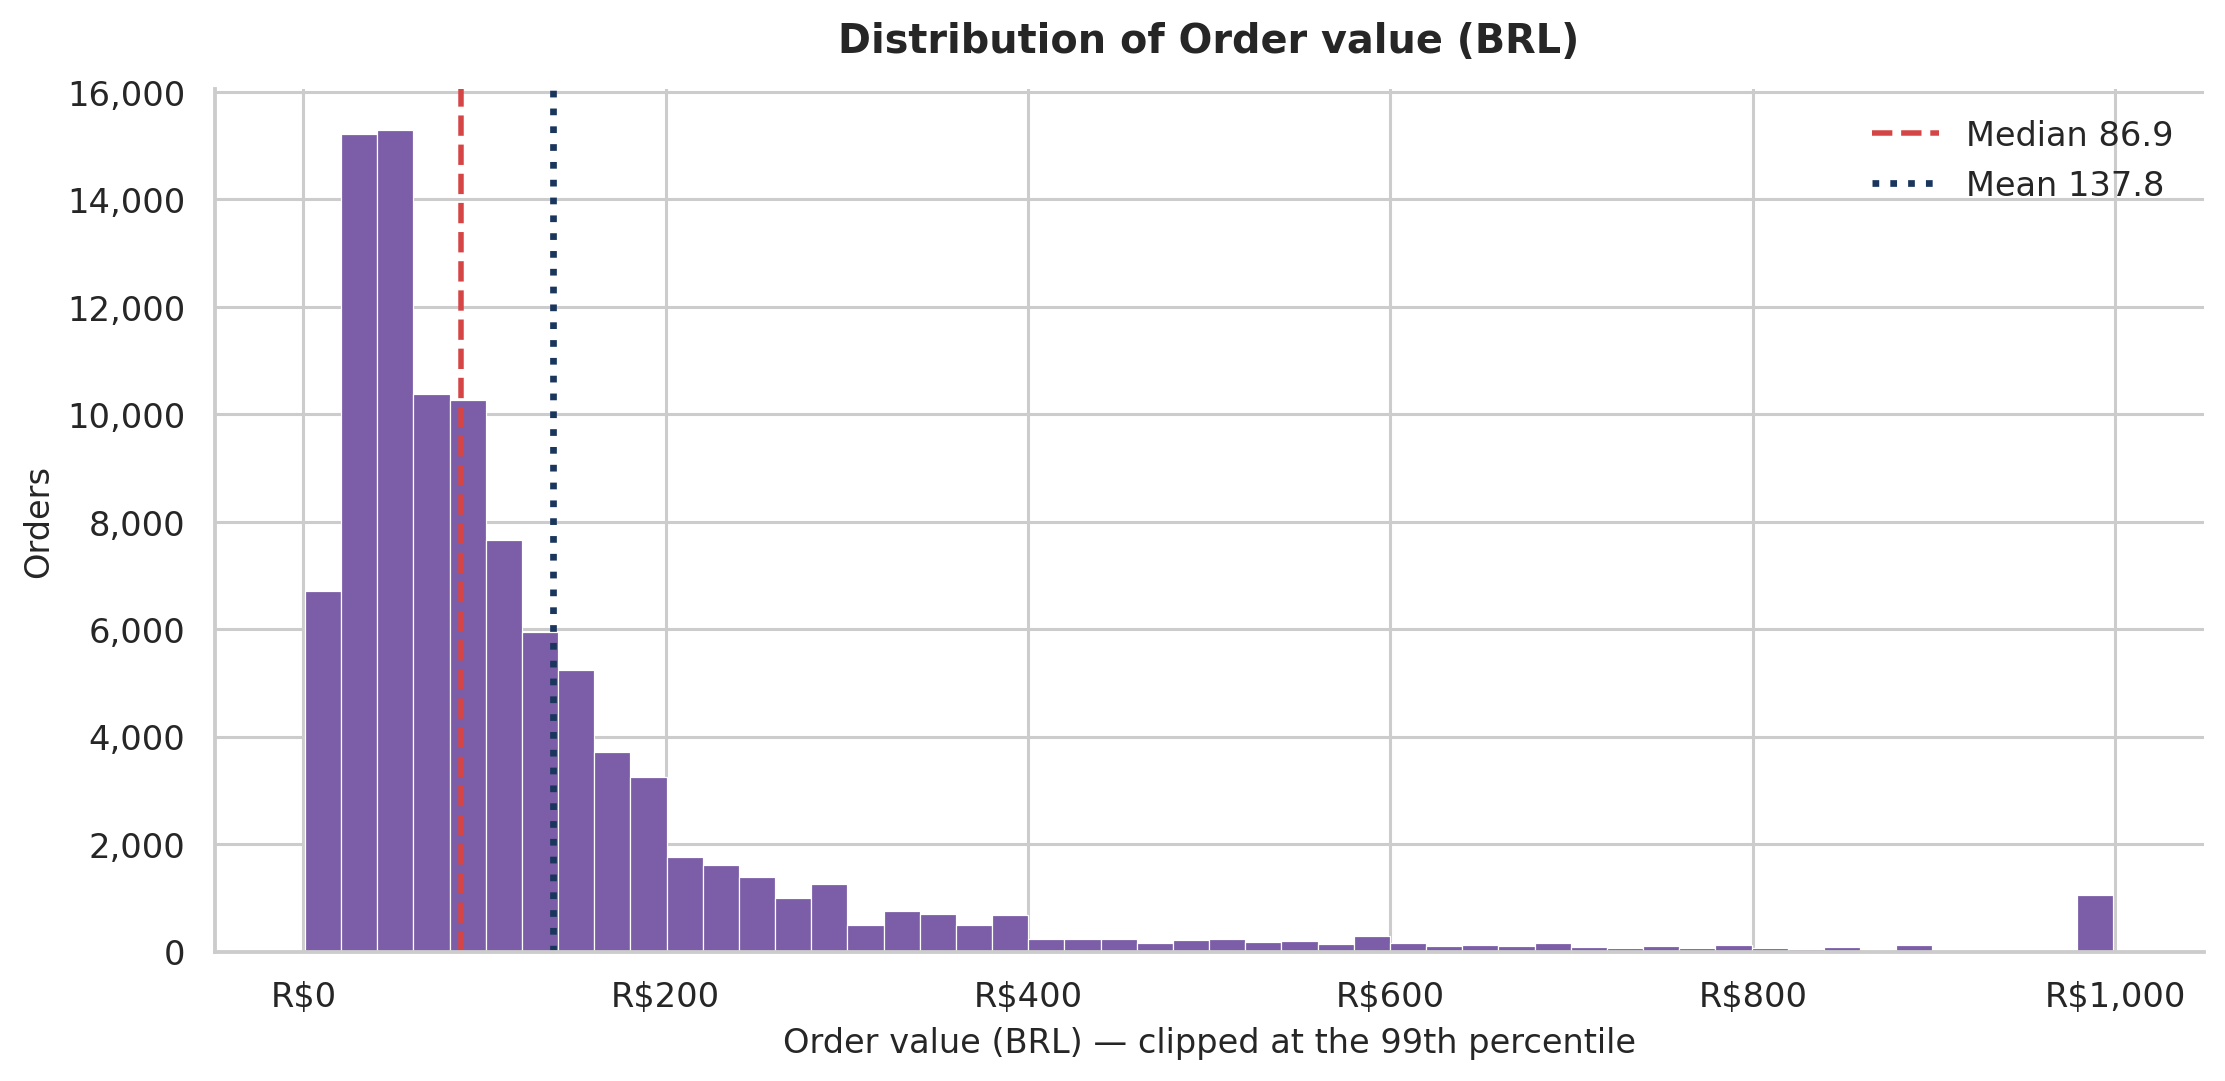

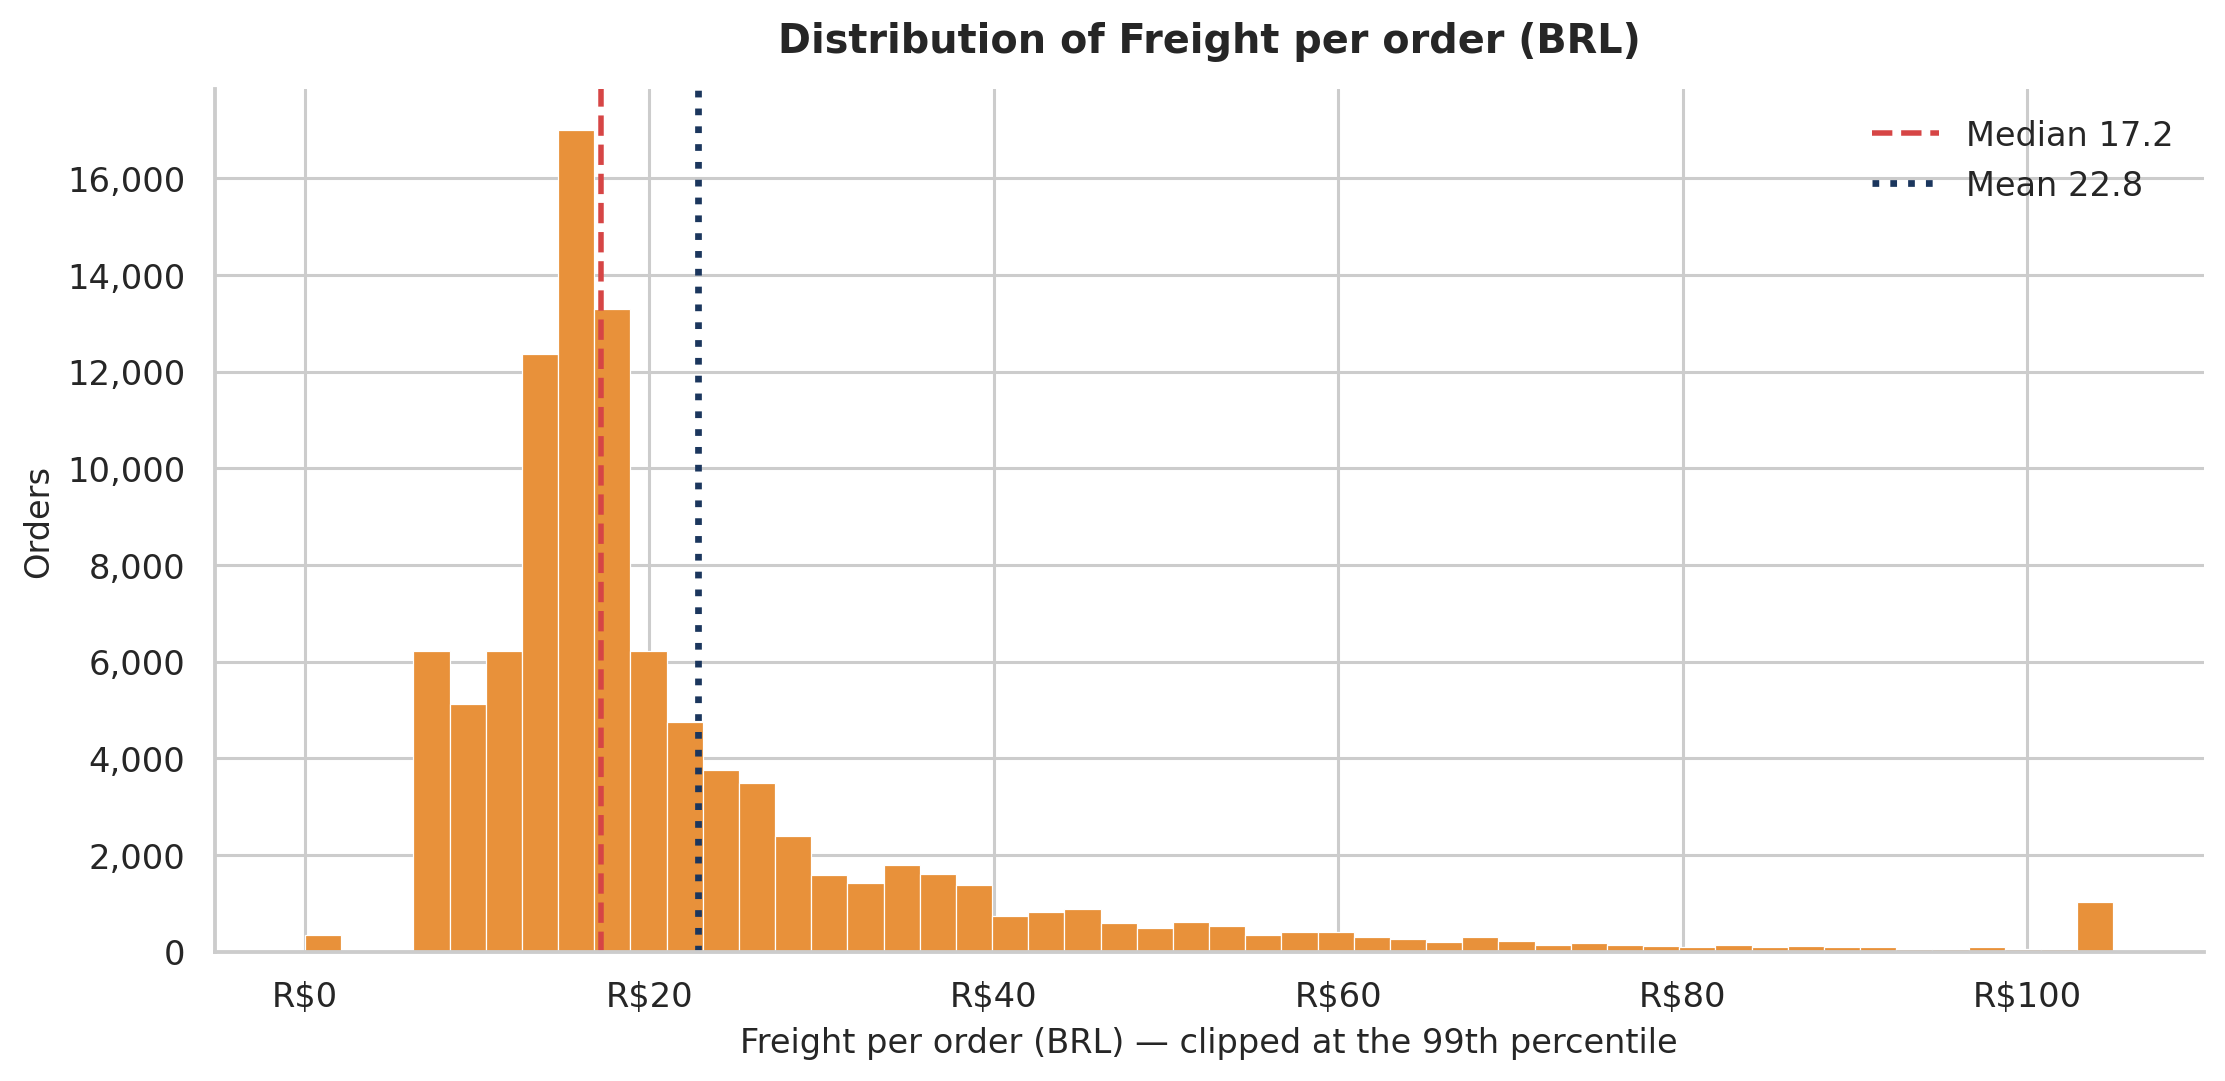

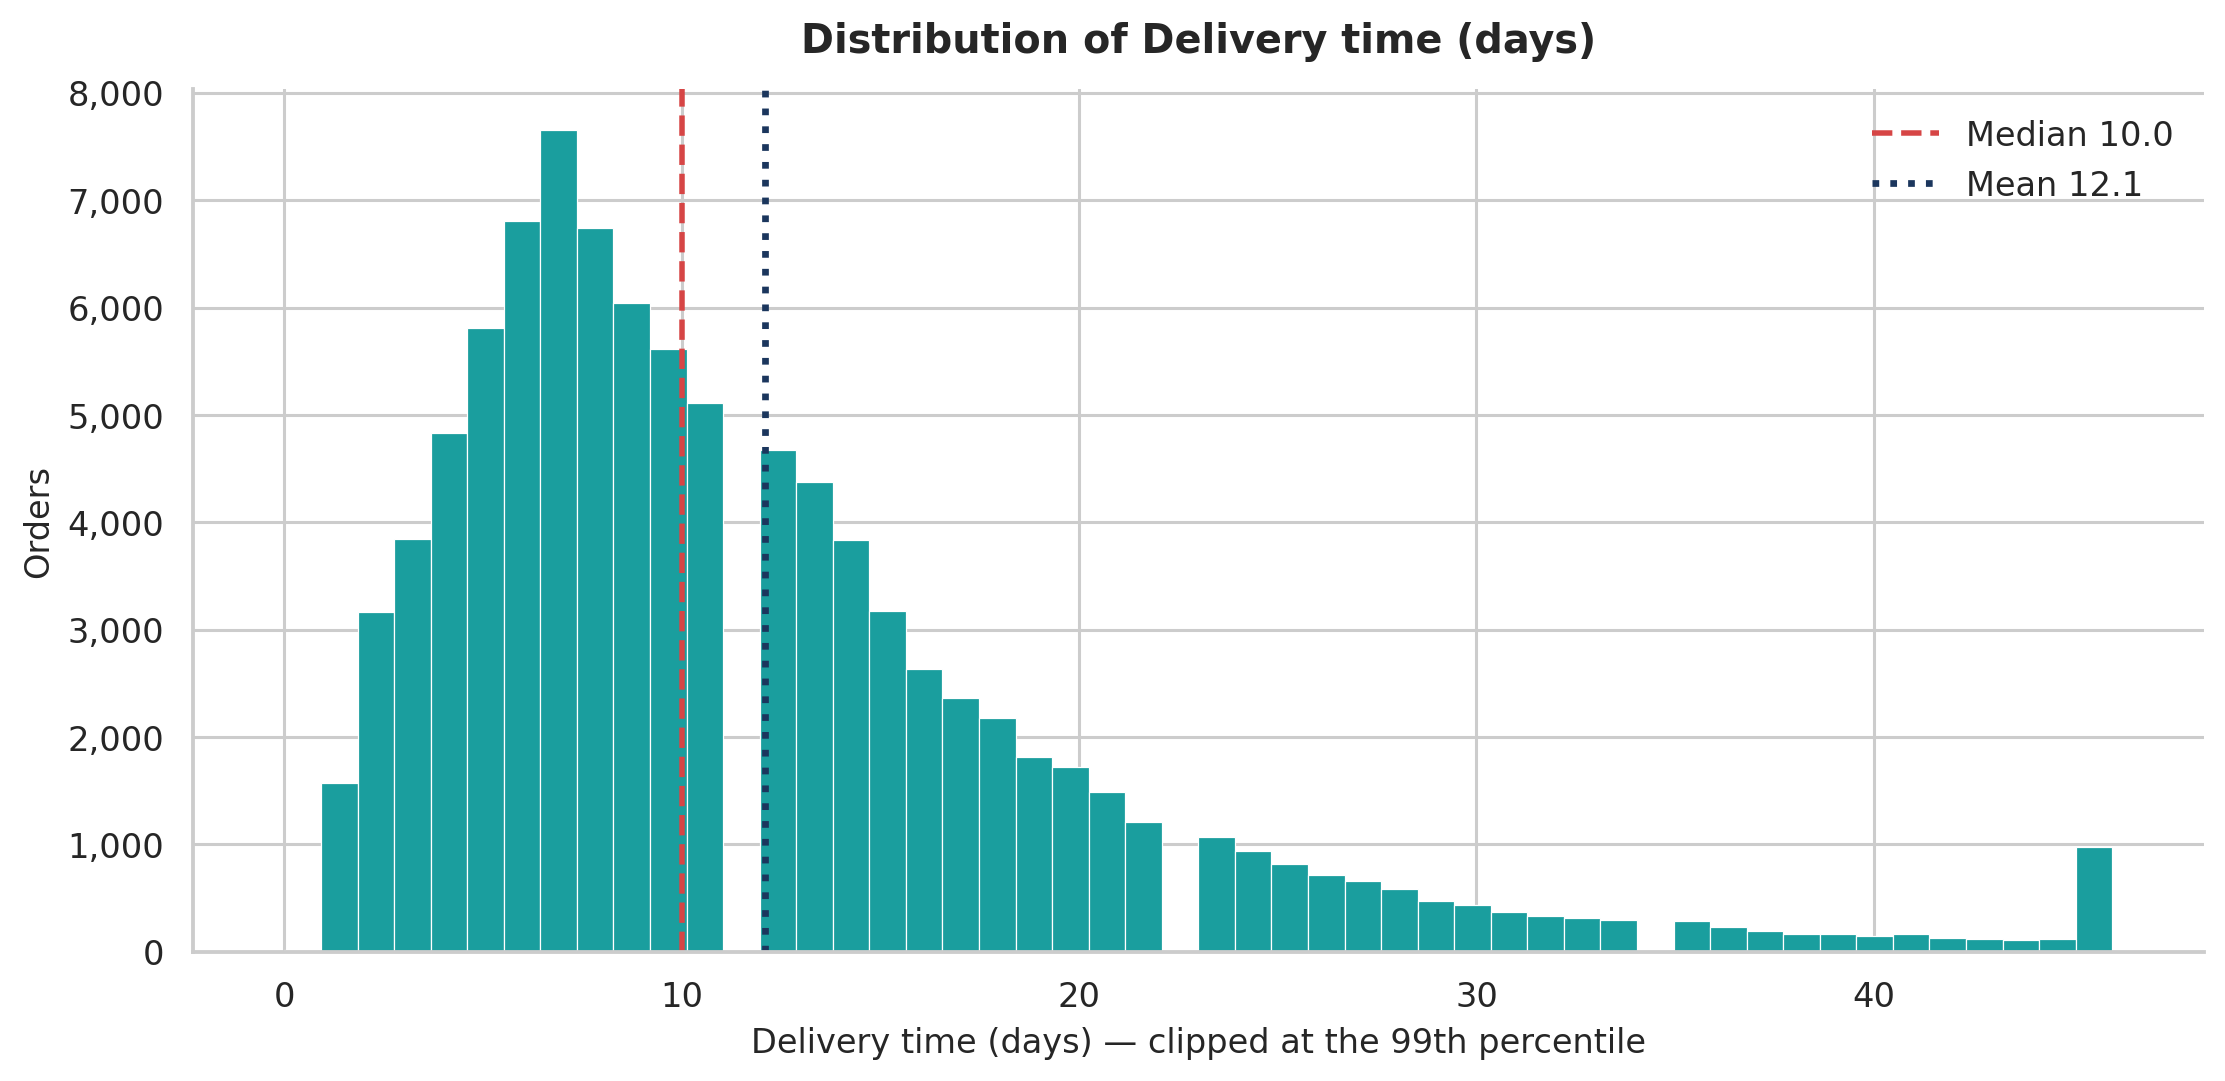

Feature,count,mean,std,min,50%,90%,99%,max
total_price,"98,666.00",137.75,210.65,0.85,86.90,269.90,998.90,"13,440.00"
total_freight,"98,666.00",22.82,21.65,0.00,17.17,39.50,104.98,"1,794.96"
delivery_days,"96,476.00",12.09,9.55,0.00,10.00,23.00,46.00,209.00


In [18]:
def money(v):
    return f'R${v / 1e6:.2f}M' if abs(v) >= 1e6 else f'R${v / 1e3:.0f}K' if abs(v) >= 1e3 else f'R${v:.0f}'
fmt_money = mticker.FuncFormatter(lambda x, _: money(x))

specs = [('total_price', 'Order value (BRL)', C['purple'], fmt_brl),
         ('total_freight', 'Freight per order (BRL)', C['orange'], fmt_brl),
         ('delivery_days', 'Delivery time (days)', C['teal'], None)]

for col, label, color, fmt in specs:
    s = fact_orders[col].dropna()
    fig, ax = new_fig(10, 4.8)
    ax.hist(s.clip(upper=s.quantile(.99)), bins=50, color=color, edgecolor='white', linewidth=.4)
    ax.axvline(s.median(), color=C['red'], ls='--', lw=1.8, label=f'Median {s.median():,.1f}')
    ax.axvline(s.mean(), color=C['navy'], ls=':', lw=2.2, label=f'Mean {s.mean():,.1f}')
    ax.set_title(f'Distribution of {label}')
    ax.set_xlabel(f'{label} — clipped at the 99th percentile'); ax.set_ylabel('Orders')
    ax.yaxis.set_major_formatter(fmt_int)
    if fmt:
        ax.xaxis.set_major_formatter(fmt)
    ax.legend()
    plt.show()

show(fact_orders[['total_price', 'total_freight', 'delivery_days']].describe(percentiles=[.5, .9, .99]).T.reset_index()
     .rename(columns={'index': 'Feature'}), '📐 Summary statistics')

### 5.2 — Categories, Regions, Payments and Delivery Status

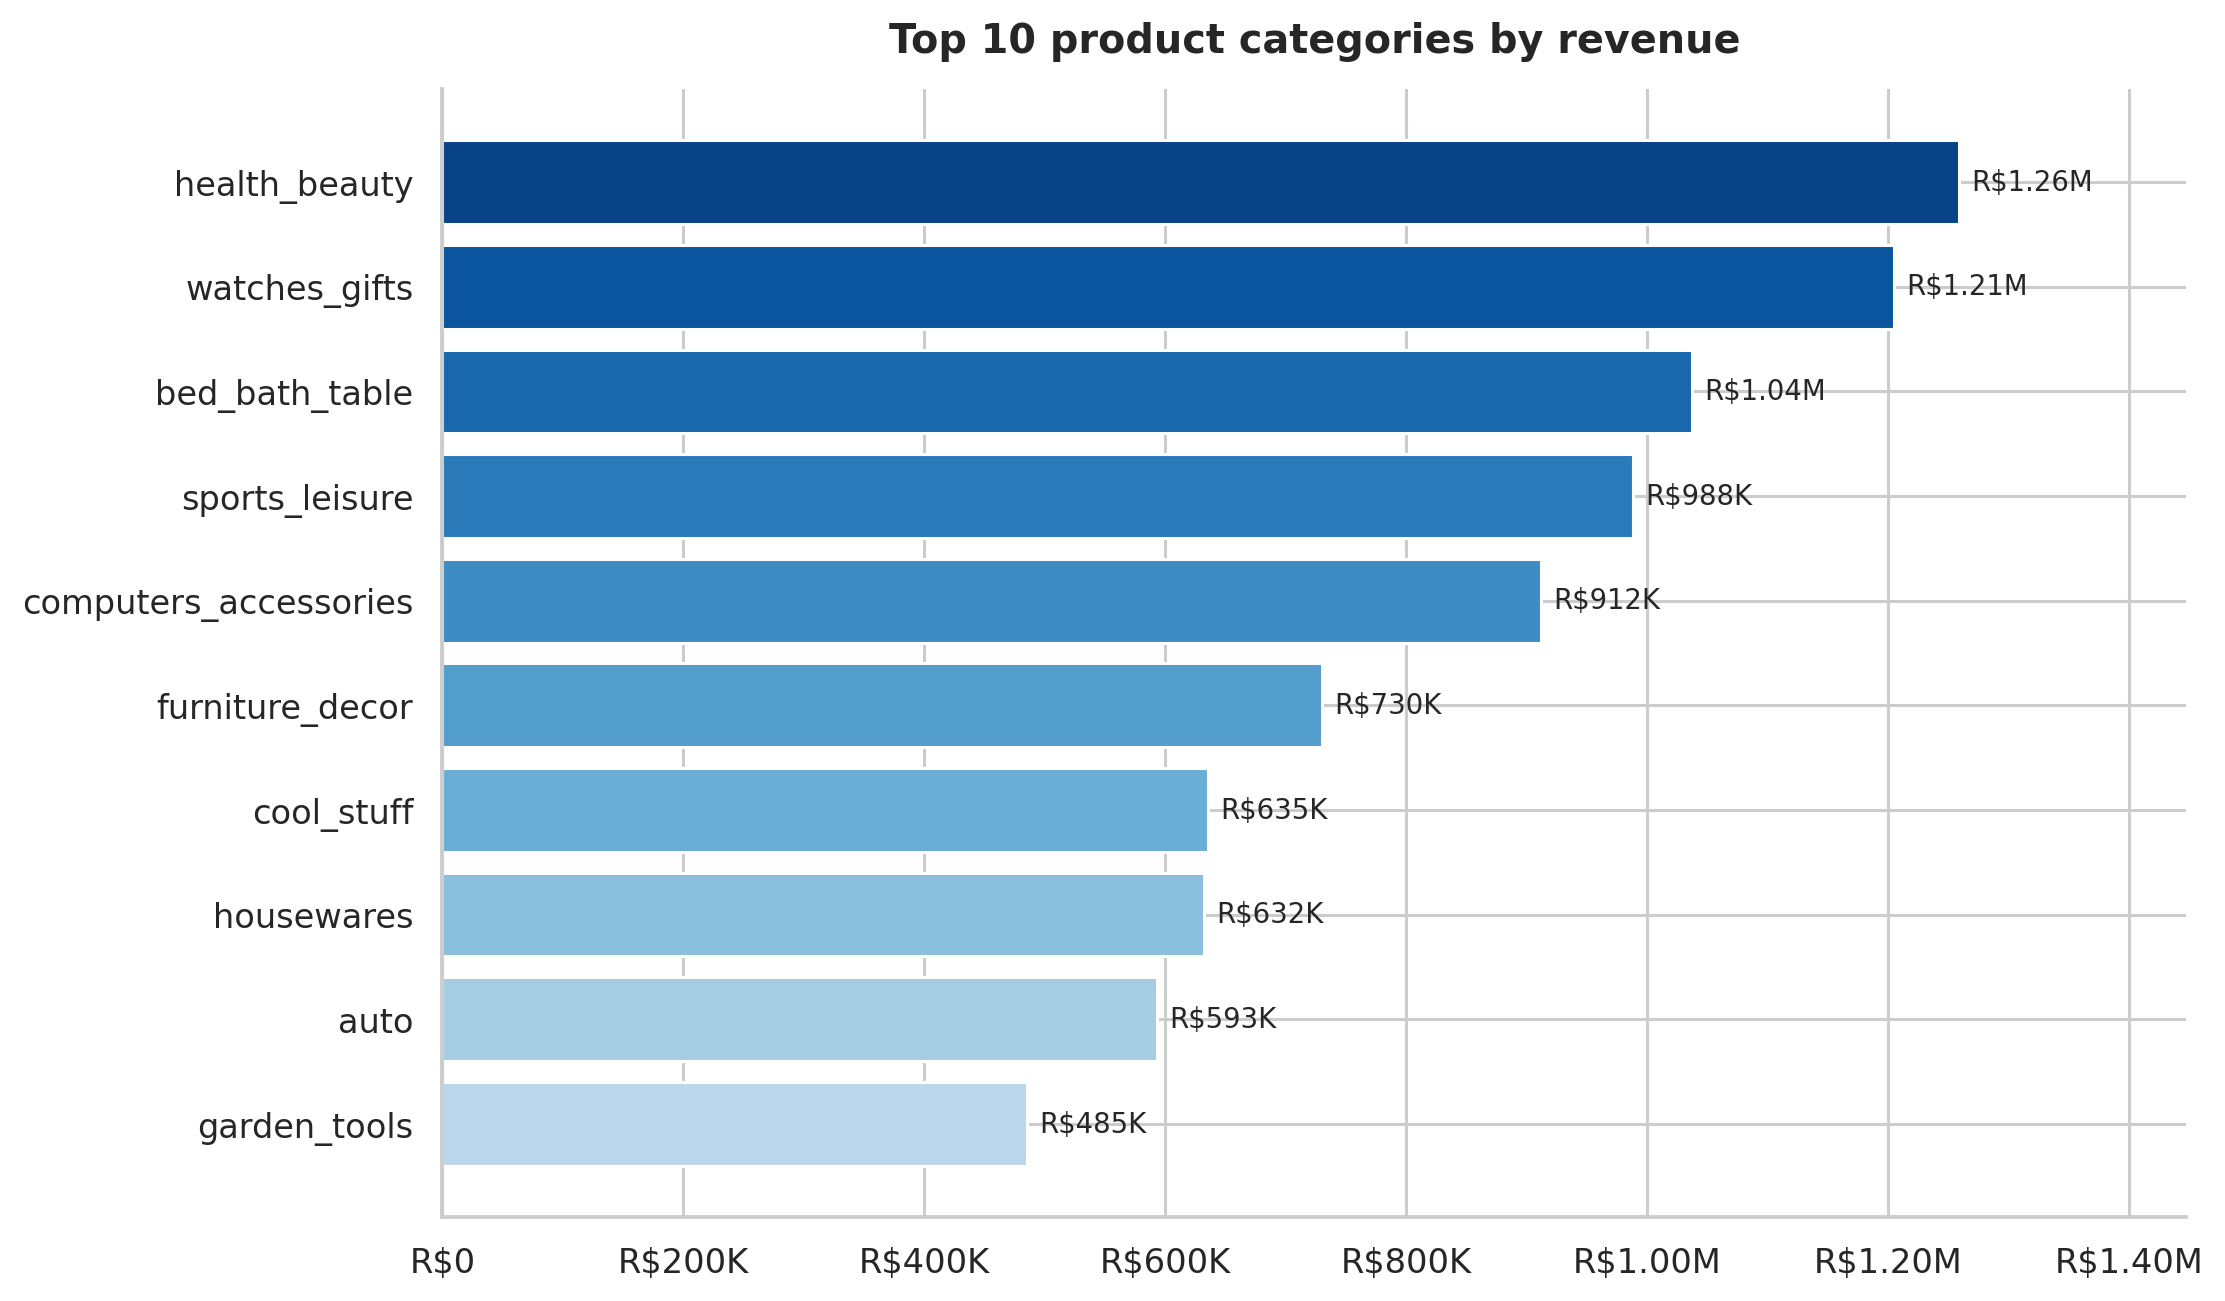

In [19]:
# Top 10 categories by revenue
cat_rev = fact_order_items.groupby('product_category_en')['price'].sum().nlargest(10).sort_values()
fig, ax = new_fig(10, 5.8)
bars = ax.barh(cat_rev.index, cat_rev.values, color=sns.color_palette('Blues', len(cat_rev) + 3)[3:])
ax.bar_label(bars, labels=[money(v) for v in cat_rev.values], padding=4, fontsize=9)
ax.set_title('Top 10 product categories by revenue')
ax.xaxis.set_major_formatter(fmt_money); ax.margins(x=.15)
plt.show()

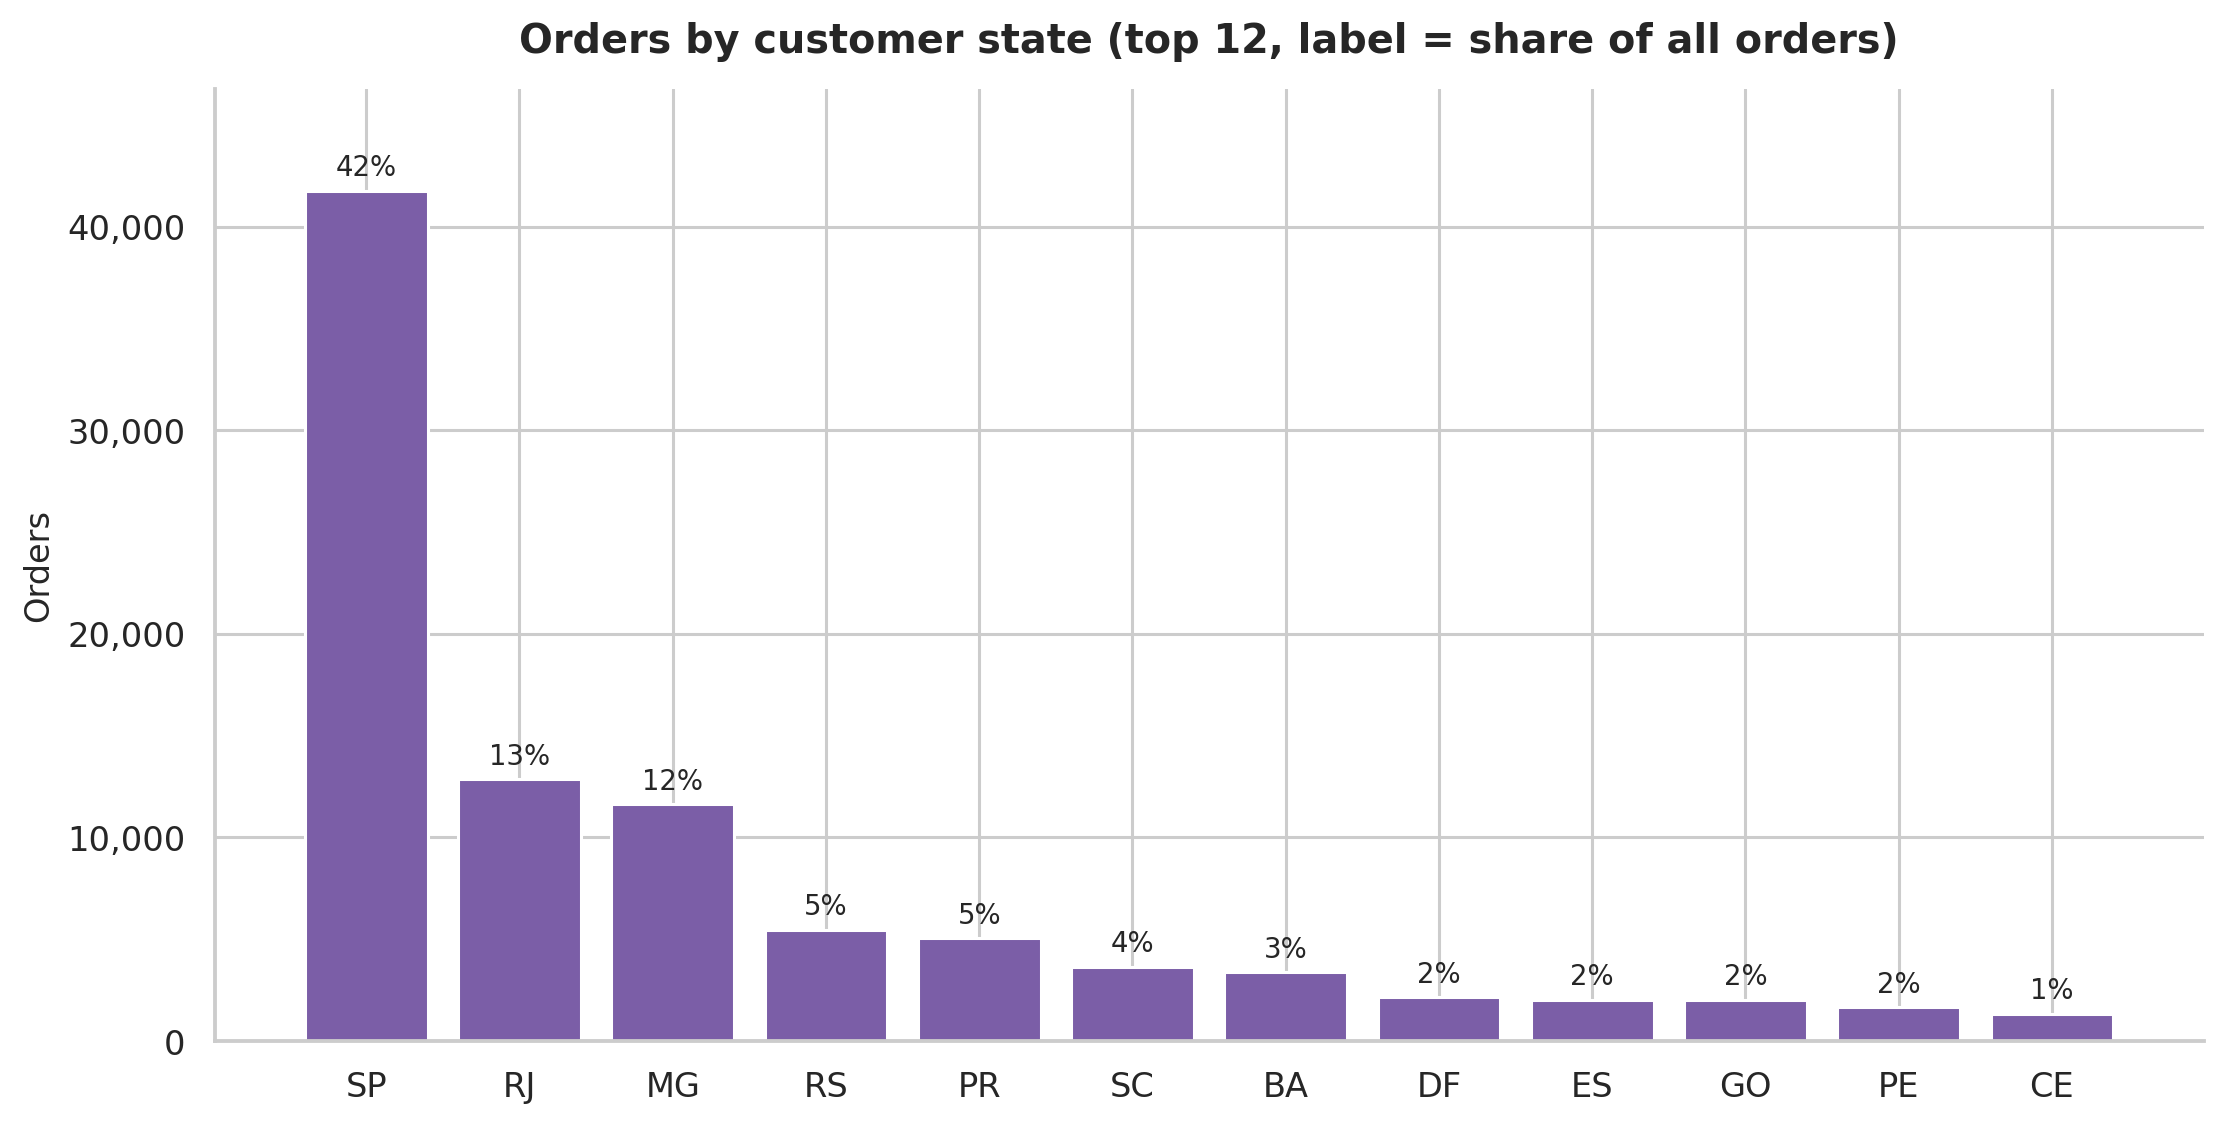

In [20]:
# Orders by customer state
state_counts = fact_orders['customer_state'].value_counts()
top = state_counts.head(12)
fig, ax = new_fig(10, 5)
bars = ax.bar(top.index, top.values, color=C['purple'])
ax.bar_label(bars, labels=[f'{v / state_counts.sum():.0%}' for v in top.values], padding=3, fontsize=9)
ax.set_title('Orders by customer state (top 12, label = share of all orders)')
ax.set_ylabel('Orders'); ax.yaxis.set_major_formatter(fmt_int); ax.margins(y=.12)
plt.show()

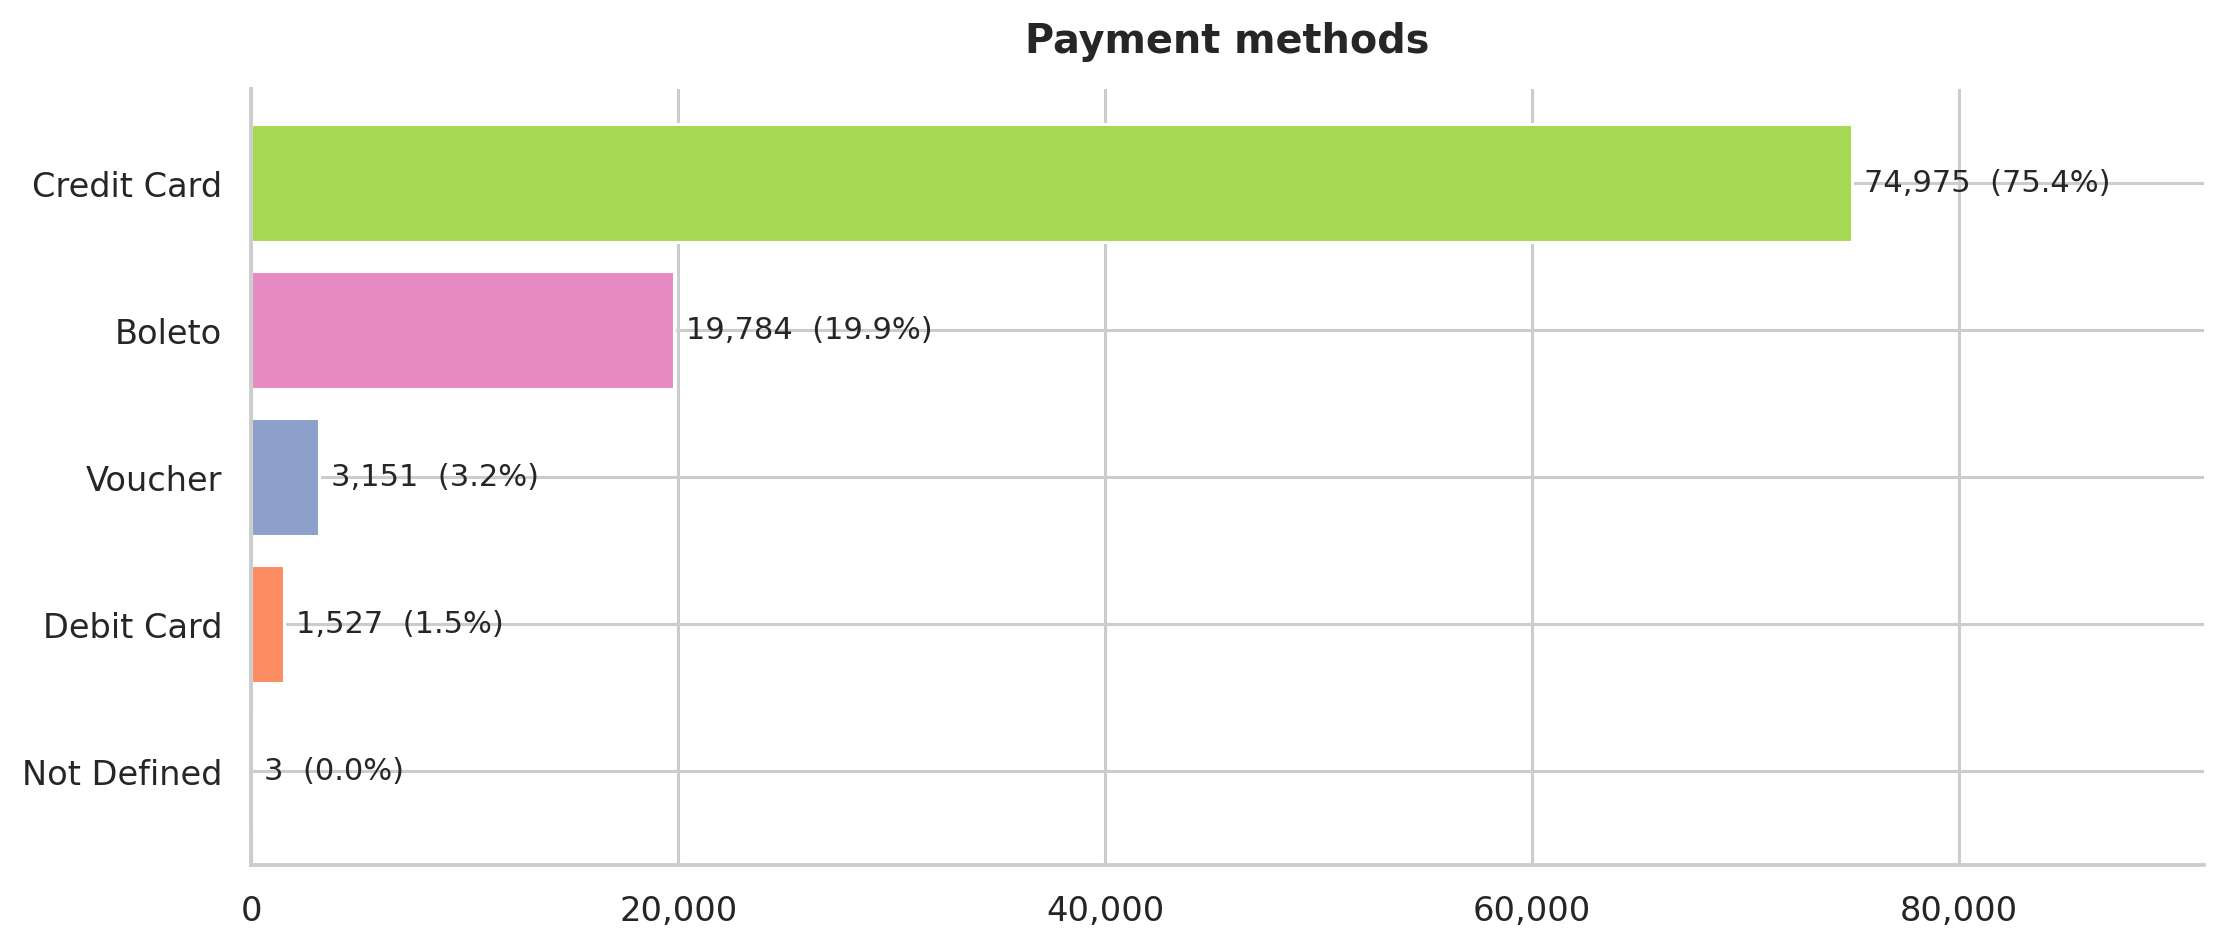

In [21]:
# Payment methods
pay = fact_orders['payment_type'].value_counts().sort_values()
fig, ax = new_fig(10, 4.2)
bars = ax.barh(pay.index.str.replace('_', ' ').str.title(), pay.values, color=sns.color_palette('Set2', len(pay)))
ax.bar_label(bars, labels=[f'{v:,}  ({v / pay.sum():.1%})' for v in pay.values], padding=4, fontsize=10)
ax.set_title('Payment methods')
ax.xaxis.set_major_formatter(fmt_int); ax.margins(x=.22)
plt.show()

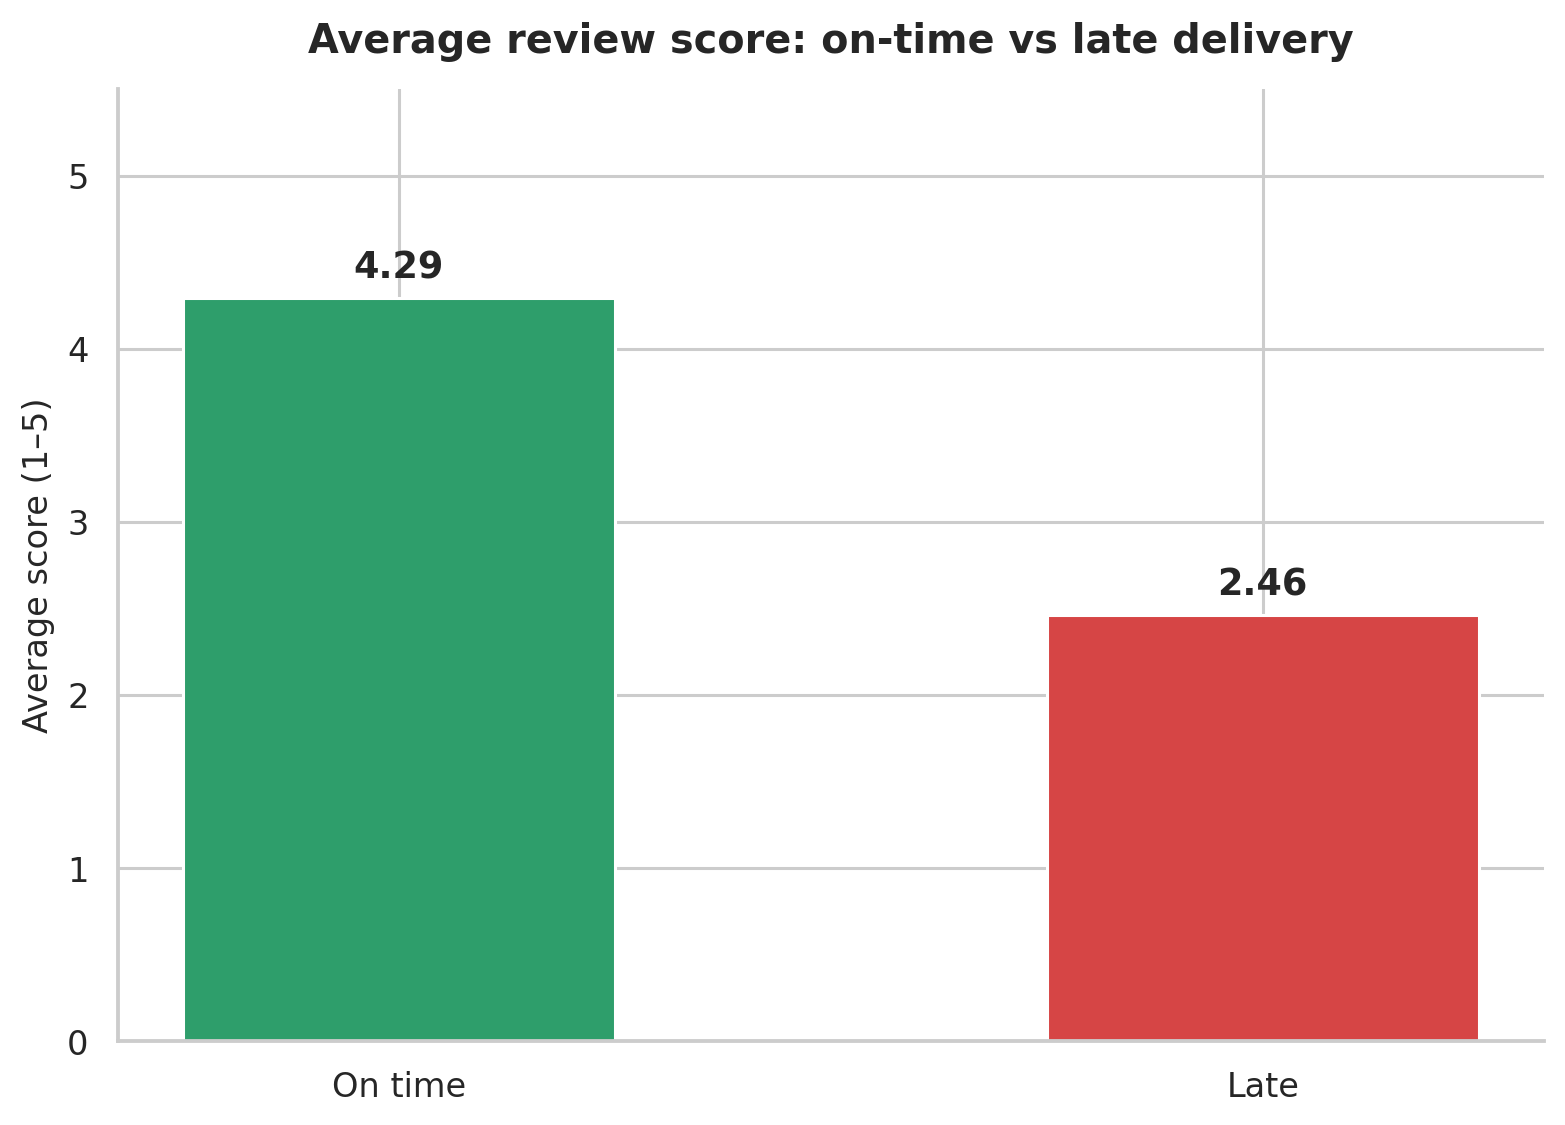

In [22]:
# Review score: on time vs late
late = fact_orders.dropna(subset=['is_late', 'review_score']).groupby('is_late')['review_score'].mean()
fig, ax = new_fig(7, 5)
bars = ax.bar(['On time' if k == 0 else 'Late' for k in late.index], late.values,
              color=[C['green'] if k == 0 else C['red'] for k in late.index], width=.5)
ax.bar_label(bars, fmt='%.2f', padding=4, fontweight='bold')
ax.set_title('Average review score: on-time vs late delivery')
ax.set_ylabel('Average score (1–5)'); ax.set_ylim(0, 5.5)
plt.show()

### 5.3 — Trends Over Time
Months with fewer than 5% of the median monthly volume (the dataset's partial start and end) are left out.

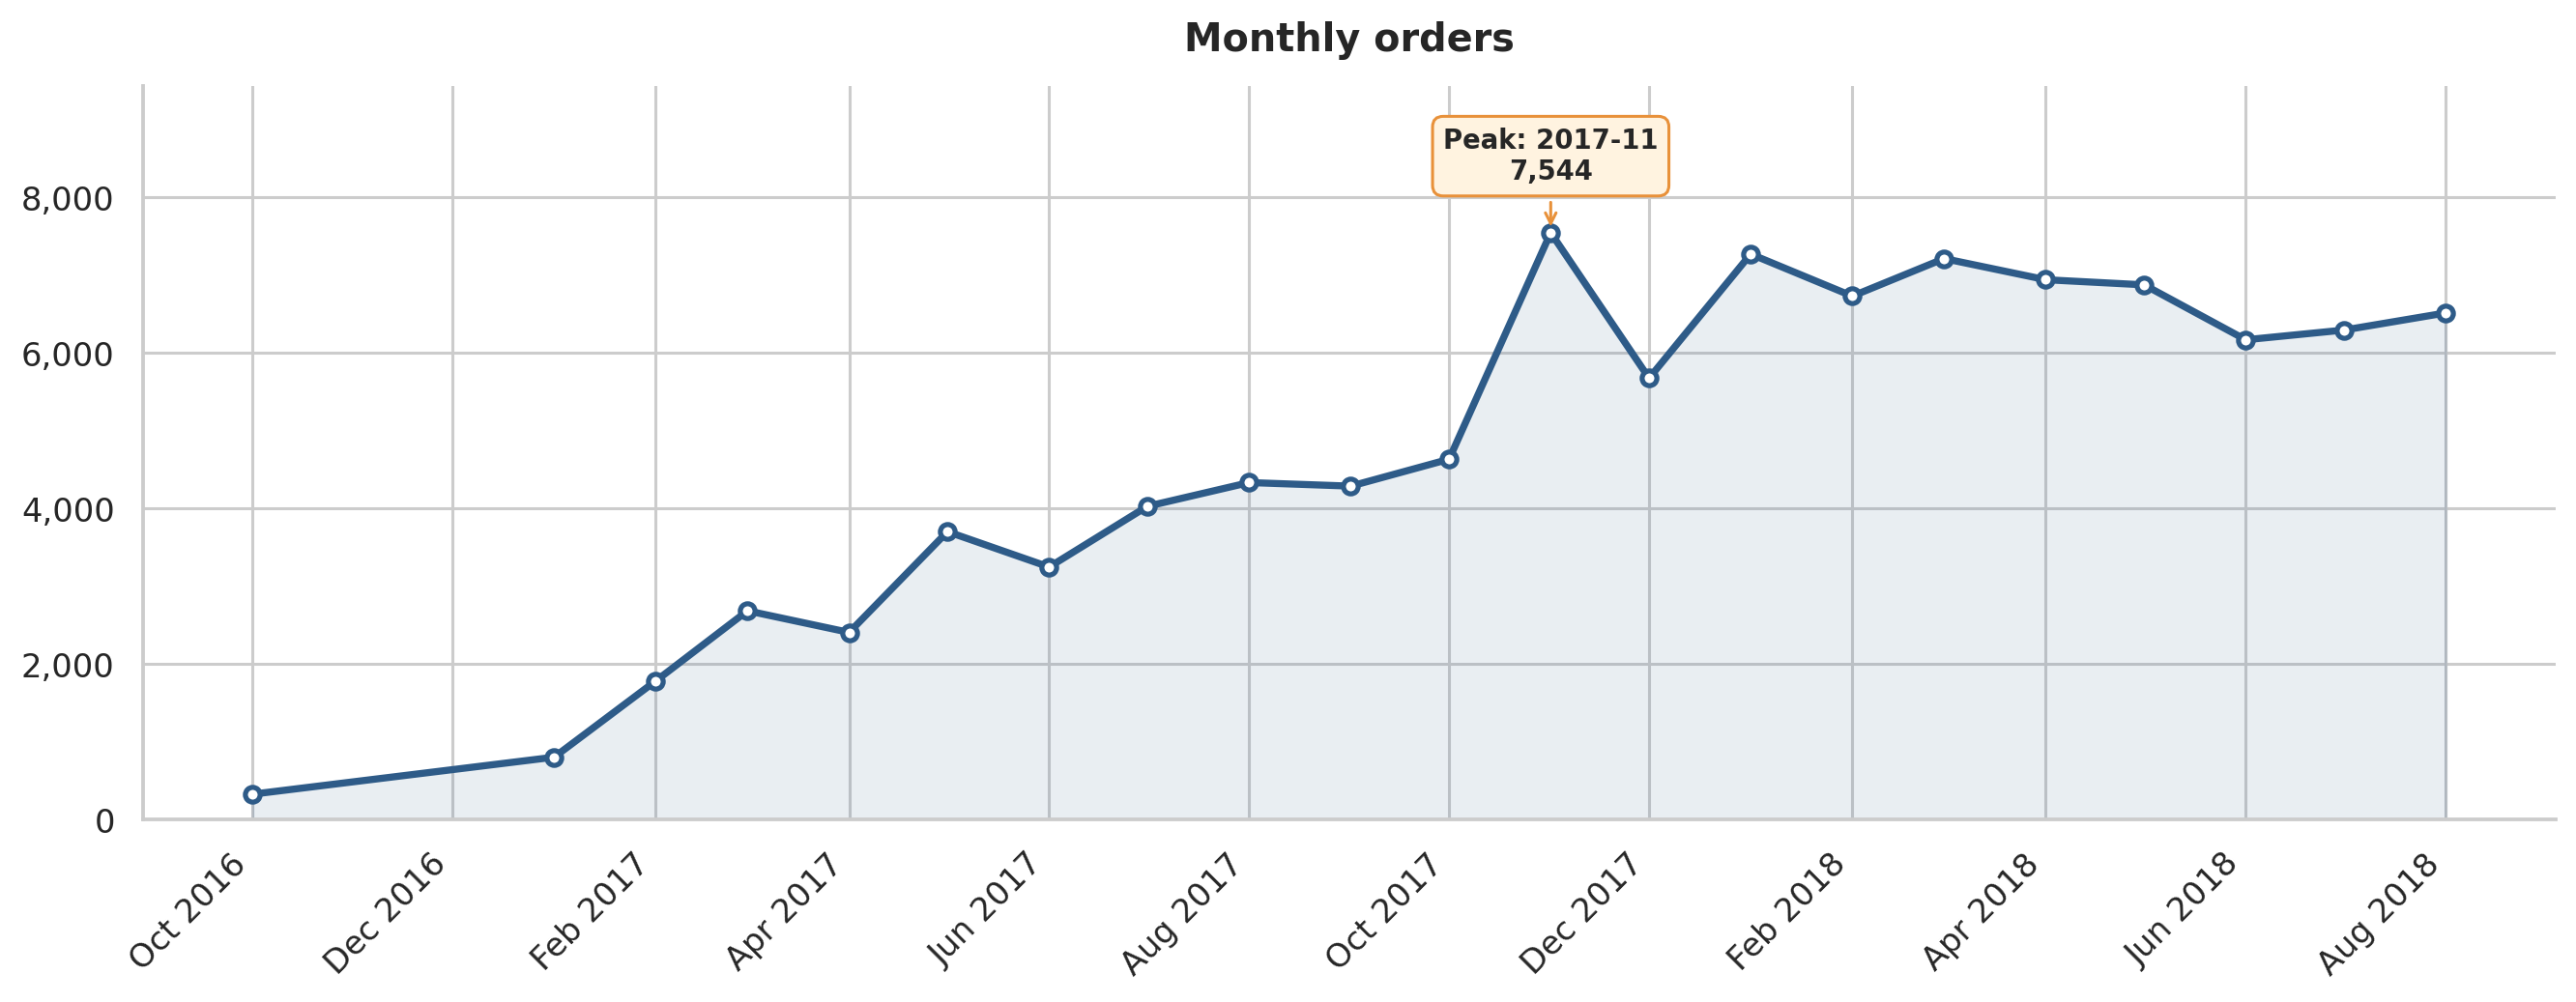

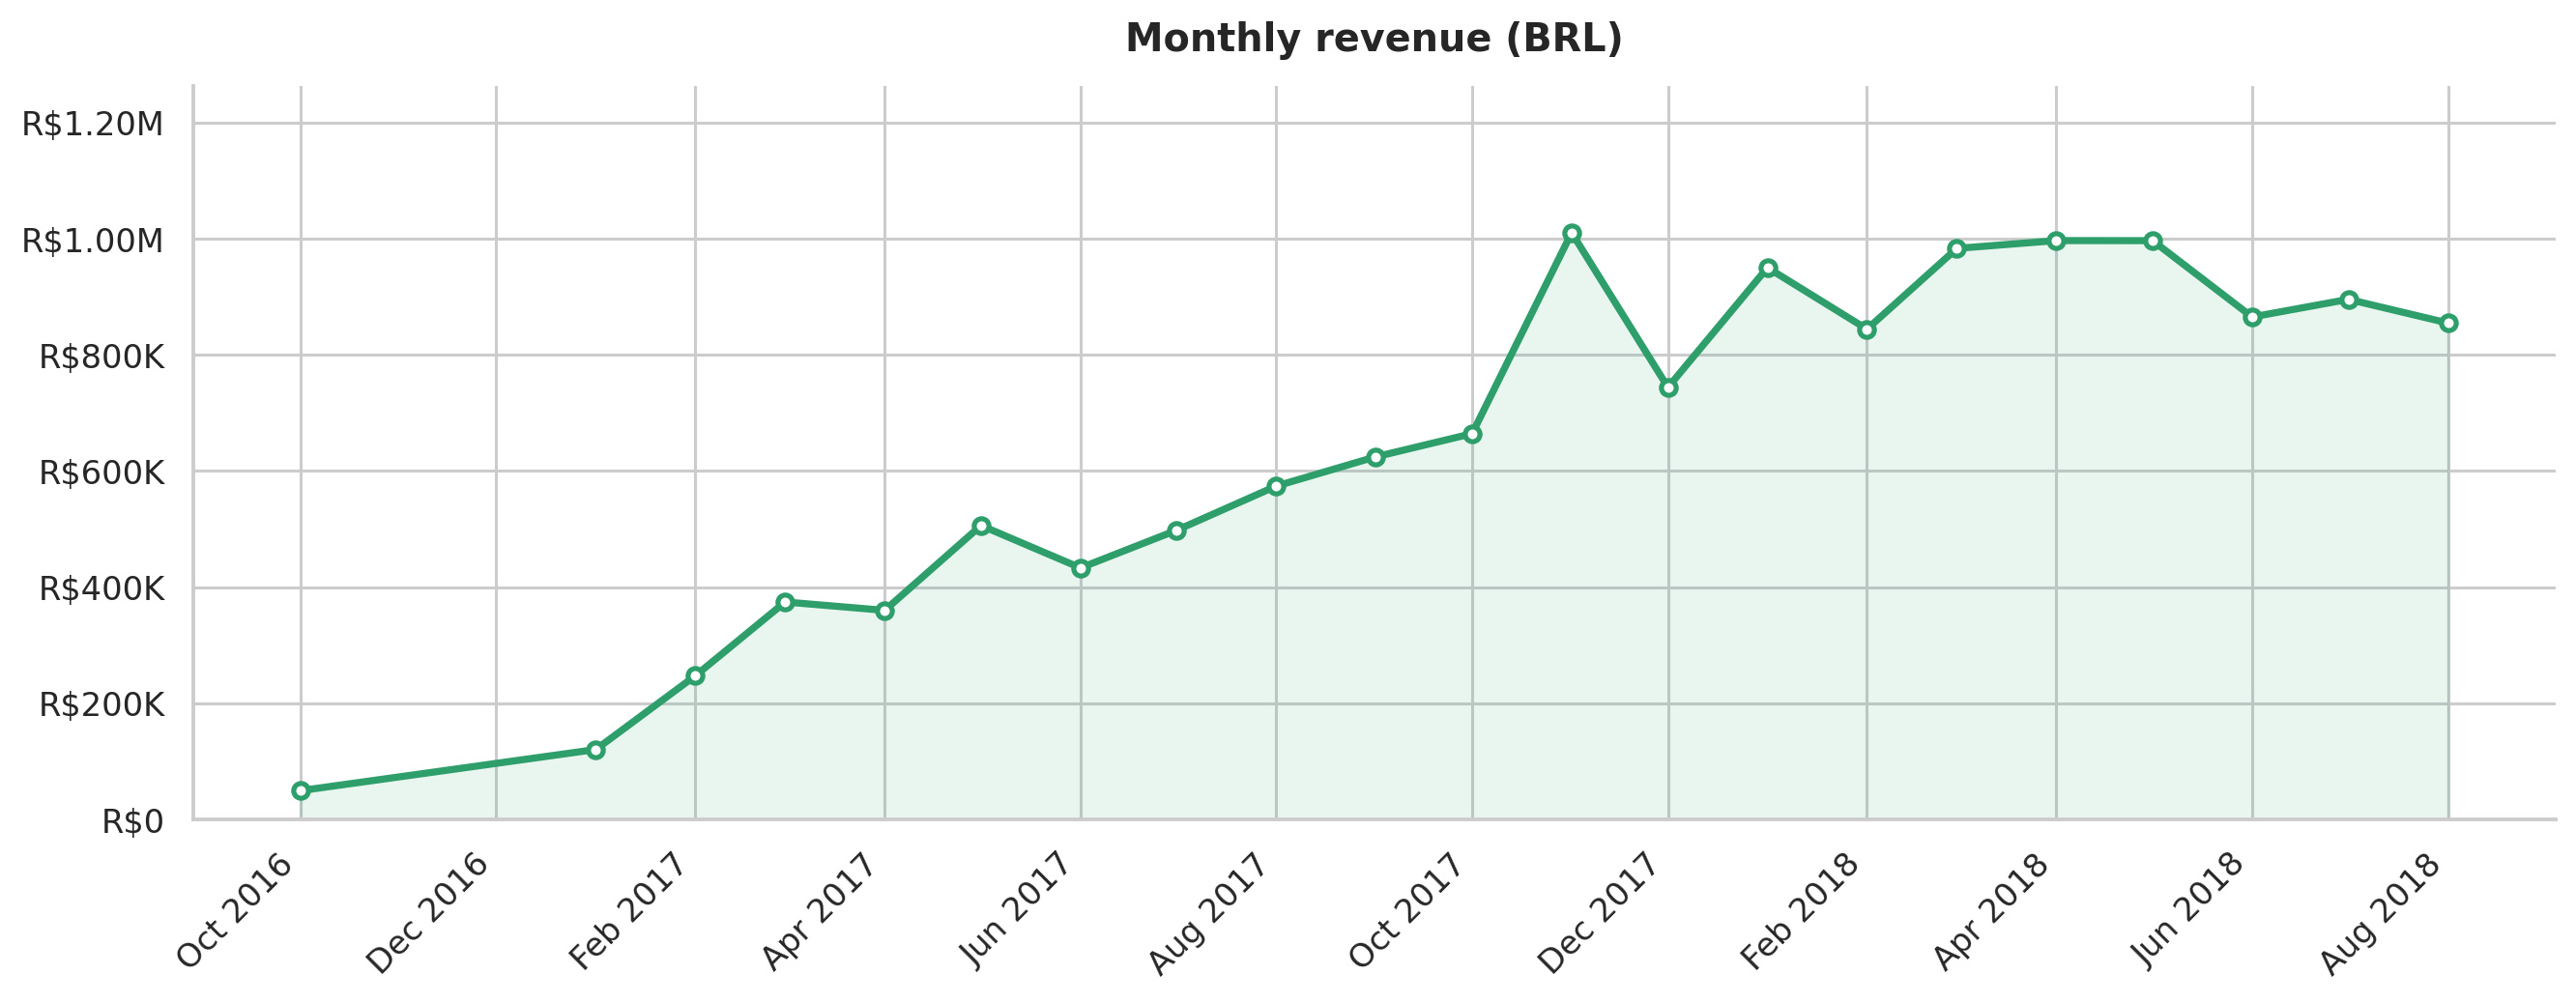

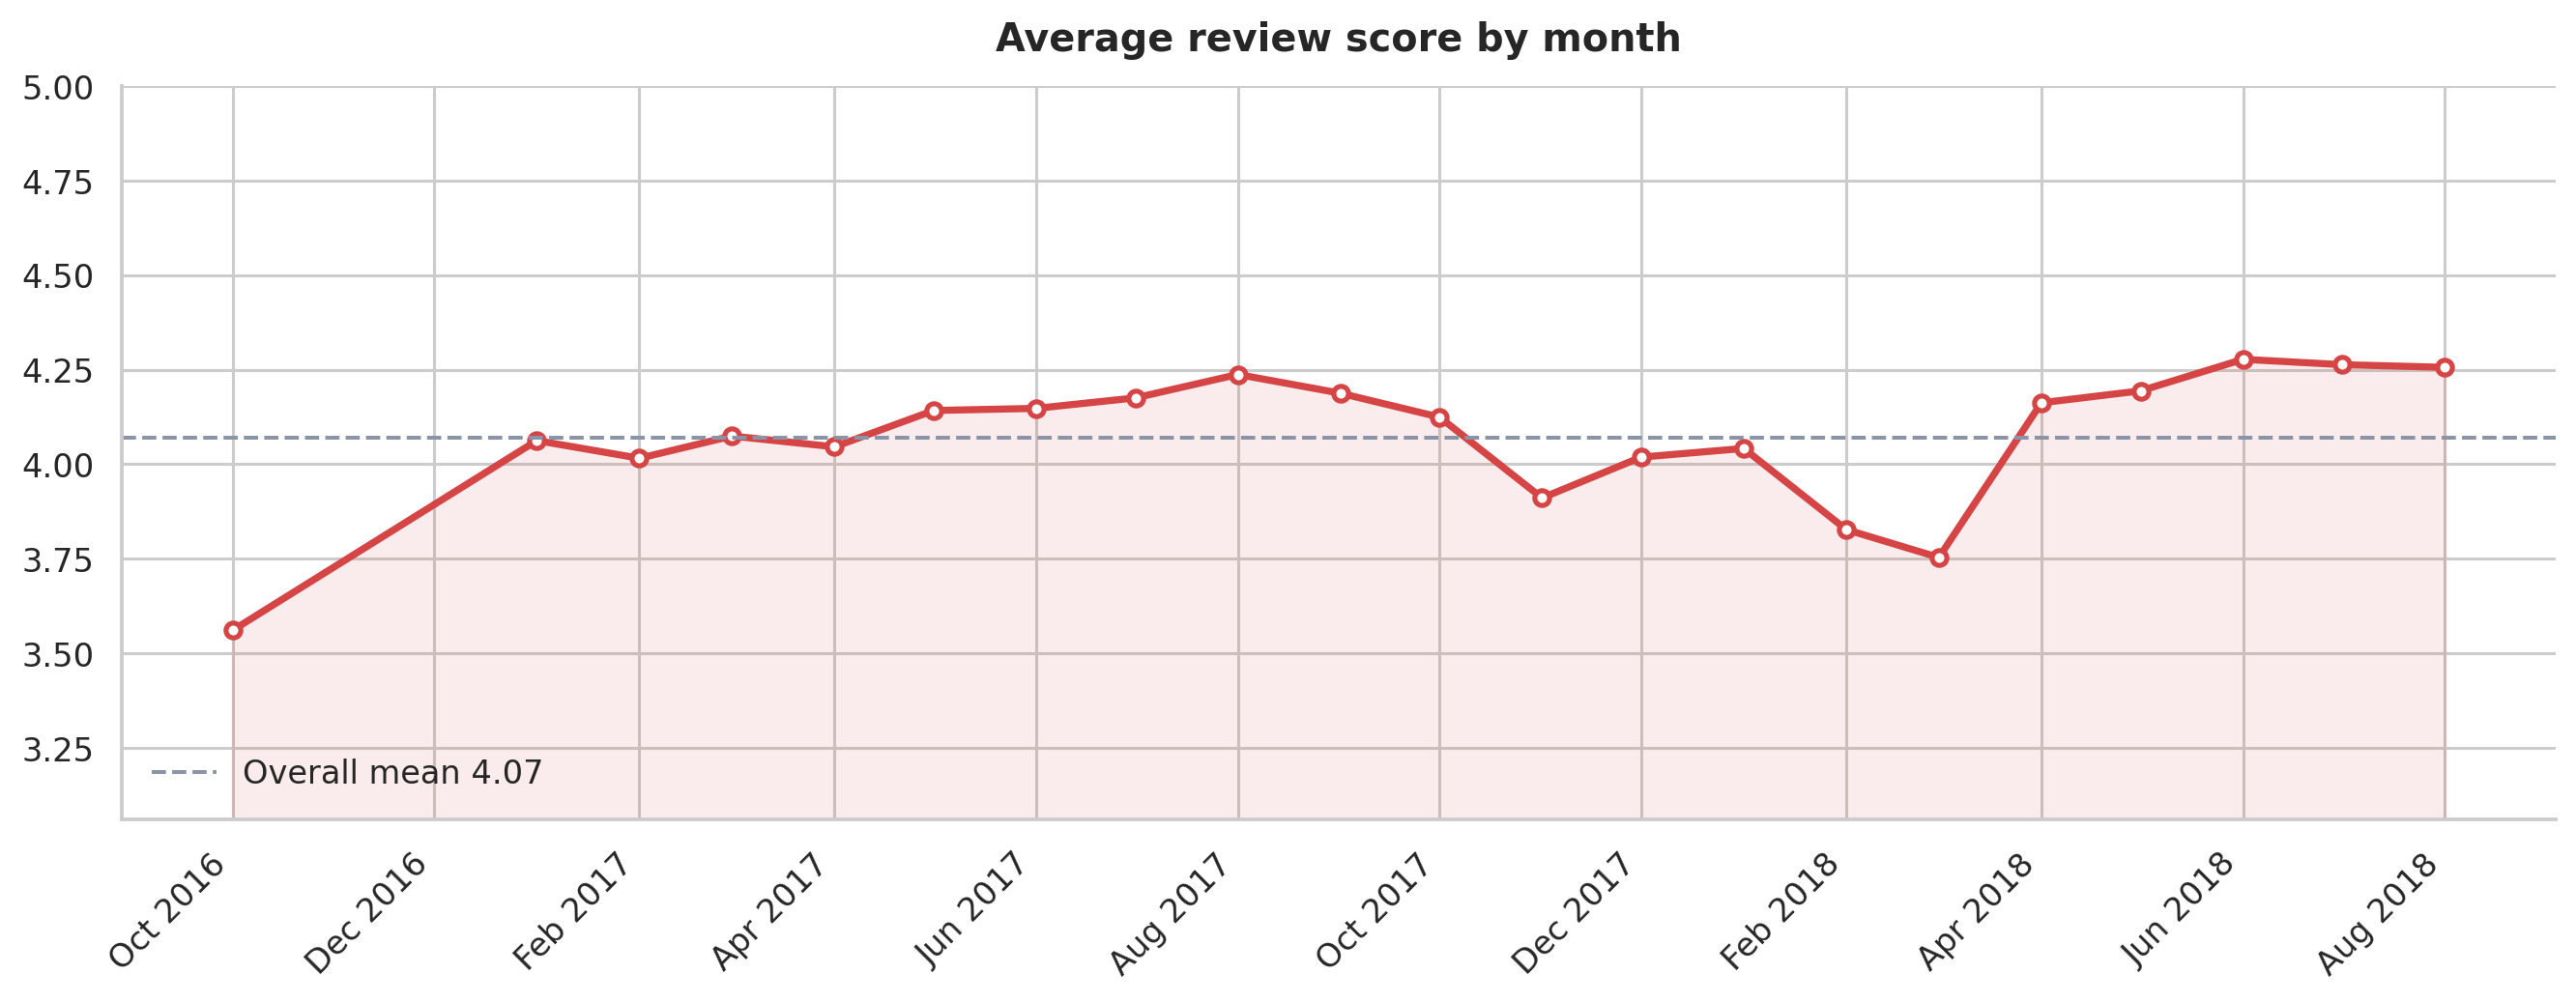

In [23]:
monthly = (fact_orders.groupby('year_month')
           .agg(orders=('order_id', 'size'), revenue=('total_price', 'sum'), avg_score=('review_score', 'mean'))
           .reset_index())
monthly = monthly[monthly['orders'] >= 0.05 * monthly['orders'].median()].copy()
monthly['month'] = pd.to_datetime(monthly['year_month'])

def trend_chart(col, title, color, fmt=None, annotate_peak=False):
    lo, hi = (max(1, monthly[col].min() - .5), 5.0) if col == 'avg_score' else (0, monthly[col].max() * 1.25)
    fig, ax = new_fig(12, 4.6)
    ax.plot(monthly['month'], monthly[col], color=color, lw=2.4, marker='o', ms=5, mfc='white', mew=1.7)
    ax.fill_between(monthly['month'], monthly[col], lo, color=color, alpha=.10)
    ax.set_ylim(lo, hi); ax.set_title(title)
    if fmt:
        ax.yaxis.set_major_formatter(fmt)
    if annotate_peak:
        peak = monthly.loc[monthly[col].idxmax()]
        ax.annotate(f"Peak: {peak['year_month']}\n{peak[col]:,.0f}", xy=(peak['month'], peak[col]), xytext=(0, 18),
                    textcoords='offset points', ha='center', fontsize=9, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=.4', fc='#FFF3E0', ec=C['orange']),
                    arrowprops=dict(arrowstyle='->', color=C['orange']))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    return fig, ax

trend_chart('orders', 'Monthly orders', C['blue'], fmt_int, annotate_peak=True)
plt.show()
trend_chart('revenue', 'Monthly revenue (BRL)', C['green'], fmt_money)
plt.show()
fig, ax = trend_chart('avg_score', 'Average review score by month', C['red'])
ax.axhline(monthly['avg_score'].mean(), color=C['gray'], ls='--', lw=1.3, label=f"Overall mean {monthly['avg_score'].mean():.2f}")
ax.legend(loc='lower left')
plt.show()

### 5.4 — Relationships

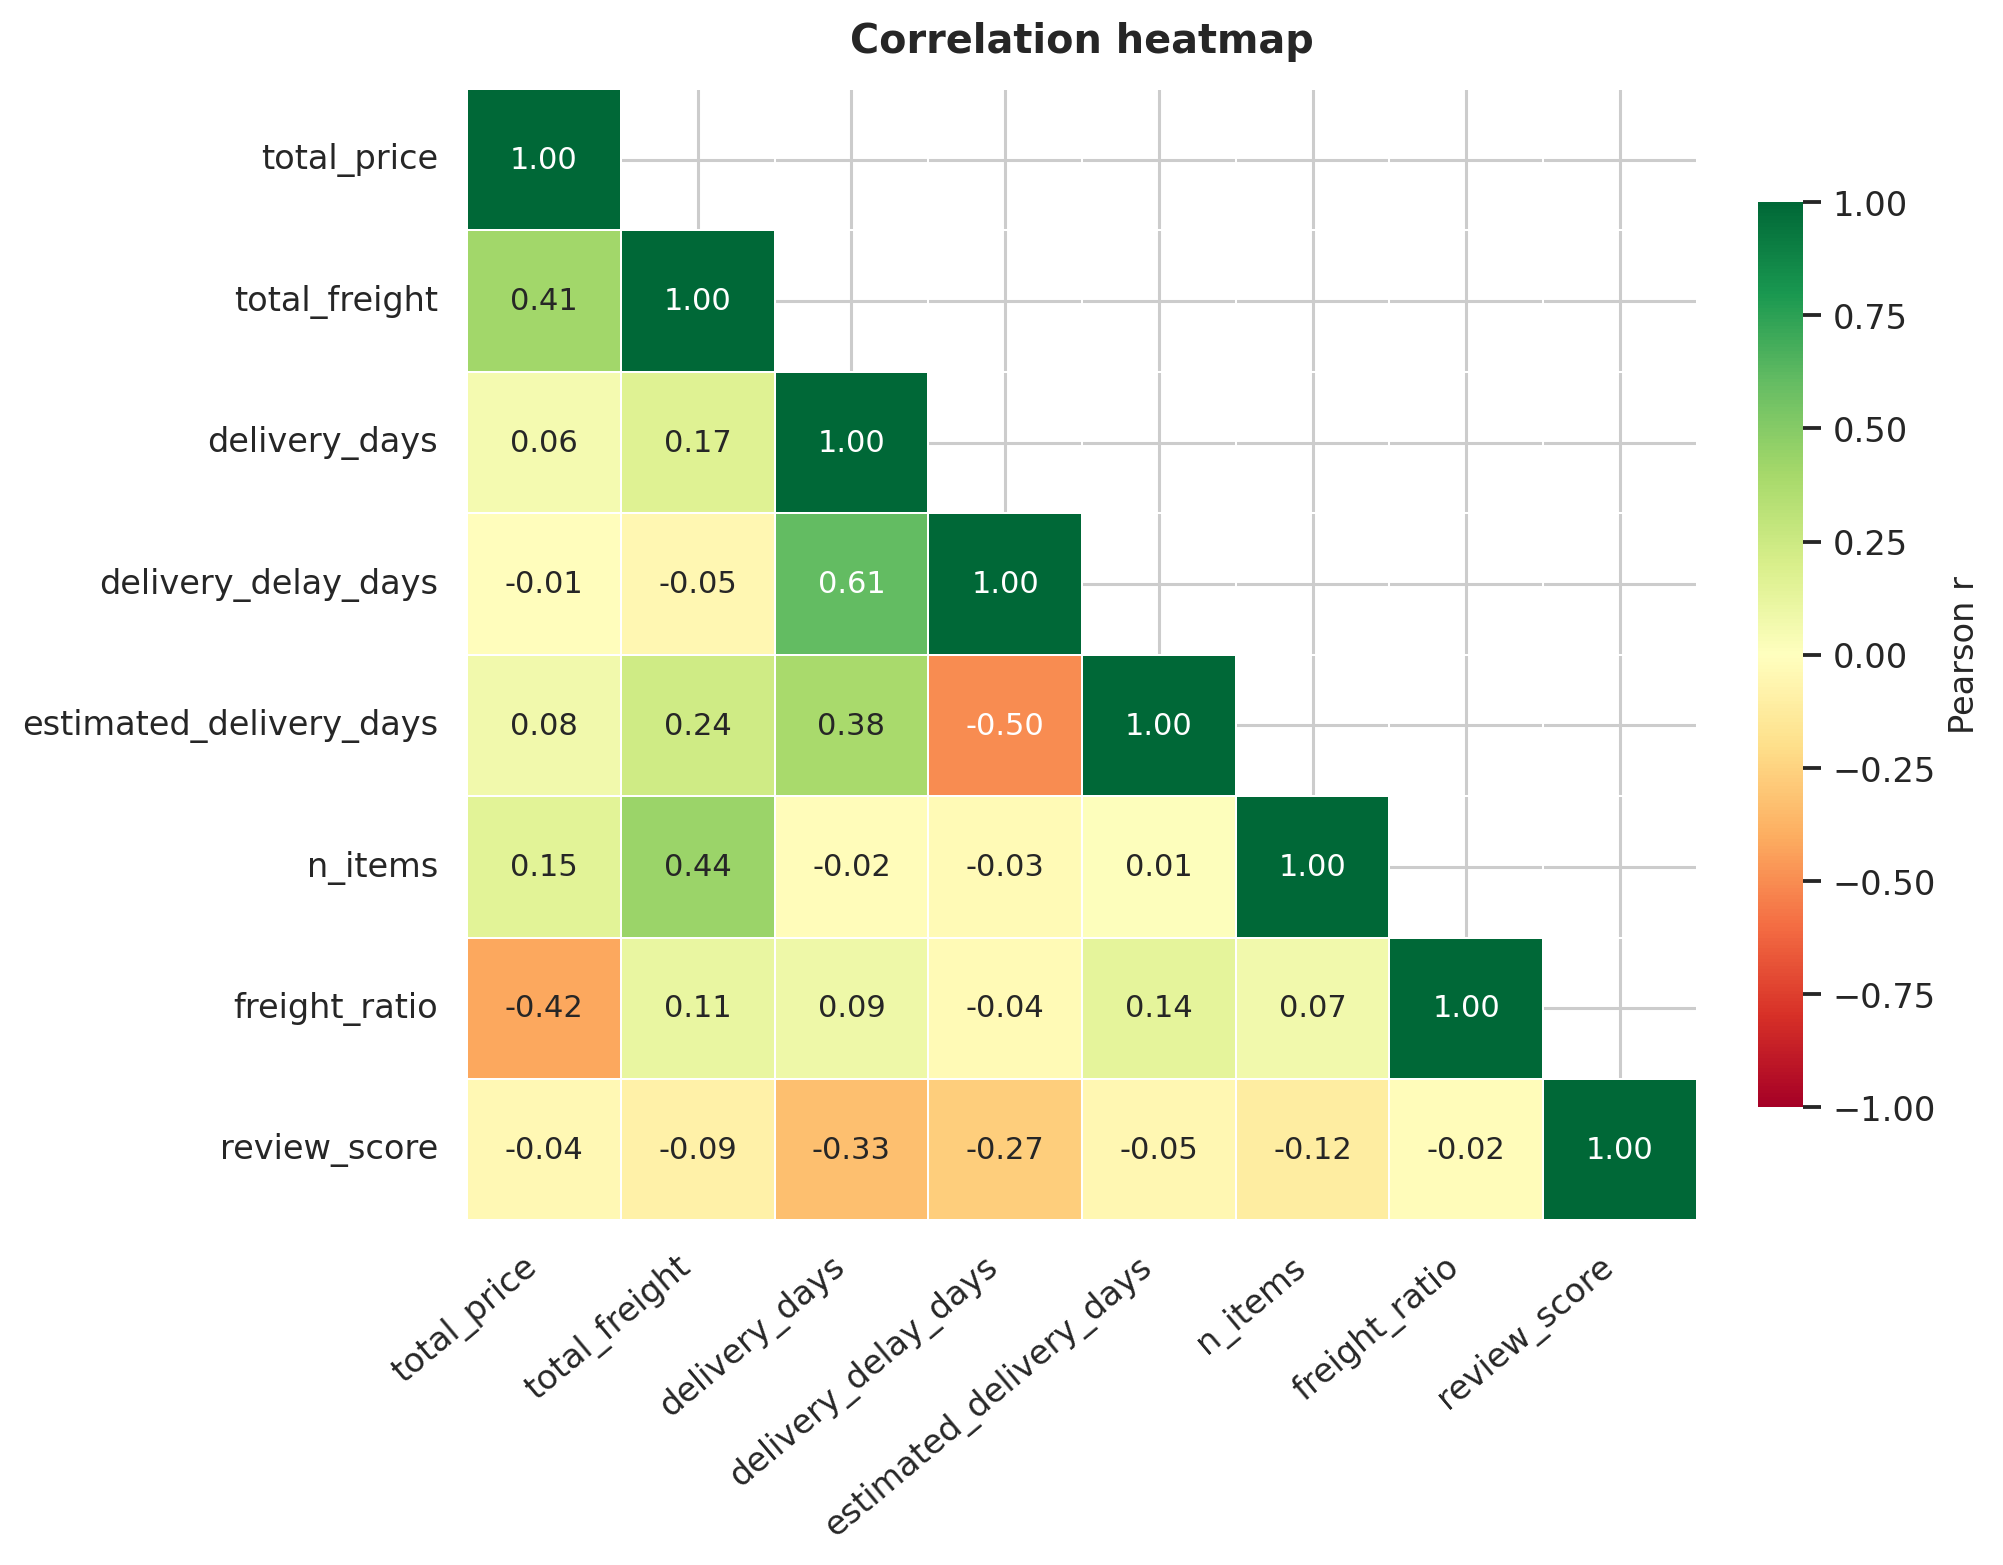

In [24]:
# Correlation heatmap
corr_cols = ['total_price', 'total_freight', 'delivery_days', 'delivery_delay_days',
             'estimated_delivery_days', 'n_items', 'freight_ratio', 'review_score']
corr = fact_orders[corr_cols].astype(float).corr()

fig, ax = new_fig(9, 7)
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={'shrink': .8, 'label': 'Pearson r'}, annot_kws={'size': 10}, ax=ax)
ax.set_title('Correlation heatmap')
plt.setp(ax.get_xticklabels(), rotation=40, ha='right')
plt.show()

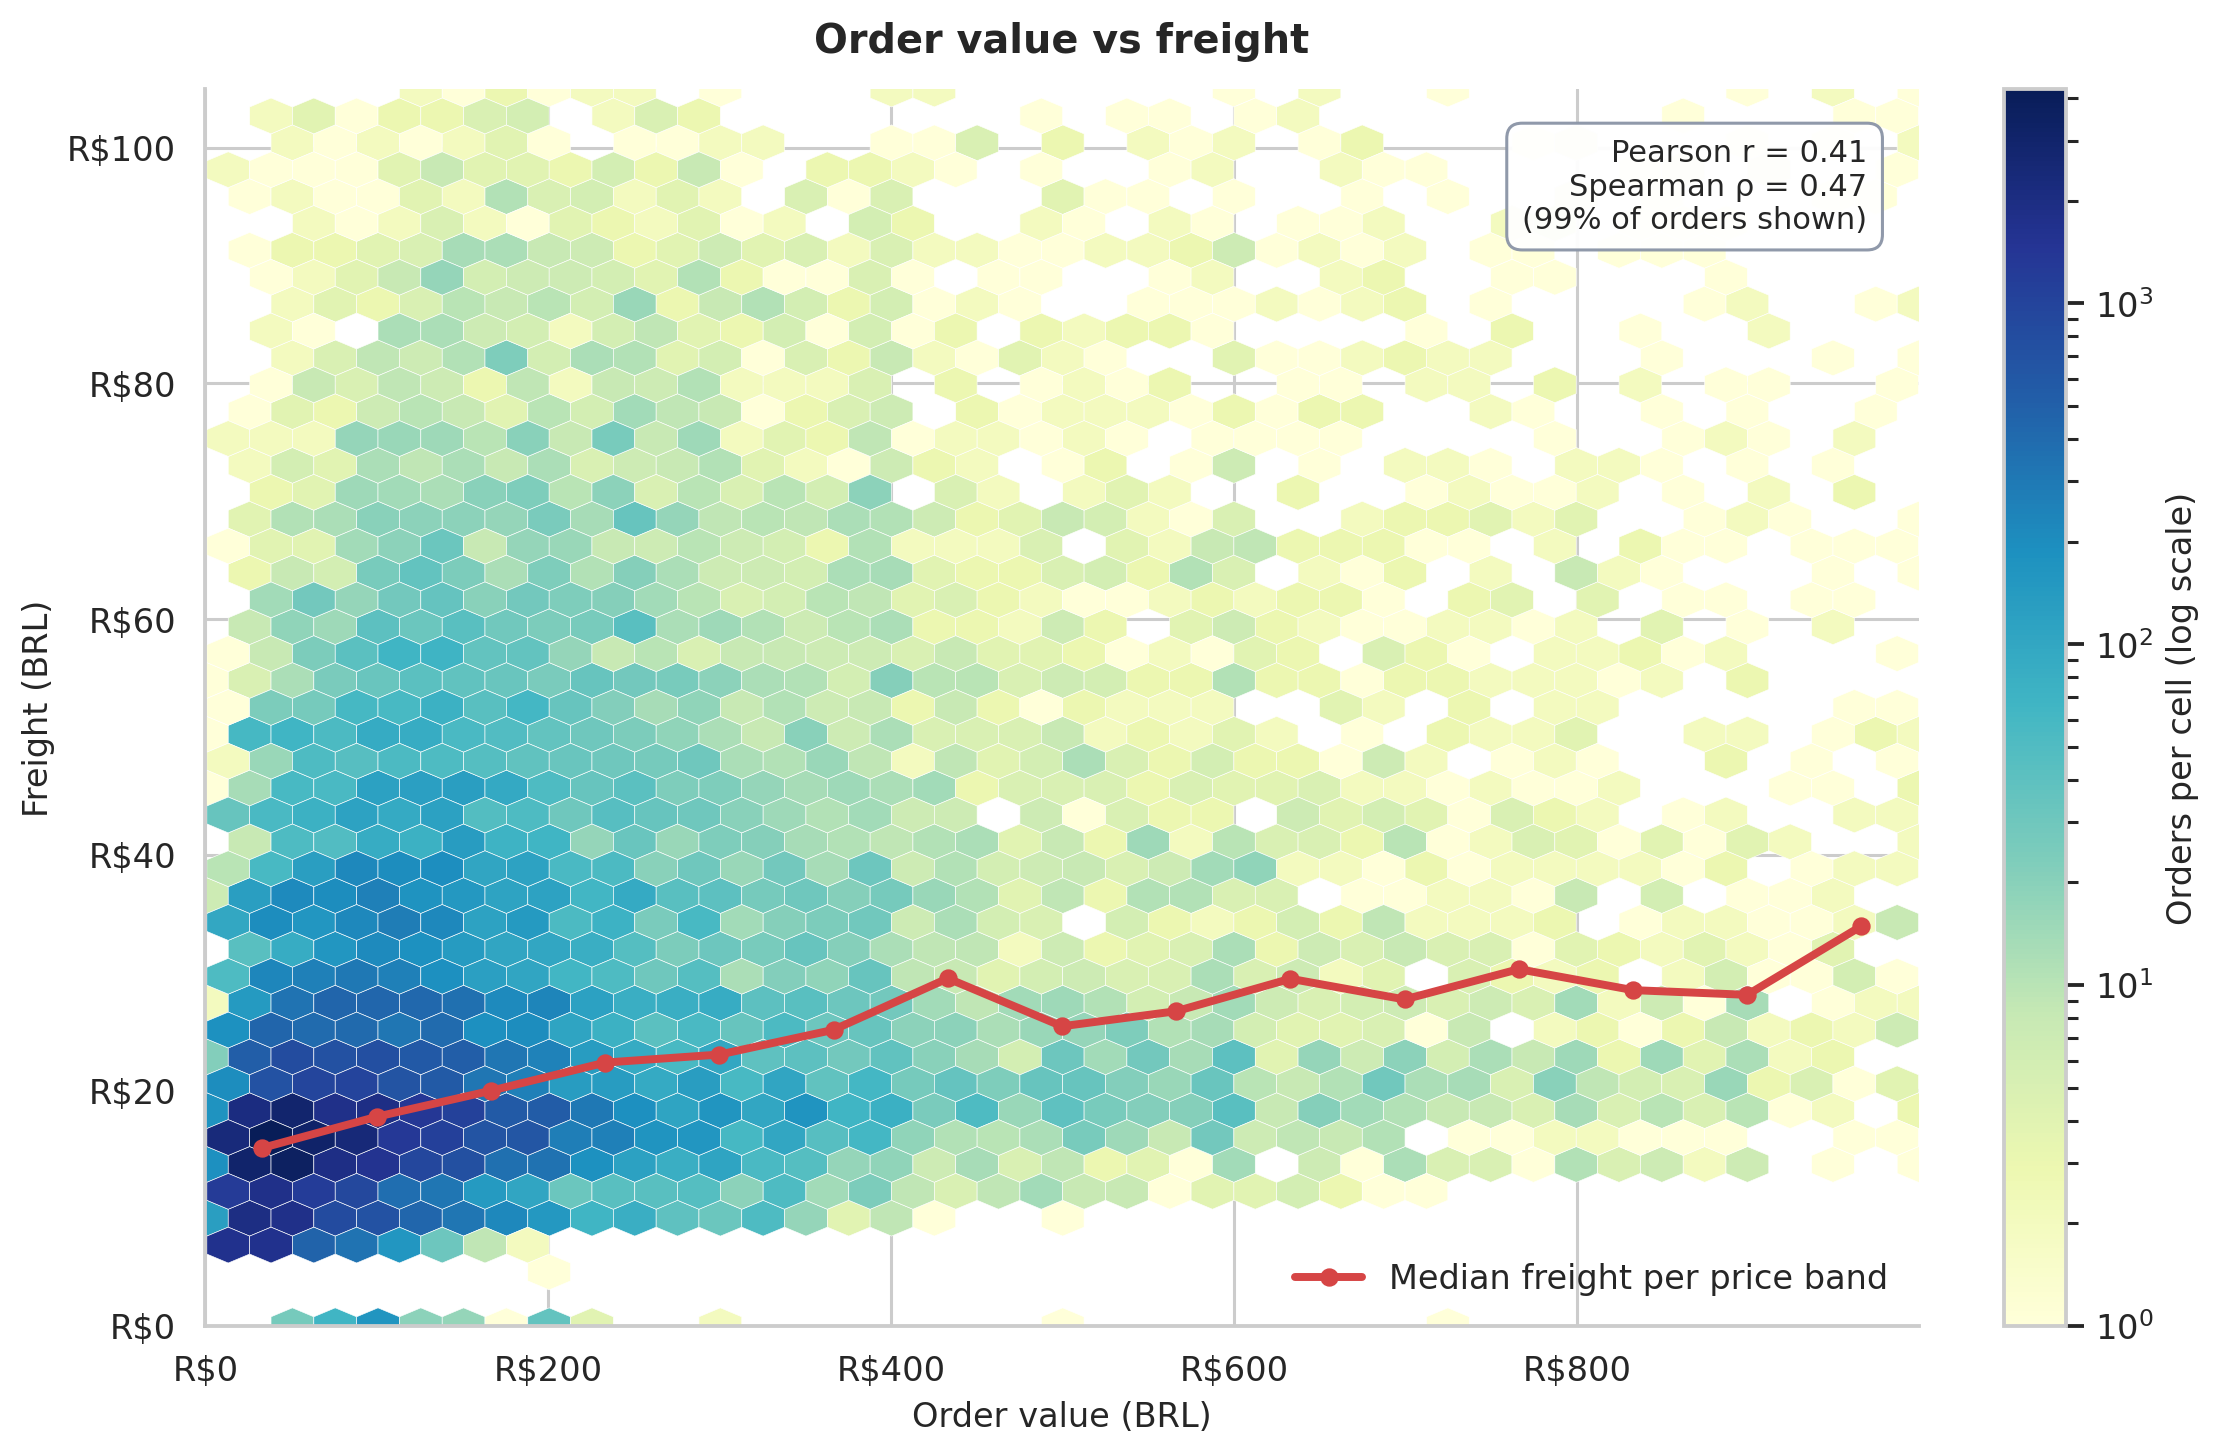

In [25]:
# Order value vs freight — hexbin of the typical 99% of orders (extremes would just pile up on the edges)
pf = fact_orders[['total_price', 'total_freight']].dropna()
pearson, spearman = pf.corr().iloc[0, 1], pf.corr(method='spearman').iloc[0, 1]
x_max, y_max = pf['total_price'].quantile(.99), pf['total_freight'].quantile(.99)
view = pf[(pf['total_price'] <= x_max) & (pf['total_freight'] <= y_max)]

bands = pd.cut(view['total_price'], bins=np.linspace(0, x_max, 16))
trend = view.groupby(bands, observed=True)['total_freight'].median()
mids = [iv.mid for iv in trend.index]

fig, ax = new_fig(10, 6.5)
hb = ax.hexbin(view['total_price'], view['total_freight'], gridsize=40, cmap='YlGnBu', bins='log',
               mincnt=1, linewidths=.2, edgecolors='white')
fig.colorbar(hb, ax=ax, label='Orders per cell (log scale)')
ax.plot(mids, trend.values, color=C['red'], lw=2.6, marker='o', ms=5, label='Median freight per price band')
ax.set_title('Order value vs freight')
ax.set_xlabel('Order value (BRL)'); ax.set_ylabel('Freight (BRL)')
ax.xaxis.set_major_formatter(fmt_brl); ax.yaxis.set_major_formatter(fmt_brl)
ax.set_xlim(0, x_max); ax.set_ylim(0, y_max)
ax.legend(loc='lower right')
ax.text(.97, .96, f'Pearson r = {pearson:.2f}\nSpearman ρ = {spearman:.2f}\n(99% of orders shown)', transform=ax.transAxes,
        ha='right', va='top', fontsize=10, bbox=dict(boxstyle='round,pad=.5', fc='white', ec=C['gray'], alpha=.95))
plt.show()

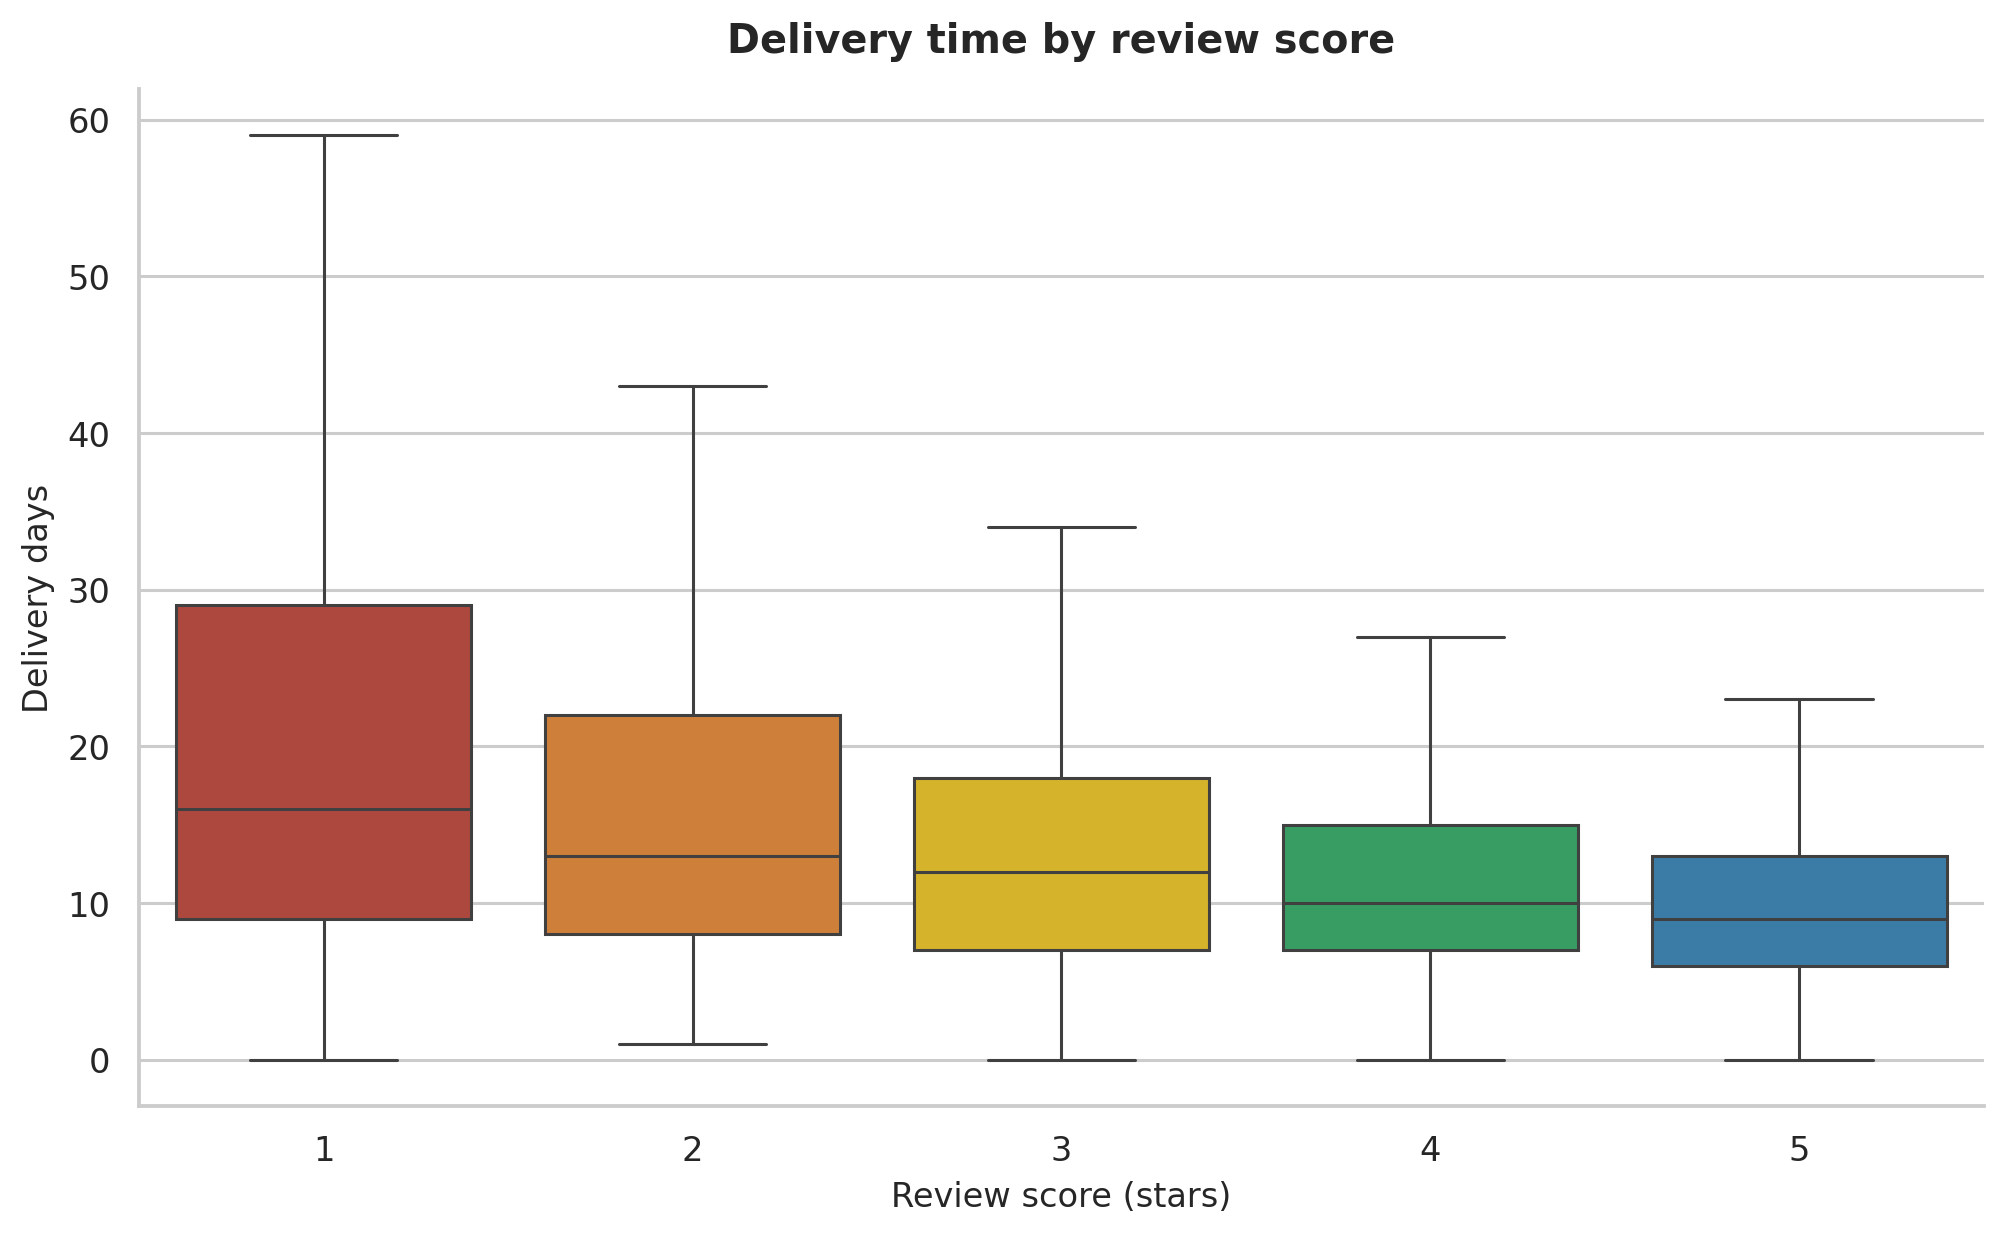

In [26]:
# Delivery time by review score
b = fact_orders[['review_score', 'delivery_days']].dropna()
b = b[b['delivery_days'].between(0, 60)].assign(stars=lambda d: d['review_score'].round().astype(int))
stars_palette = dict(zip(range(1, 6), ['#C0392B', '#E67E22', '#F1C40F', '#27AE60', '#2980B9']))

fig, ax = new_fig(9, 5.5)
sns.boxplot(data=b, x='stars', y='delivery_days', hue='stars', palette=stars_palette, legend=False, showfliers=False, ax=ax)
ax.set_title('Delivery time by review score')
ax.set_xlabel('Review score (stars)'); ax.set_ylabel('Delivery days')
plt.show()

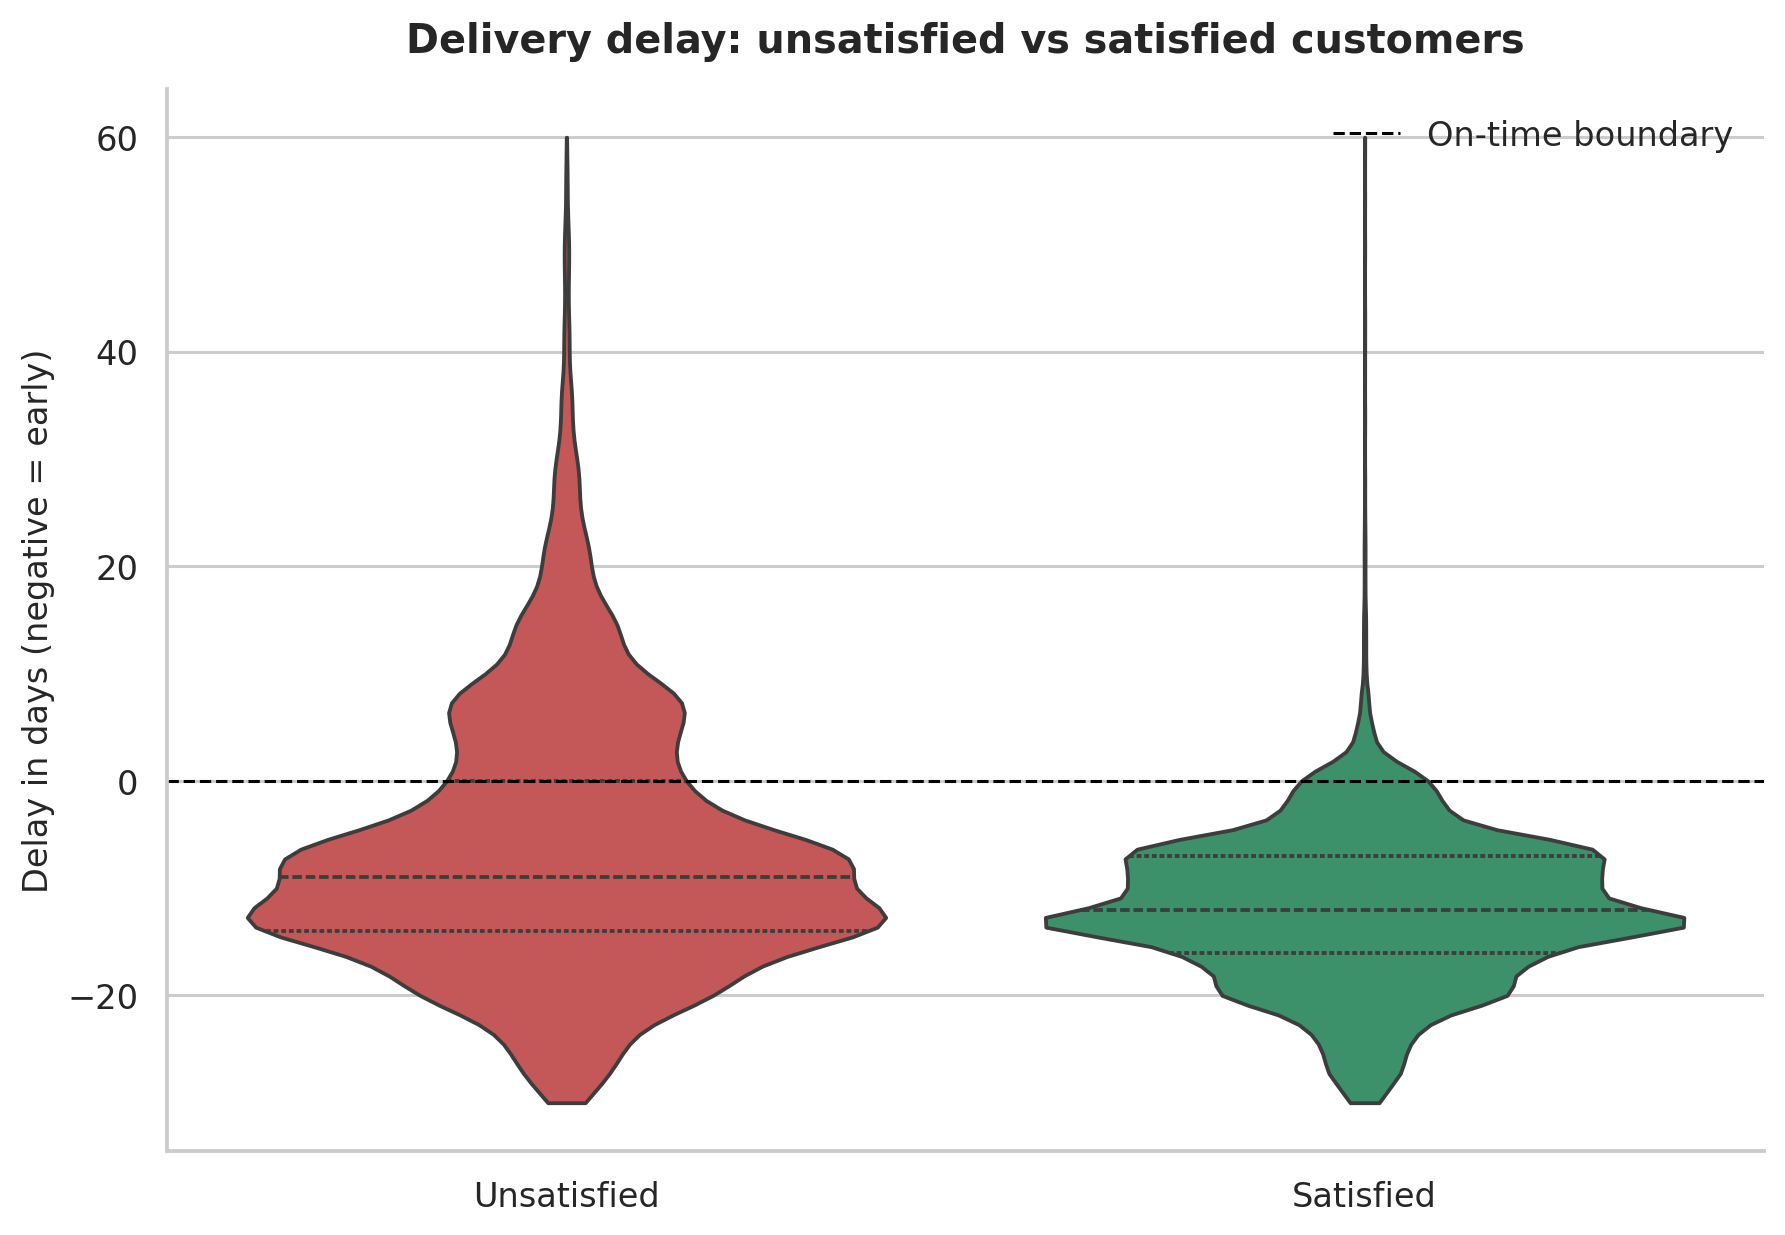

In [27]:
# Delay: unsatisfied vs satisfied
v = fact_orders[['is_satisfied', 'delivery_delay_days']].dropna()
v = v[v['delivery_delay_days'].between(-30, 60)].assign(
    Satisfaction=lambda d: d['is_satisfied'].astype(int).map({1: 'Satisfied', 0: 'Unsatisfied'}))

fig, ax = new_fig(8, 5.5)
sns.violinplot(data=v, x='Satisfaction', y='delivery_delay_days', hue='Satisfaction', order=['Unsatisfied', 'Satisfied'],
               palette={'Satisfied': C['green'], 'Unsatisfied': C['red']}, inner='quartile', cut=0, legend=False, ax=ax)
ax.axhline(0, color='black', ls='--', lw=1, label='On-time boundary')
ax.set_title('Delivery delay: unsatisfied vs satisfied customers')
ax.set_xlabel(''); ax.set_ylabel('Delay in days (negative = early)')
ax.legend(loc='upper right')
plt.show()

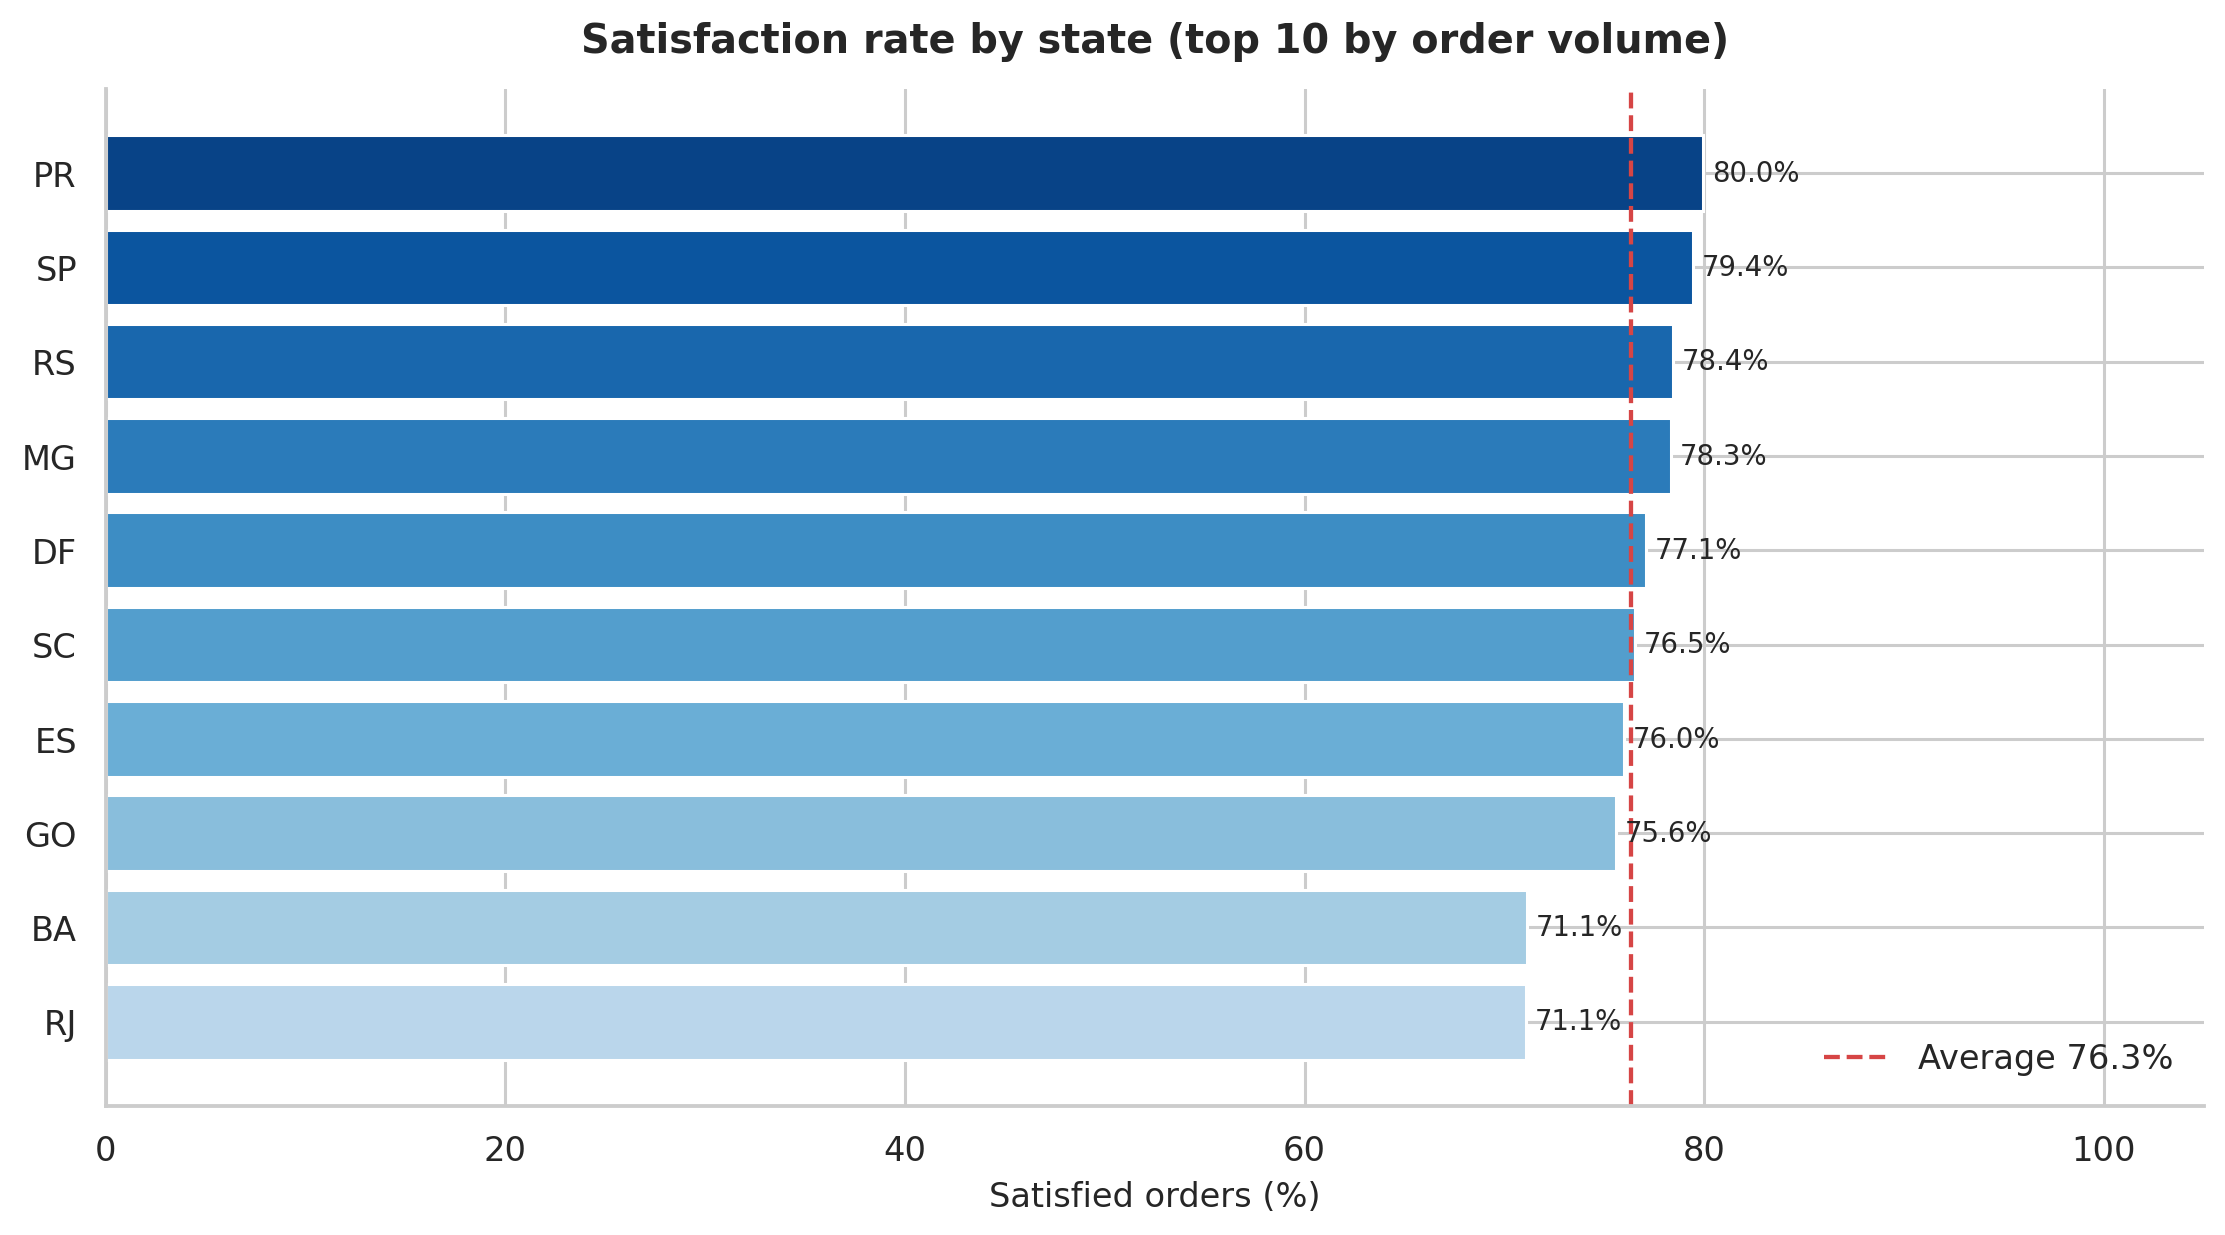

In [28]:
# Satisfaction by state (top 10 by volume)
top_states = fact_orders['customer_state'].value_counts().head(10).index
st = (fact_orders[fact_orders['customer_state'].isin(top_states)].dropna(subset=['is_satisfied'])
      .groupby('customer_state')['is_satisfied'].mean().mul(100).sort_values())

fig, ax = new_fig(10, 5.5)
bars = ax.barh(st.index, st.values, color=sns.color_palette('Blues', len(st) + 3)[3:])
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9)
ax.axvline(st.mean(), color=C['red'], ls='--', lw=1.4, label=f'Average {st.mean():.1f}%')
ax.set_title('Satisfaction rate by state (top 10 by order volume)')
ax.set_xlabel('Satisfied orders (%)'); ax.set_xlim(0, 105)
ax.legend(loc='lower right')
plt.show()

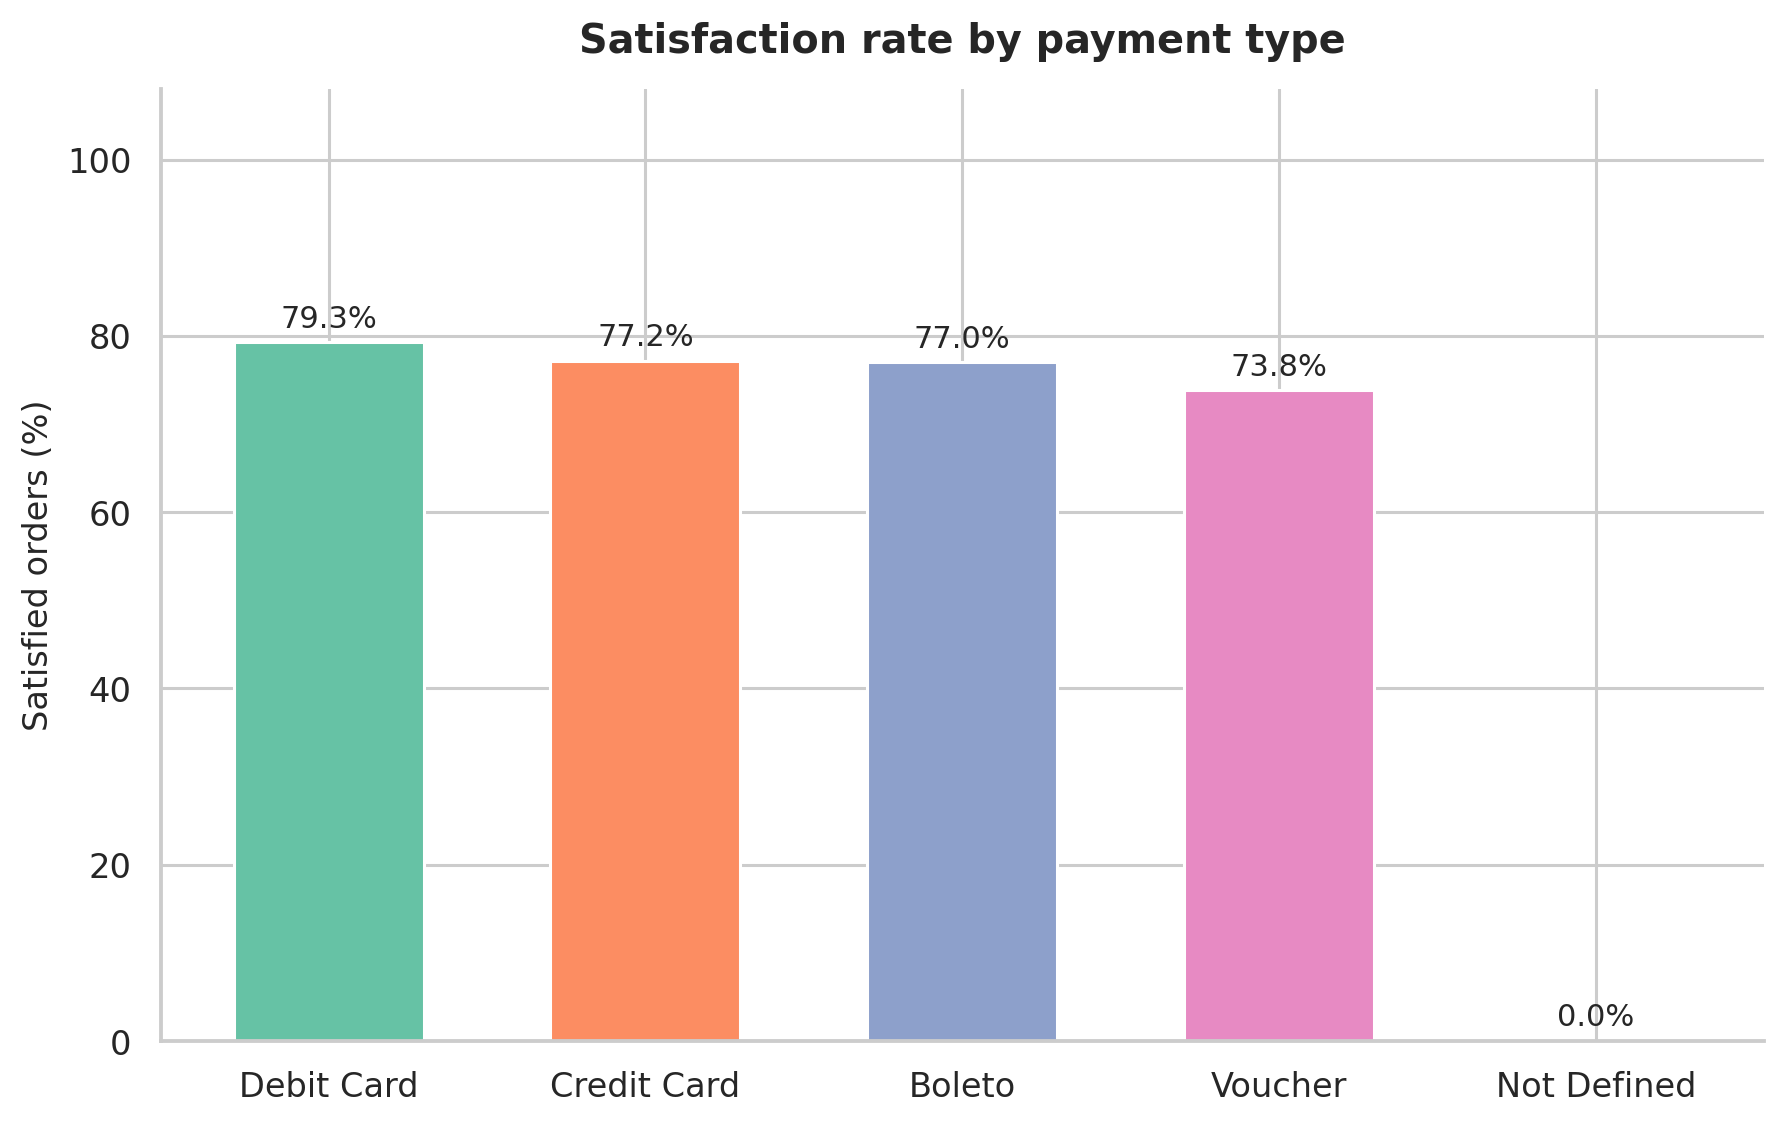

In [29]:
# Satisfaction by payment type
ps = (fact_orders.dropna(subset=['is_satisfied']).groupby('payment_type')['is_satisfied'].mean().mul(100)
      .sort_values(ascending=False))
fig, ax = new_fig(8, 5)
bars = ax.bar(ps.index.str.replace('_', ' ').str.title(), ps.values, color=sns.color_palette('Set2', len(ps)), width=.6)
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=10)
ax.set_title('Satisfaction rate by payment type')
ax.set_ylabel('Satisfied orders (%)'); ax.set_ylim(0, 108)
plt.show()

In [30]:
# Key takeaways — every number below is calculated from fact_orders
d = fact_orders.dropna(subset=['is_late', 'is_satisfied'])
on_time_sat, late_sat = d.loc[d['is_late'] == 0, 'is_satisfied'].mean(), d.loc[d['is_late'] == 1, 'is_satisfied'].mean()
late_rate = (fact_orders['is_late'] == 1).sum() / fact_orders['is_late'].notna().sum()
top_state = state_counts.index[0]
corr_with_score = corr['review_score'].drop('review_score')

banner('Key takeaways', '💡')
print(f'  🚚 {late_rate:.1%} of delivered orders arrive after the promised date.')
print(f'  😊 Satisfaction: {on_time_sat:.1%} when on time vs {late_sat:.1%} when late  ({(on_time_sat - late_sat) * 100:.1f} points lower).')
print(f'  📍 {top_state} is the largest state with {state_counts.iloc[0] / state_counts.sum():.1%} of all orders.')
print(f'  📈 Review score correlates most with {corr_with_score.abs().idxmax()} (r = {corr_with_score[corr_with_score.abs().idxmax()]:.2f}).')


💡 Key takeaways
─────────────────
  🚚 7.6% of delivered orders arrive after the promised date.
  😊 Satisfaction: 82.7% when on time vs 31.8% when late  (51.0 points lower).
  📍 SP is the largest state with 42.0% of all orders.
  📈 Review score correlates most with delivery_days (r = -0.33).


## Part 6 — Machine Learning
Five classifiers predict satisfaction, three regressors predict delivery time. Training is kept fast: dense one-hot features for linear models, native categorical handling for gradient boosting, and a small randomized search instead of a full grid.

### 6.1 — Feature Sets and Train/Test Split

In [31]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

CLS_NUM = ['delivery_days', 'delivery_delay_days', 'is_late', 'estimated_delivery_days', 'total_price',
           'total_freight', 'freight_ratio', 'n_items', 'purchase_month', 'purchase_weekday', 'payment_installments']
CLS_CAT = ['customer_state', 'seller_state', 'payment_type', 'product_category_en']

DELIVERY_OUTCOME = {'delivery_days', 'delivery_delay_days', 'is_late'}          # would leak the regression target
REG_NUM = [c for c in CLS_NUM if c not in DELIVERY_OUTCOME]
REG_CAT = CLS_CAT
assert all(c in fact_orders.columns for c in CLS_NUM + CLS_CAT), 'a feature column is missing'

delivered = fact_orders[fact_orders['order_delivered_customer_date'].notna()]
TOP_CATEGORIES = delivered['product_category_en'].value_counts().head(25).index      # rare categories → "other"

def build_matrix(df, num, cat):
    """Model-ready features: floats, outliers capped at the 99th percentile, tidy categories."""
    X = df[num + cat].copy()
    X[num] = X[num].astype(float)
    for col in ('total_price', 'total_freight', 'n_items'):
        if col in num:
            X[col] = X[col].clip(upper=X[col].quantile(.99))
    if 'product_category_en' in cat:
        X['product_category_en'] = X['product_category_en'].where(X['product_category_en'].isin(TOP_CATEGORIES), 'other')
    X[cat] = X[cat].fillna('missing').astype(str)
    return X

cls_df = delivered.dropna(subset=['is_satisfied'])
reg_df = delivered[delivered['delivery_days'] > 0]

X_cls, y_cls = build_matrix(cls_df, CLS_NUM, CLS_CAT), cls_df['is_satisfied'].astype(int)
X_reg, y_reg = build_matrix(reg_df, REG_NUM, REG_CAT), reg_df['delivery_days'].astype(float)

X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(X_cls, y_cls, test_size=.2, random_state=SEED, stratify=y_cls)
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg, y_reg, test_size=.2, random_state=SEED)
baseline_acc = y_te_c.value_counts(normalize=True).max()

show(pd.DataFrame([
    {'Task': 'Satisfaction (classification)', 'Rows': len(X_cls), 'Train': len(X_tr_c), 'Test': len(X_te_c),
     'Numeric': len(CLS_NUM), 'Categorical': len(CLS_CAT), 'Target': 'is_satisfied'},
    {'Task': 'Delivery time (regression)', 'Rows': len(X_reg), 'Train': len(X_tr_r), 'Test': len(X_te_r),
     'Numeric': len(REG_NUM), 'Categorical': len(REG_CAT), 'Target': 'delivery_days'}]),
    '🧱 Modelling datasets')
print(f'Majority-class baseline accuracy (test): {baseline_acc:.1%}')

Task,Rows,Train,Test,Numeric,Categorical,Target
Satisfaction (classification),"95,830","76,664","19,166",11,4,is_satisfied
Delivery time (regression),"96,463","77,170","19,293",8,4,delivery_days


Majority-class baseline accuracy (test): 78.9%


### 6.2 — Classifiers

In [35]:
def linear_prep(num, cat):
    """Median-impute + scale numbers, dense one-hot for categories (rare levels are grouped)."""
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=30, sparse_output=False), cat)])

def tree_prep(num, cat):
    """Numbers pass through (gradient boosting handles NaN); categories become integer codes."""
    return ColumnTransformer([
        ('num', 'passthrough', num),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat)])

def cat_mask(num, cat):
    return [False] * len(num) + [True] * len(cat)

def make_hgb_clf(**params):
    kw = dict(categorical_features=cat_mask(CLS_NUM, CLS_CAT), class_weight='balanced', max_iter=300,
              early_stopping=True, n_iter_no_change=15, random_state=SEED, **params)
    try:
        est = HistGradientBoostingClassifier(**kw)
    except TypeError:                                   # older scikit-learn has no class_weight here
        kw.pop('class_weight')
        est = HistGradientBoostingClassifier(**kw)
    return Pipeline([('prep', tree_prep(CLS_NUM, CLS_CAT)), ('model', est)])

def linear_pipe(estimator):
    return Pipeline([('prep', linear_prep(CLS_NUM, CLS_CAT)), ('model', estimator)])

classifiers = {
    'Logistic Reg.': linear_pipe(LogisticRegression(max_iter=500, class_weight='balanced')),
    'Decision Tree': linear_pipe(DecisionTreeClassifier(max_depth=8, min_samples_leaf=30, class_weight='balanced', random_state=SEED)),
    'Random Forest': linear_pipe(RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=10,
                                                        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)),
    'Linear SVM':    linear_pipe(LinearSVC(C=0.3, dual=False, class_weight='balanced', random_state=SEED)),
    'Hist. GB':      make_hgb_clf(),
}

def score_of(model, X):
    """Probability of 'satisfied'. LinearSVC has no probabilities, so its margin goes through a sigmoid."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return 1 / (1 + np.exp(-model.decision_function(X)))

fitted_clf, clf_preds, clf_scores, clf_rows = {}, {}, {}, []

def fit_classifier(name, model):
    t0 = time.perf_counter()
    model.fit(X_tr_c, y_tr_c)
    secs = time.perf_counter() - t0
    pred, score = model.predict(X_te_c), score_of(model, X_te_c)
    fitted_clf[name], clf_preds[name], clf_scores[name] = model, pred, score
    clf_rows.append({'Model': name, 'Accuracy': accuracy_score(y_te_c, pred),
                     'Precision': precision_score(y_te_c, pred), 'Recall': recall_score(y_te_c, pred),
                     'F1': f1_score(y_te_c, pred), 'Macro F1': f1_score(y_te_c, pred, average='macro'),
                     'ROC-AUC': roc_auc_score(y_te_c, score), 'Fit time (s)': secs})
    print(f'  ✅ {name:<18} ROC-AUC {clf_rows[-1]["ROC-AUC"]:.3f}   ({secs:.1f}s)')

with timed('Training 5 classifiers'):
    for name, model in classifiers.items():
        fit_classifier(name, model)

  ✅ Logistic Reg.      ROC-AUC 0.706   (2.3s)
  ✅ Decision Tree      ROC-AUC 0.698   (1.0s)
  ✅ Random Forest      ROC-AUC 0.710   (11.0s)
  ✅ Linear SVM         ROC-AUC 0.706   (0.9s)
  ✅ Hist. GB           ROC-AUC 0.708   (1.0s)
⏱️  Training 5 classifiers: 17.5s


### 6.3 — Hyper-parameter Search
A randomized search (8 candidates, 3-fold CV, 40k-row sample) on the fastest strong model, followed by one refit on the full training set.

In [36]:
param_dist = {
    'model__learning_rate':     [0.03, 0.05, 0.08, 0.12],
    'model__max_depth':         [None, 6, 10],
    'model__max_leaf_nodes':    [15, 31, 63],
    'model__min_samples_leaf':  [20, 50, 100],
    'model__l2_regularization': [0, 0.5, 1, 5],
}
sample_idx = X_tr_c.sample(min(40_000, len(X_tr_c)), random_state=SEED).index

search = RandomizedSearchCV(make_hgb_clf(), param_dist, n_iter=8, scoring='roc_auc', refit=False, n_jobs=1,
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED)
with timed('Randomized search'):
    search.fit(X_tr_c.loc[sample_idx], y_tr_c.loc[sample_idx])

best_params = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
print(f'Best CV ROC-AUC: {search.best_score_:.4f}')
print(f'Best parameters: {best_params}')

with timed('Refit on full training set'):
    fit_classifier('Hist. GB (tuned)', make_hgb_clf(**best_params))

⏱️  Randomized search: 14.4s
Best CV ROC-AUC: 0.7066
Best parameters: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_depth': 10, 'learning_rate': 0.12, 'l2_regularization': 5}
  ✅ Hist. GB (tuned)   ROC-AUC 0.709   (1.4s)
⏱️  Refit on full training set: 1.8s


### 6.4 — Classifier Comparison
The best model is chosen by **ROC-AUC**, which does not depend on a decision threshold or on class balance.

🏆,Model,Accuracy,Precision,Recall,F1,Macro F1,ROC-AUC,Fit time (s)
,Logistic Reg.,0.737,0.858,0.799,0.827,0.638,0.706,2.286
,Decision Tree,0.737,0.860,0.796,0.827,0.639,0.698,1.023
🏆,Random Forest,0.774,0.855,0.859,0.857,0.658,0.710,11.000
,Linear SVM,0.753,0.856,0.826,0.841,0.646,0.706,0.946
,Hist. GB,0.744,0.860,0.808,0.833,0.644,0.708,0.966
,Hist. GB (tuned),0.742,0.860,0.804,0.831,0.643,0.709,1.400


🏆 Best by ROC-AUC: Random Forest  (0.710)


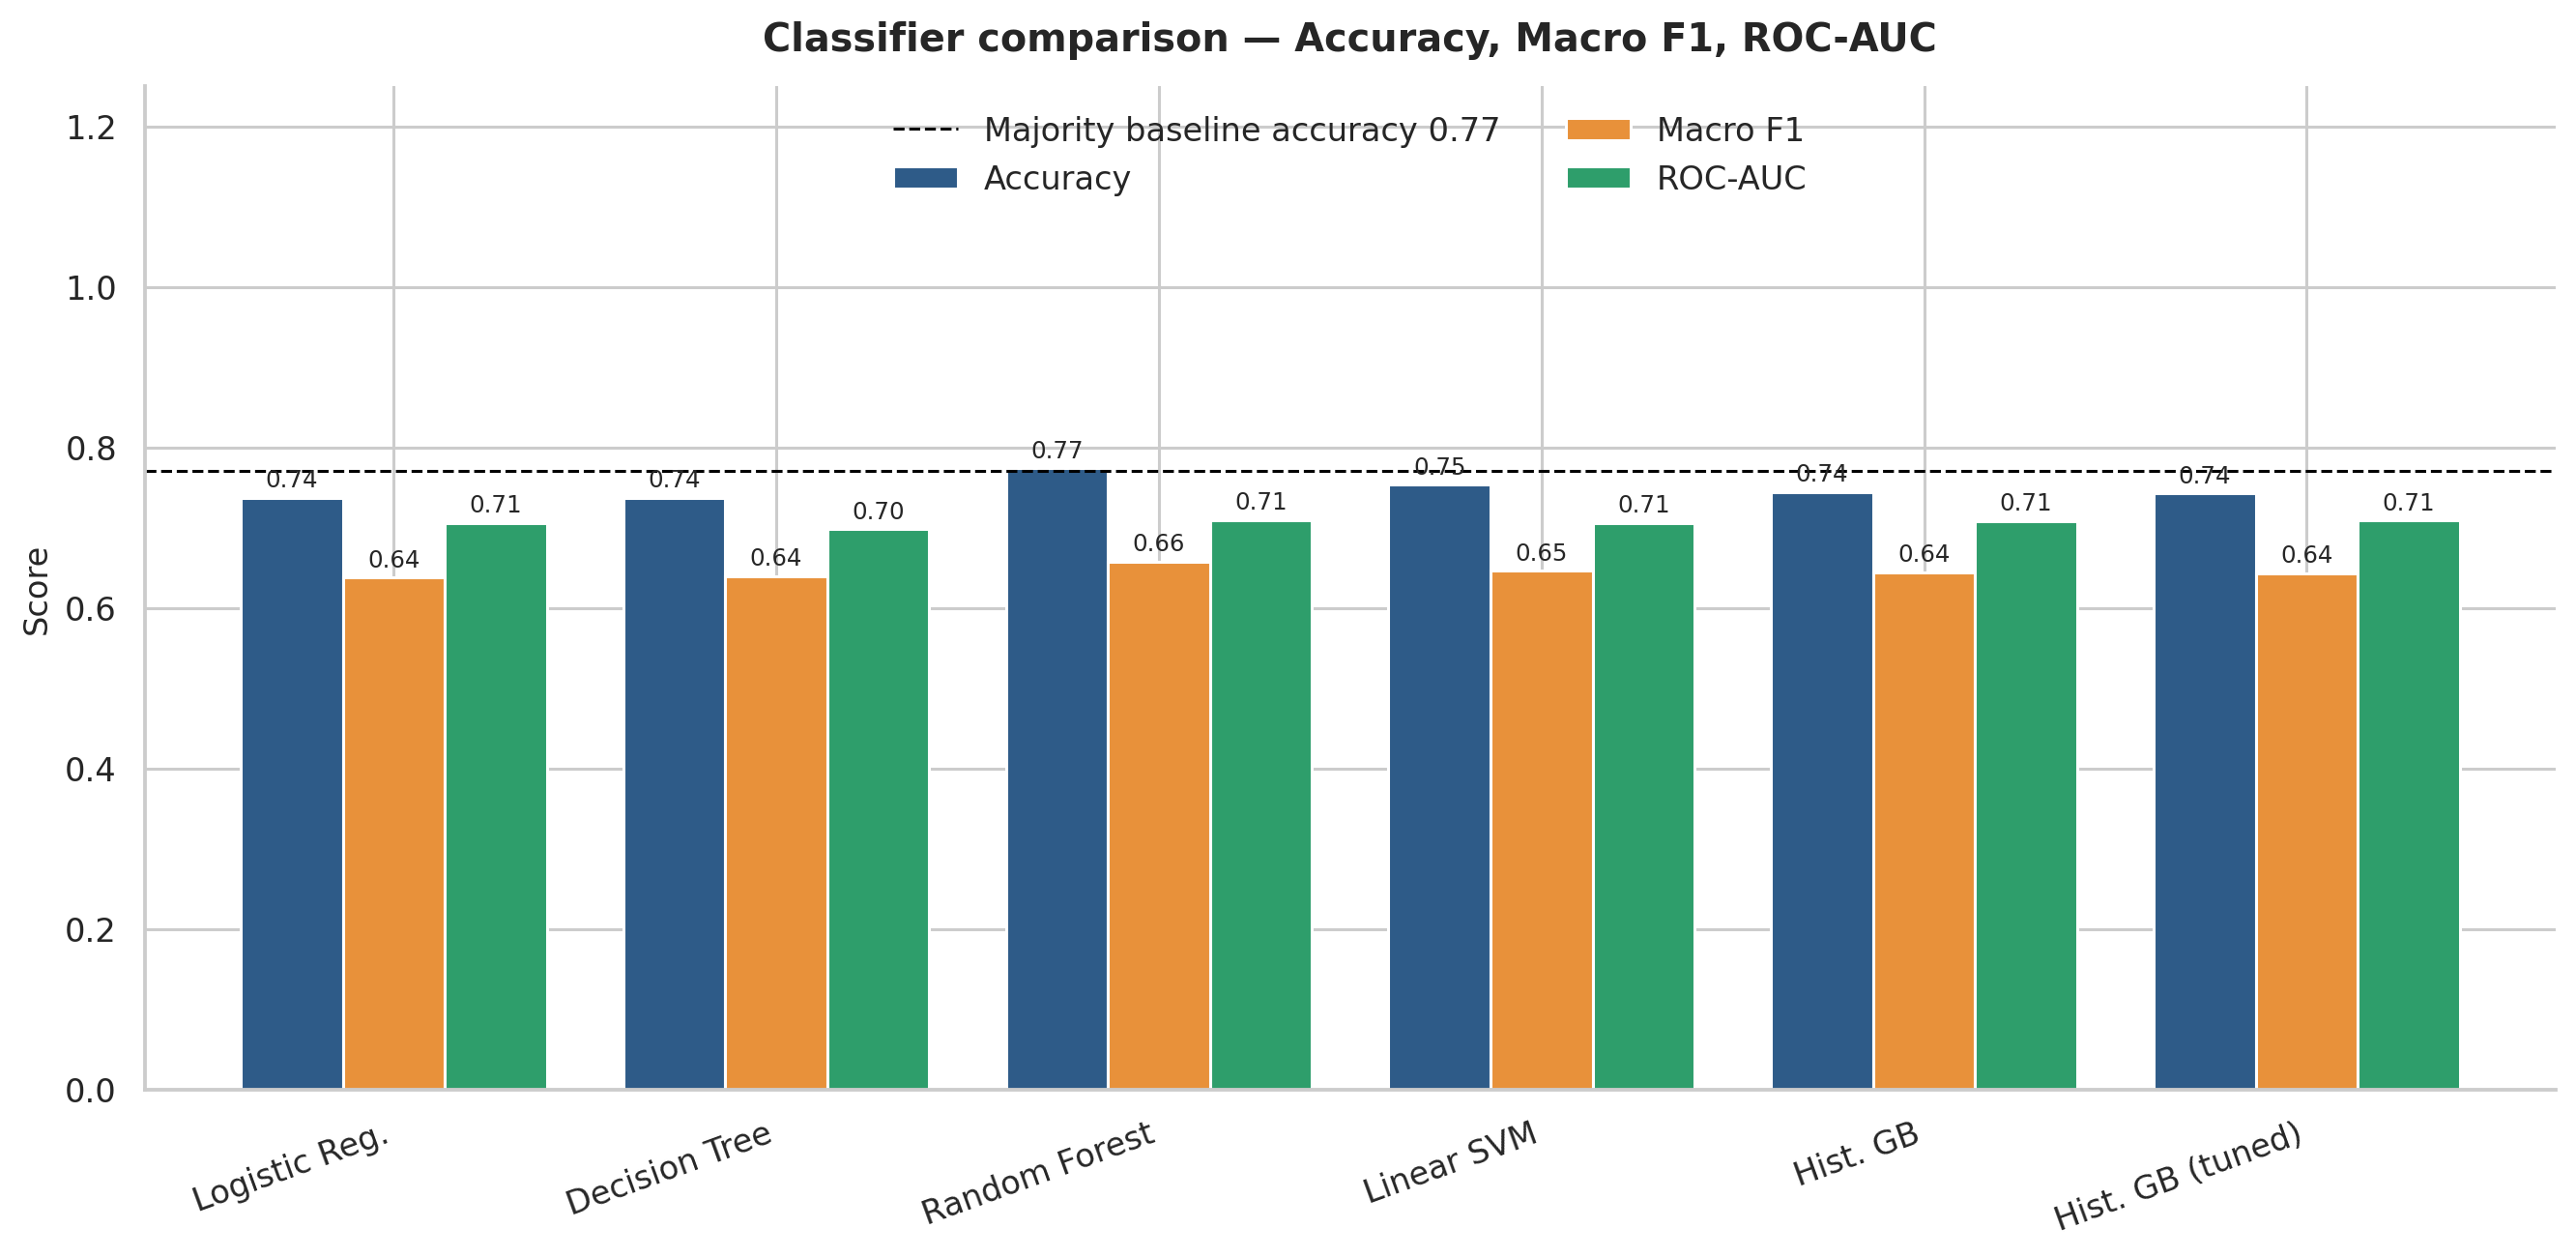

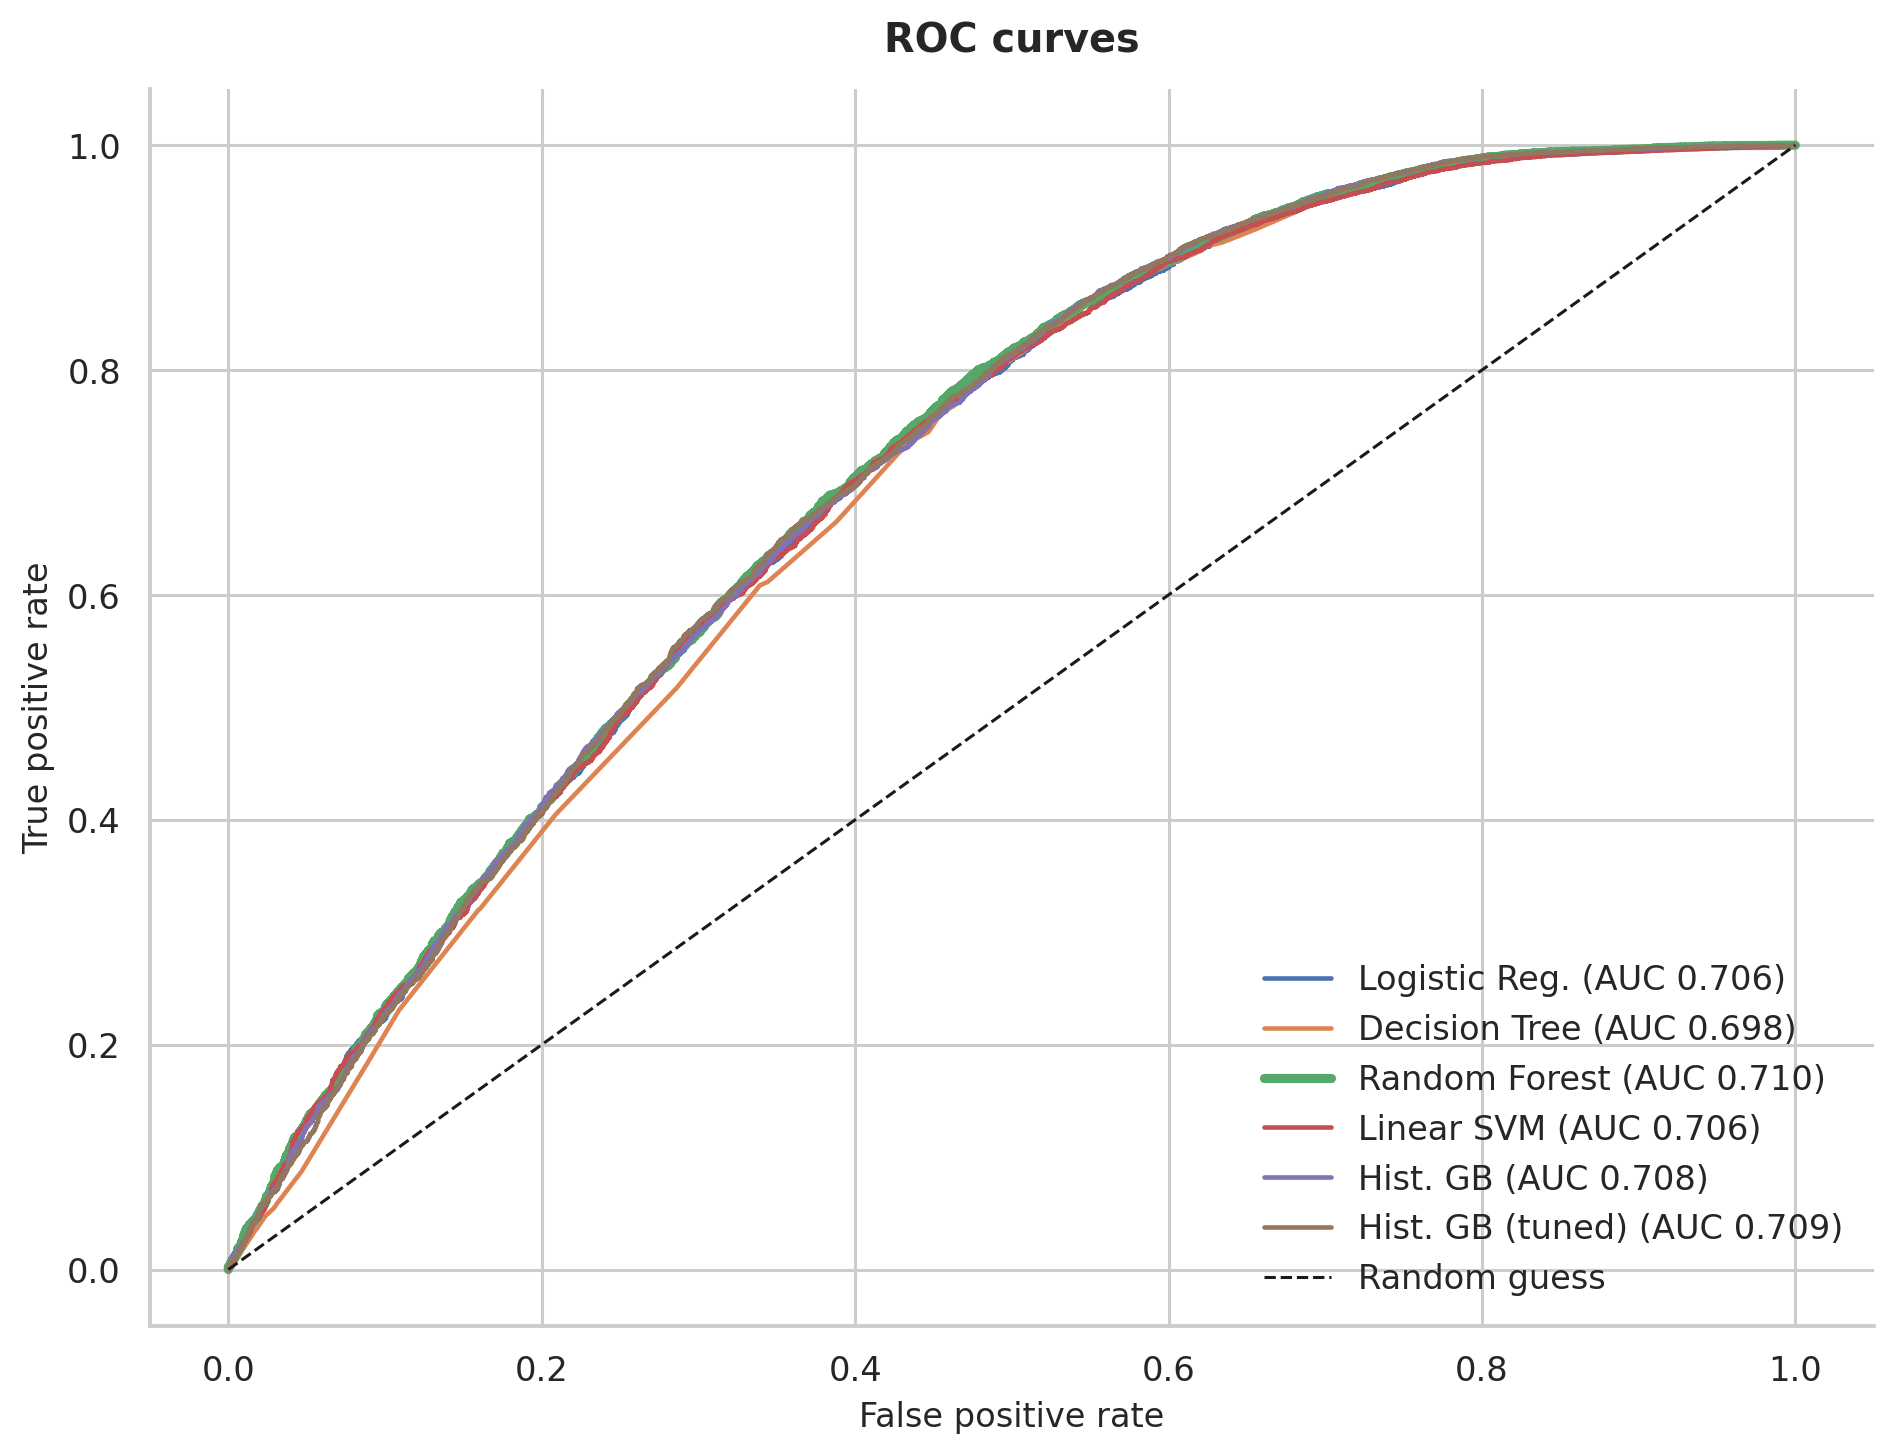

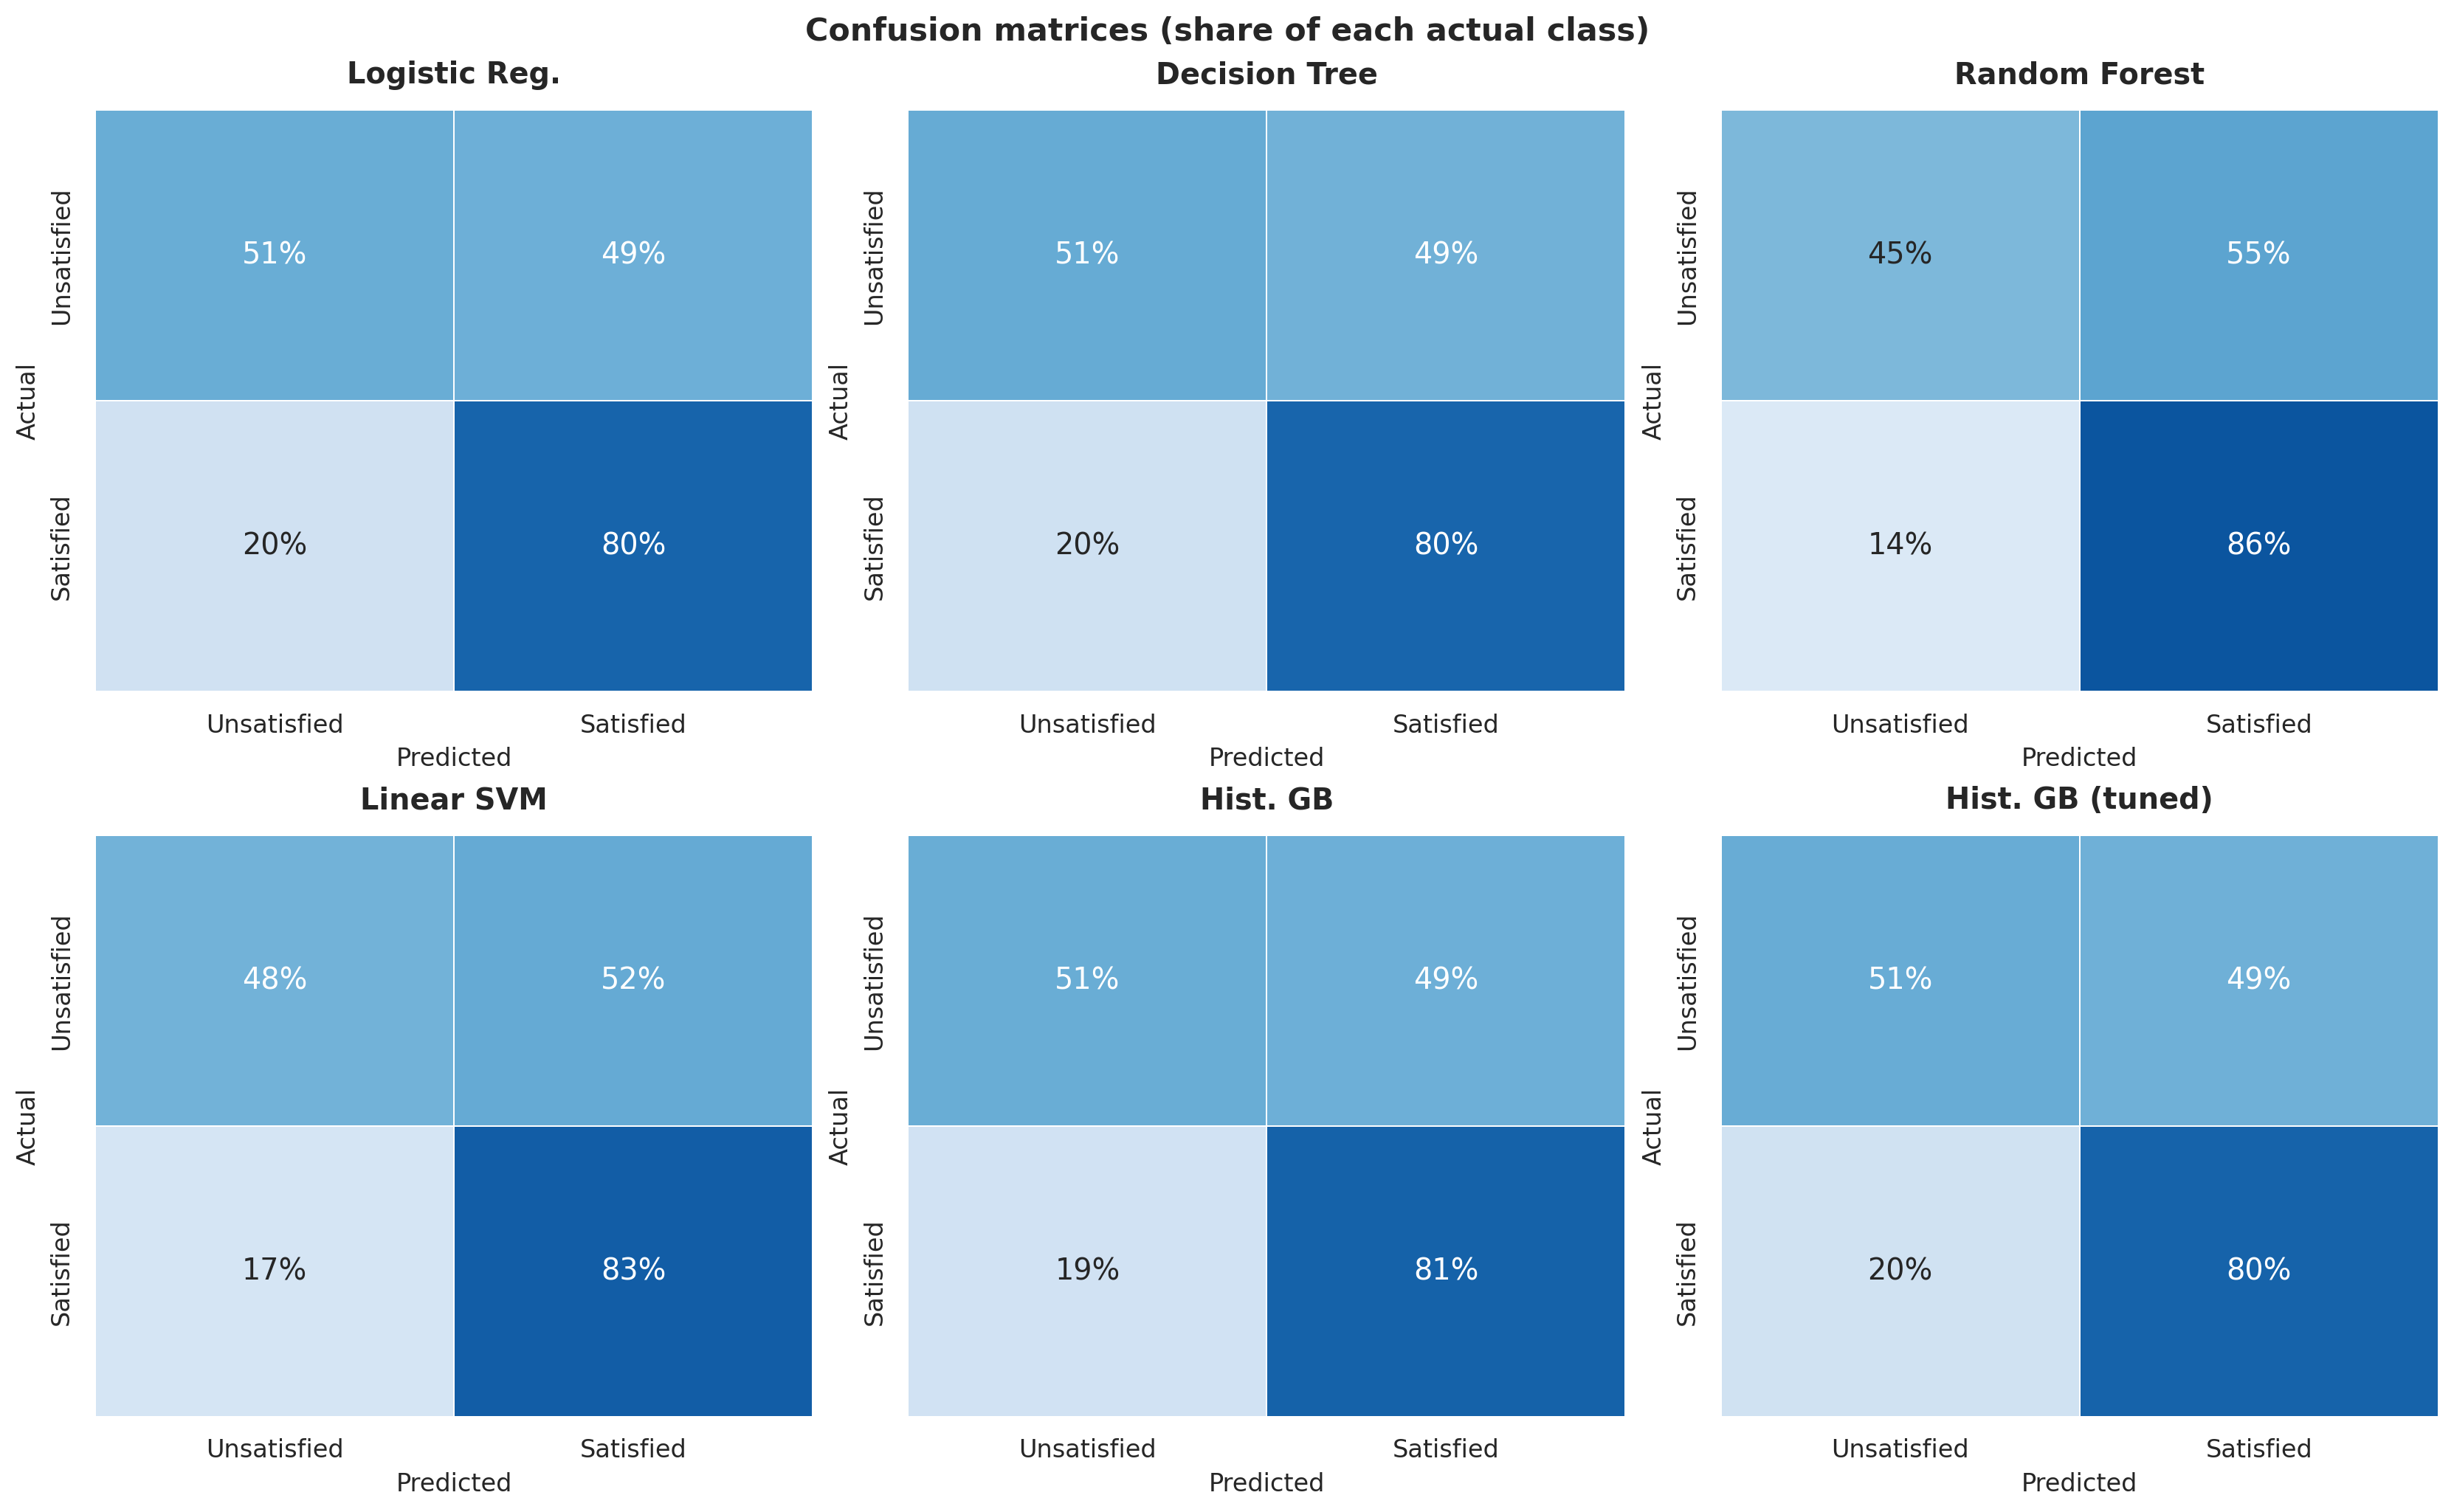

In [37]:
clf_comparison = pd.DataFrame(clf_rows)
best_name = clf_comparison.loc[clf_comparison['ROC-AUC'].idxmax(), 'Model']
best_clf = fitted_clf[best_name]
clf_comparison.insert(0, '🏆', np.where(clf_comparison['Model'] == best_name, '🏆', ''))

show(clf_comparison, f'🤖 Classifier comparison  (majority baseline accuracy = {baseline_acc:.1%})',
     heat=['Accuracy', 'Precision', 'Recall', 'F1', 'Macro F1', 'ROC-AUC'], cmap='YlGn', precision=3)
print(f'🏆 Best by ROC-AUC: {best_name}  ({clf_comparison["ROC-AUC"].max():.3f})')

# Chart 1 — metric comparison
plot_df = clf_comparison.set_index('Model')[['Accuracy', 'Macro F1', 'ROC-AUC']]
fig, ax = new_fig(12, 5.8)
plot_df.plot(kind='bar', ax=ax, color=[C['blue'], C['orange'], C['green']], width=.8, edgecolor='white')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8, padding=2)
ax.axhline(baseline_acc, color='black', ls='--', lw=1, label=f'Majority baseline accuracy {baseline_acc:.2f}')
ax.set_ylim(0, 1.25); ax.set_xlabel(''); ax.set_ylabel('Score')
ax.set_title('Classifier comparison — Accuracy, Macro F1, ROC-AUC')
ax.legend(ncol=2, loc='upper center')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
plt.show()

# Chart 2 — ROC curves
fig, ax = new_fig(8.5, 6.5)
for name, score in clf_scores.items():
    fpr, tpr, _ = roc_curve(y_te_c, score)
    ax.plot(fpr, tpr, lw=3 if name == best_name else 1.5, label=f'{name} (AUC {roc_auc_score(y_te_c, score):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
ax.set_title('ROC curves'); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.legend(loc='lower right')
plt.show()

# Chart 3 — confusion matrices, one panel per model (same chart type, so they share a grid)
n_cols = 3
n_rows = int(np.ceil(len(clf_preds) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.6 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax, (name, pred) in zip(axes, clf_preds.items()):
    sns.heatmap(confusion_matrix(y_te_c, pred, normalize='true'), annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1,
                cbar=False, linewidths=.5, annot_kws={'size': 13}, xticklabels=['Unsatisfied', 'Satisfied'],
                yticklabels=['Unsatisfied', 'Satisfied'], ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
for ax in axes[len(clf_preds):]:
    ax.set_visible(False)
fig.suptitle('Confusion matrices (share of each actual class)', fontsize=14, fontweight='bold')
plt.show()

### 6.5 — Feature Importance
Permutation importance on held-out data: how much ROC-AUC drops when one feature is shuffled. It works for any model and reports the original feature, not one-hot fragments.

⏱️  Permutation importance: 4.2s


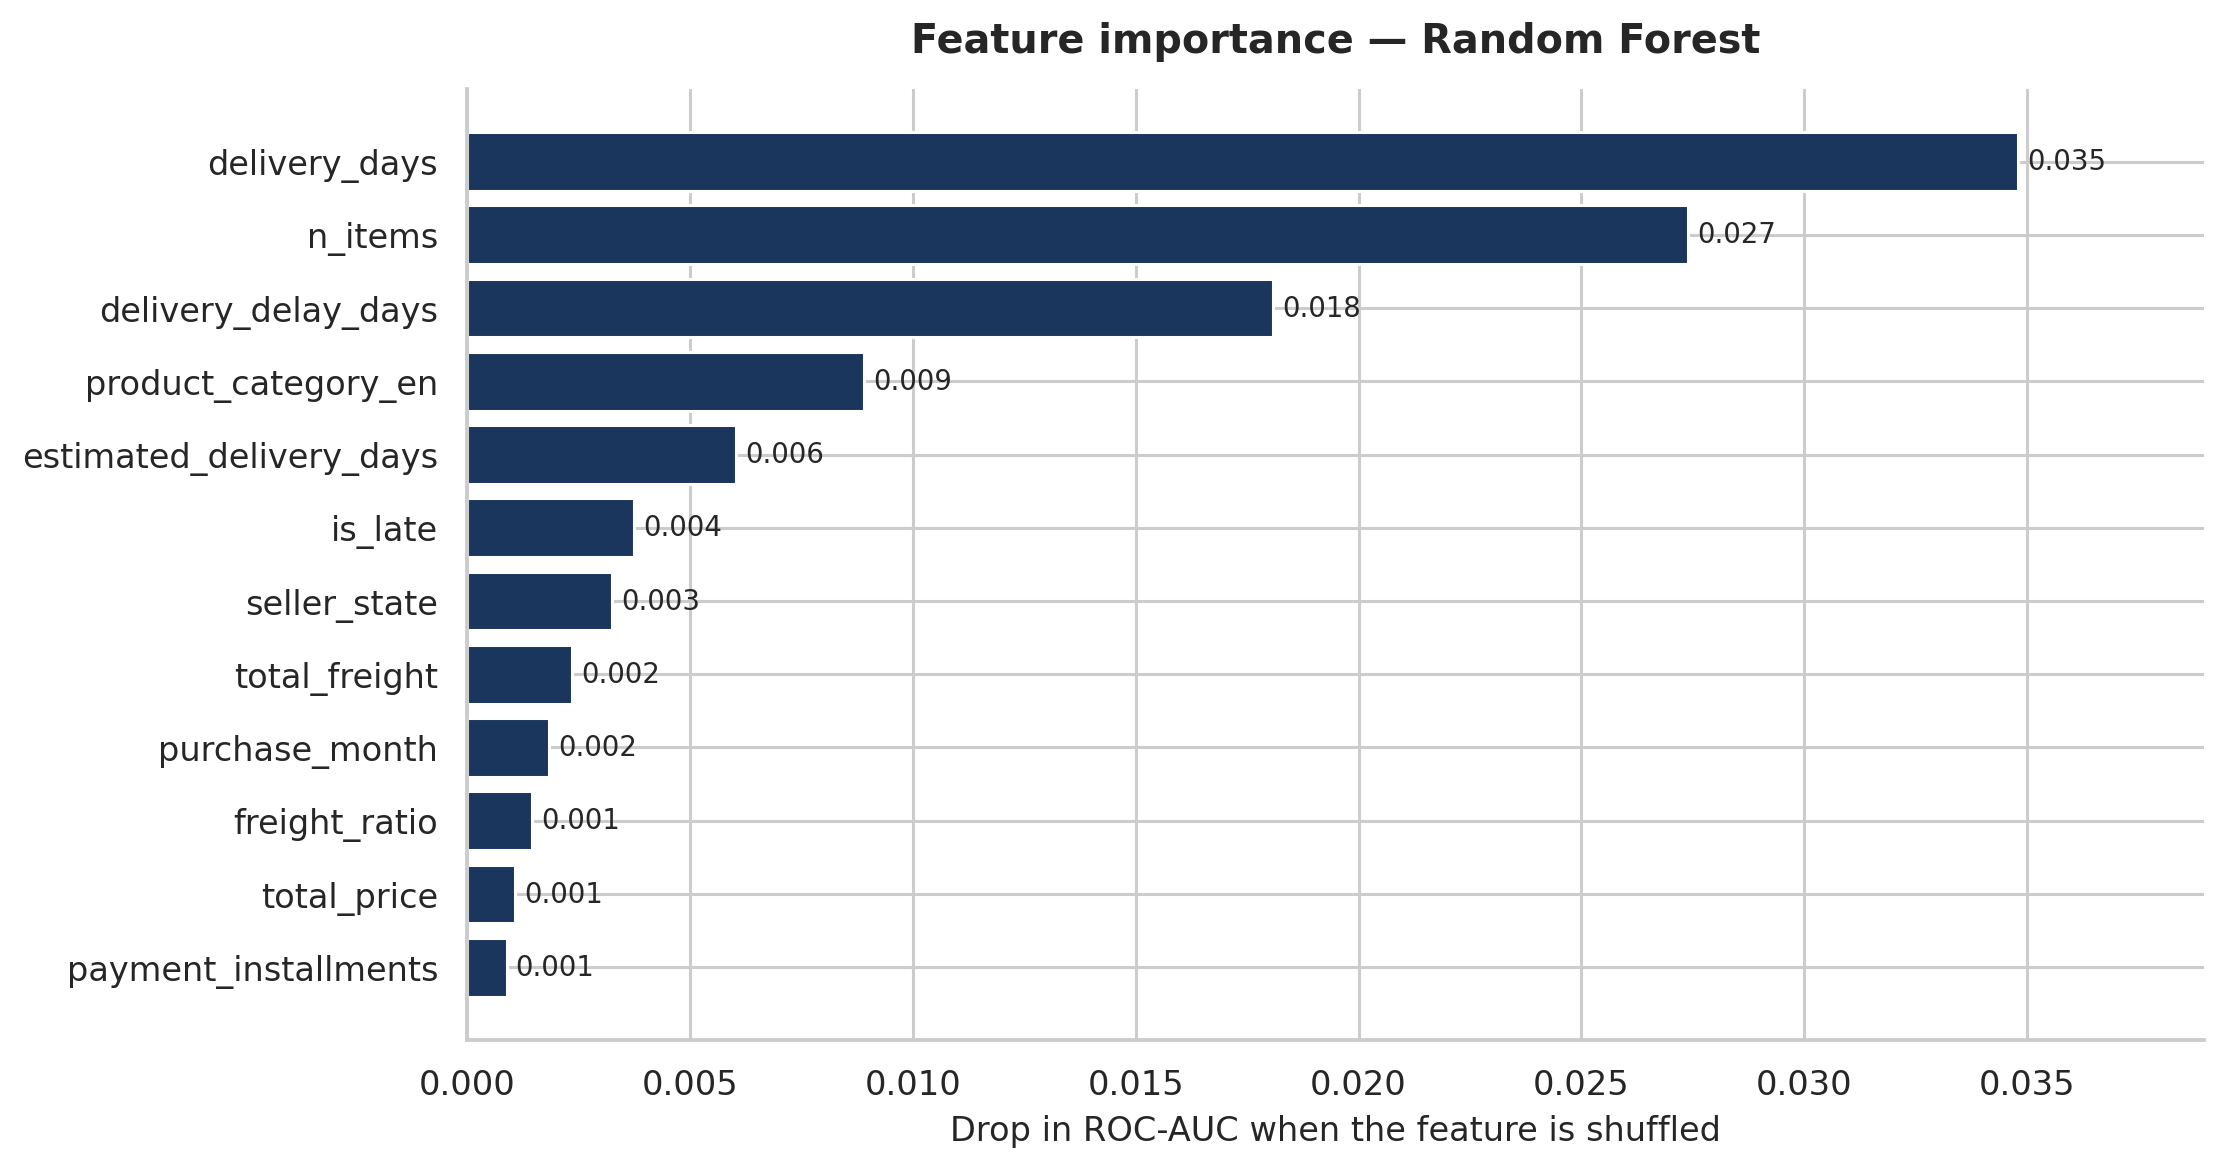


🔑 Top 5 drivers of satisfaction
─────────────────────────────────
  1. delivery_days              0.0348
  2. n_items                    0.0274
  3. delivery_delay_days        0.0181
  4. product_category_en        0.0089
  5. estimated_delivery_days    0.0060


In [38]:
sample = X_te_c.sample(min(5000, len(X_te_c)), random_state=SEED)
with timed('Permutation importance'):
    pi = permutation_importance(best_clf, sample, y_te_c.loc[sample.index], scoring='roc_auc',
                                n_repeats=3, random_state=SEED, n_jobs=1)
feat_imp = pd.Series(pi.importances_mean, index=sample.columns).sort_values(ascending=False)

top = feat_imp.head(12).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.2))
bars = ax.barh(top.index, top.values, color=C['navy'])
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_title(f'Feature importance — {best_name}')
ax.set_xlabel('Drop in ROC-AUC when the feature is shuffled')
ax.margins(x=.12)
plt.show()

banner('Top 5 drivers of satisfaction', '🔑')
for rank, (feat, val) in enumerate(feat_imp.head(5).items(), 1):
    print(f'  {rank}. {feat:<26} {val:.4f}')

### 6.6 — Predictions and Risk Tiers
Every modelled order gets a satisfaction score. The `split` column says whether the row was in the training or the held-out test set, so nobody mistakes training rows for honest accuracy.

Tiers are rank-based: the lowest scores (as many as the expected share of unsatisfied customers) are High Risk, the next 30% Medium, the rest Low. The thresholds are learned from the training rows. Scores come from class-balanced models, so read them as a ranking, not as exact probabilities. A good model shows a clear gap in *Actually satisfied %* between tiers.

In [39]:
score_all = score_of(best_clf, X_cls)
is_train = ~X_cls.index.isin(X_te_c.index)

# Thresholds come from the training scores: the lowest scores (as many as the expected share of unsatisfied
# customers) are High Risk, the next 30% Medium, everything else Low
unsat_share = 1 - y_tr_c.mean()
t_high, t_medium = np.quantile(score_all[is_train], [unsat_share, min(unsat_share + .30, .95)])

predictions_df = pd.DataFrame({
    'order_id': cls_df.loc[X_cls.index, 'order_id'].to_numpy(),
    'actual_satisfied': y_cls.to_numpy(),
    'predicted_satisfied': best_clf.predict(X_cls),
    'satisfaction_probability': score_all.round(4),
    'split': np.where(is_train, 'train', 'test'),
})
predictions_df['risk_level'] = np.select([score_all < t_high, score_all < t_medium], ['High Risk', 'Medium Risk'], 'Low Risk')

tiers = ['High Risk', 'Medium Risk', 'Low Risk']
held_out = predictions_df[predictions_df['split'] == 'test']
risk_summary = (held_out.groupby('risk_level')
                .agg(orders=('order_id', 'size'), actual_satisfied_rate=('actual_satisfied', 'mean'))
                .reindex(tiers).reset_index())
risk_summary['share_of_orders'] = risk_summary['orders'] / risk_summary['orders'].sum()
risk_summary['risk_level'] = ['🔴 High Risk', '🟠 Medium Risk', '🟢 Low Risk']

pretty = risk_summary.rename(columns={'risk_level': 'Risk level', 'orders': 'Orders',
                                      'actual_satisfied_rate': 'Actually satisfied %', 'share_of_orders': 'Share of orders %'})
pretty[['Actually satisfied %', 'Share of orders %']] *= 100
show(pretty, '🎯 Risk tiers on the held-out test set', heat=['Actually satisfied %'], cmap='RdYlGn', precision=1)
print(f'Thresholds (satisfaction score): High Risk < {t_high:.3f}  |  Medium < {t_medium:.3f}  |  Low ≥ {t_medium:.3f}')
print(f'{len(predictions_df):,} orders scored  |  test rows: {len(held_out):,}')
show(predictions_df.head(5), '🔮 Sample predictions', precision=3)

Risk level,Orders,Actually satisfied %,Share of orders %
🔴 High Risk,"4,038",54.1,21.1
🟠 Medium Risk,"5,850",82.0,30.5
🟢 Low Risk,"9,278",87.7,48.4


Thresholds (satisfaction score): High Risk < 0.504  |  Medium < 0.597  |  Low ≥ 0.597
95,830 orders scored  |  test rows: 19,166


order_id,actual_satisfied,predicted_satisfied,satisfaction_probability,split,risk_level
e481f51cbdc54678b7cc49136f2d6af7,1,1,0.612,train,Low Risk
53cdb2fc8bc7dce0b6741e2150273451,1,1,0.612,train,Low Risk
47770eb9100c2d0c44946d9cf07ec65d,1,1,0.617,train,Low Risk
949d5b44dbf5de918fe9c16f97b45f8a,1,1,0.621,train,Low Risk
ad21c59c0840e6cb83a9ceb5573f8159,1,1,0.669,train,Low Risk


### 6.7 — Delivery-Time Regression
Two naive baselines are included: always predicting the mean, and Olist's own estimated delivery date. A model is only useful if it beats both.

⏱️  Training 3 regressors: 61.2s


Model,MAE (days),RMSE (days),R²,Fit time (s)
Baseline: mean,6.464,9.571,-0.000,–
Baseline: Olist estimate,12.863,15.209,-1.525,–
Linear Reg.,5.280,8.375,0.234,2.596
Random Forest,4.834,7.867,0.324,55.523
Hist. GB,4.785,7.808,0.334,1.836


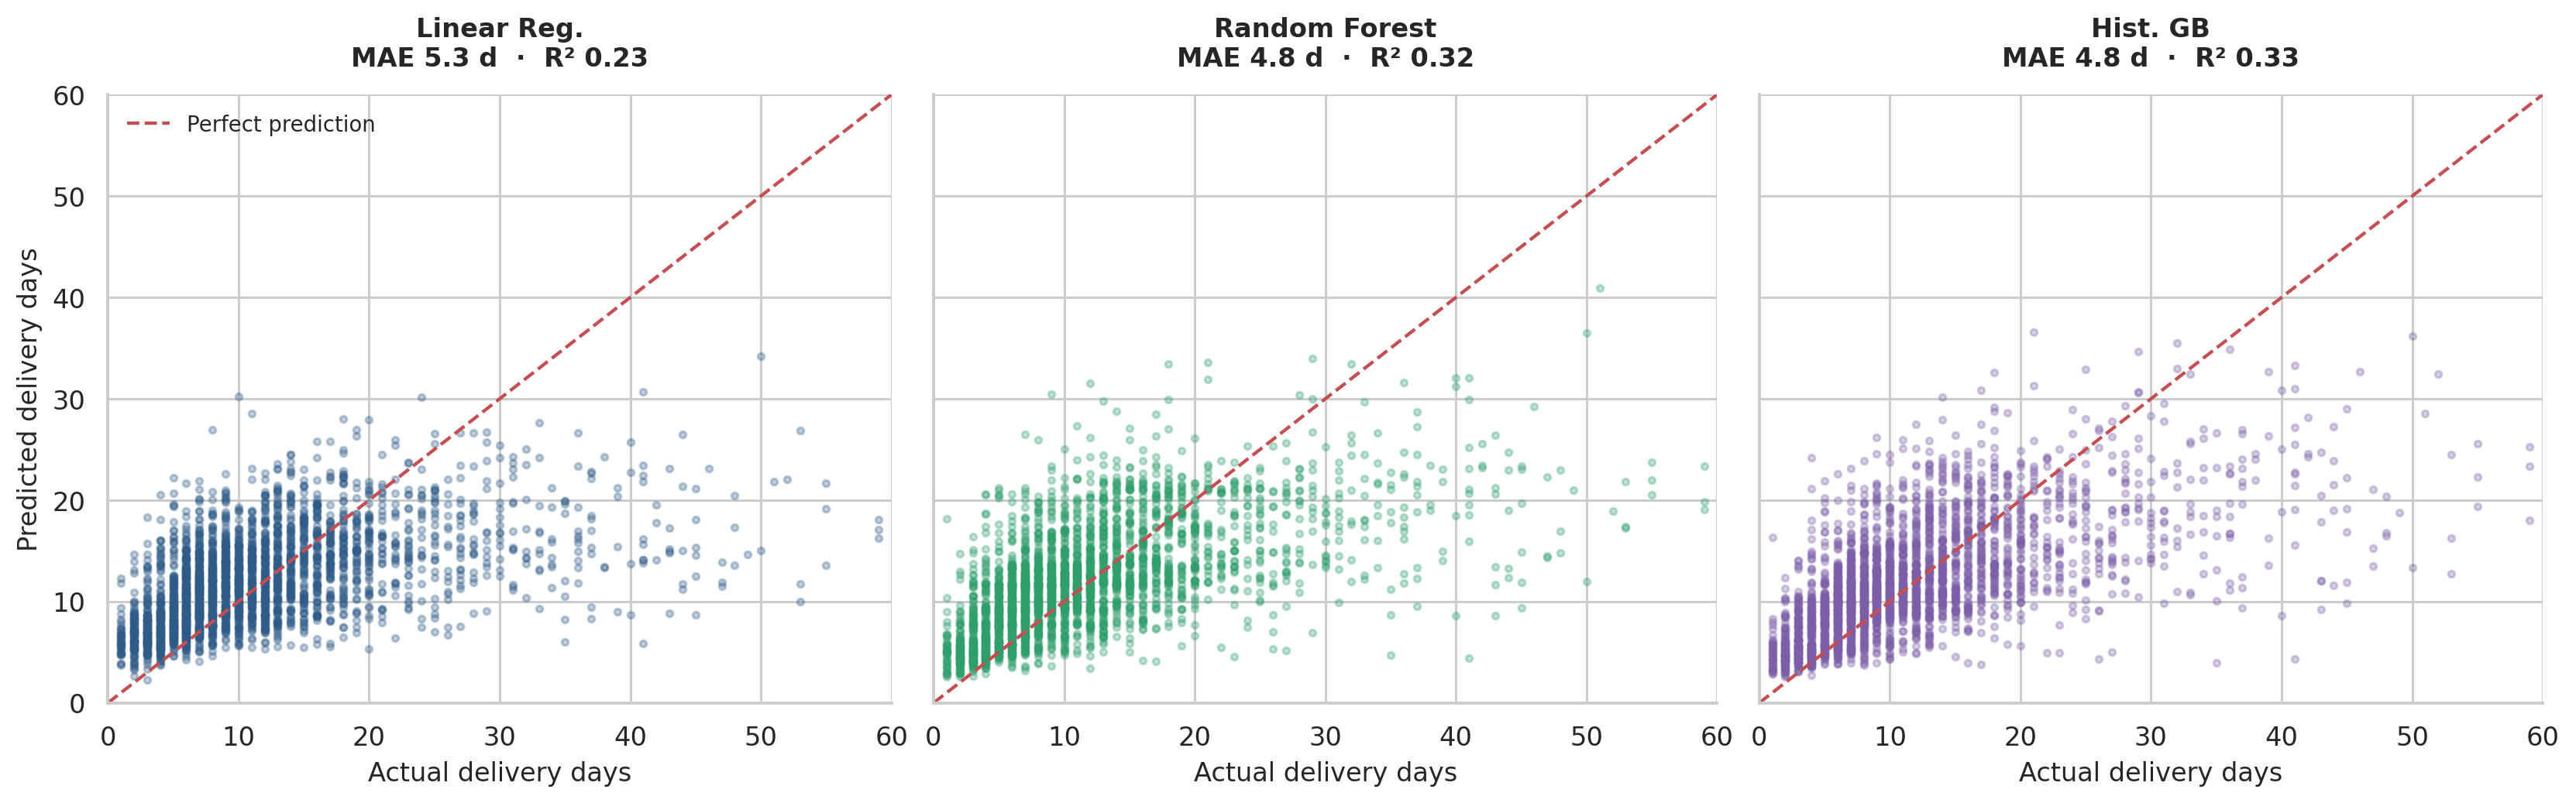

In [46]:
def reg_pipe(prep, estimator):
    return Pipeline([('prep', prep), ('model', estimator)])

regressors = {
    'Linear Reg.':   reg_pipe(linear_prep(REG_NUM, REG_CAT), LinearRegression()),
    'Random Forest': reg_pipe(linear_prep(REG_NUM, REG_CAT),
                              RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=10,
                                                    n_jobs=-1, random_state=SEED)),
    'Hist. GB':      reg_pipe(tree_prep(REG_NUM, REG_CAT),
                              HistGradientBoostingRegressor(categorical_features=cat_mask(REG_NUM, REG_CAT), max_iter=300,
                                                            early_stopping=True, n_iter_no_change=15, random_state=SEED)),
}

def reg_metrics(name, pred, secs=None):
    return {'Model': name, 'MAE (days)': mean_absolute_error(y_te_r, pred),
            'RMSE (days)': np.sqrt(mean_squared_error(y_te_r, pred)), 'R²': r2_score(y_te_r, pred), 'Fit time (s)': secs}

reg_rows = [reg_metrics('Baseline: mean', np.full(len(y_te_r), y_tr_r.mean())),
            reg_metrics('Baseline: Olist estimate', X_te_r['estimated_delivery_days'].fillna(y_tr_r.mean()))]
reg_preds, fitted_reg = {}, {}

with timed('Training 3 regressors'):
    for name, model in regressors.items():
        t0 = time.perf_counter()
        model.fit(X_tr_r, y_tr_r)
        secs = time.perf_counter() - t0
        reg_preds[name], fitted_reg[name] = model.predict(X_te_r), model
        reg_rows.append(reg_metrics(name, reg_preds[name], secs))

reg_comparison = pd.DataFrame(reg_rows)
show(reg_comparison, '📏 Regression comparison (lower MAE / RMSE is better)', heat=['R²'], cmap='YlGn', precision=3)

# Actual vs predicted: three small charts side by side
idx = np.random.default_rng(SEED).choice(len(y_te_r), min(3000, len(y_te_r)), replace=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, (name, pred), color in zip(axes, reg_preds.items(), (C['blue'], C['green'], C['purple'])):
    m = reg_comparison.set_index('Model').loc[name]
    ax.scatter(y_te_r.iloc[idx], pred[idx], s=8, alpha=.3, color=color)
    ax.plot([0, 60], [0, 60], 'r--', lw=1.4, label='Perfect prediction')
    ax.set_title(f'{name}\nMAE {m["MAE (days)"]:.1f} d  ·  R² {m["R²"]:.2f}', fontsize=11)
    ax.set_xlabel('Actual delivery days')
    ax.set_xlim(0, 60); ax.set_ylim(0, 60)
axes[0].set_ylabel('Predicted delivery days')
axes[0].legend(loc='upper left', fontsize=9)
plt.show()

## Part 7 — Business Insights
The report below is generated from the results above. Nothing in it is typed in by hand.

In [47]:
d = fact_orders.dropna(subset=['is_late', 'is_satisfied'])
on_time_sat, late_sat = d.loc[d['is_late'] == 0, 'is_satisfied'].mean(), d.loc[d['is_late'] == 1, 'is_satisfied'].mean()
late_rate = (fact_orders['is_late'] == 1).sum() / fact_orders['is_late'].notna().sum()

state_stats = (fact_orders.groupby('customer_state')
               .agg(orders=('order_id', 'size'), avg_days=('delivery_days', 'mean'), satisfied=('is_satisfied', 'mean')))
big_states = state_stats[state_stats['orders'] >= 0.01 * len(fact_orders)]
slowest, fastest = big_states.nlargest(3, 'avg_days'), big_states.nsmallest(1, 'avg_days')

pay_stats = (fact_orders.dropna(subset=['is_satisfied']).groupby('payment_type')
             .agg(orders=('order_id', 'size'), satisfied=('is_satisfied', 'mean')))
pay_stats = pay_stats[pay_stats['orders'] >= 0.01 * pay_stats['orders'].sum()]

cat_rev = fact_order_items.groupby('product_category_en')['price'].sum().sort_values(ascending=False)
best_row = clf_comparison[clf_comparison['Model'] == best_name].iloc[0]
reg_models = reg_comparison[~reg_comparison['Model'].str.startswith('Baseline')]
best_reg = reg_models.loc[reg_models['MAE (days)'].idxmin()]
olist_mae = reg_comparison.loc[reg_comparison['Model'] == 'Baseline: Olist estimate', 'MAE (days)'].iloc[0]

kpi = dict(orders=len(fact_orders), revenue=fact_orders['total_price'].sum(), freight=fact_orders['total_freight'].sum(),
           avg_days=fact_orders['delivery_days'].mean(), on_time=1 - late_rate,
           satisfaction=fact_orders['is_satisfied'].mean())
kpi['aov'] = kpi['revenue'] / kpi['orders']

banner('Executive summary', '📑')
print(f"  🛒 Orders            : {kpi['orders']:,}")
print(f"  💰 Revenue           : R$ {kpi['revenue']:,.0f}   (average order R$ {kpi['aov']:,.2f})")
print(f"  🏷️  Top category      : {cat_rev.index[0]}  (R$ {cat_rev.iloc[0]:,.0f})")
print(f"  🚚 Avg delivery time : {kpi['avg_days']:.1f} days   |   on-time rate {kpi['on_time']:.1%}")
print(f"  😊 Satisfaction      : {kpi['satisfaction']:.1%} of reviewed orders")
print(f"  🤖 Best classifier   : {best_name}  (ROC-AUC {best_row['ROC-AUC']:.3f}, accuracy {best_row['Accuracy']:.1%})")
print(f"  ⏱️  Best regressor    : {best_reg['Model']}  (MAE {best_reg['MAE (days)']:.1f} days vs Olist estimate {olist_mae:.1f})")

if best_reg['MAE (days)'] < olist_mae:
    reg_evidence = f"{best_reg['Model']} is off by {best_reg['MAE (days)']:.1f} days on average vs {olist_mae:.1f} for Olist's estimate."
    reg_action = 'Use the model to set the promised delivery date at checkout.'
else:
    reg_evidence = f"Olist's own estimate (MAE {olist_mae:.1f} days) is still better than the best model ({best_reg['MAE (days)']:.1f})."
    reg_action = 'Add seller dispatch and carrier data before using a model for promised dates.'

findings = [
    ('Late delivery drives dissatisfaction',
     f'{on_time_sat:.1%} of on-time orders are satisfied vs {late_sat:.1%} of late ones; {late_rate:.1%} of deliveries are late.',
     'Escalate shipments that stall and promise dates the carrier can really meet.'),
    ('Delivery time varies a lot by region',
     'Slowest large states: ' + ', '.join(f'{s} ({r.avg_days:.1f} d)' for s, r in slowest.iterrows())
     + f'. Fastest: {fastest.index[0]} ({fastest.iloc[0]["avg_days"]:.1f} d).',
     'Review carriers and consider regional fulfilment for the slowest states.'),
    ('Satisfaction can be flagged early',
     f"{best_name} reaches ROC-AUC {best_row['ROC-AUC']:.3f}; the strongest driver is {feat_imp.index[0]}.",
     'Contact High Risk orders proactively (status update, voucher) before a bad review appears.'),
    ('Promised delivery dates can be improved', reg_evidence, reg_action),
    ('Payment method and satisfaction',
     f"Highest: {pay_stats['satisfied'].idxmax()} ({pay_stats['satisfied'].max():.1%}); "
     f"lowest: {pay_stats['satisfied'].idxmin()} ({pay_stats['satisfied'].min():.1%}).",
     'Check whether the gap comes from payment friction or from the products and regions behind it.'),
    ('Demand is concentrated',
     f"{state_counts.index[0]} has {state_counts.iloc[0] / state_counts.sum():.1%} of orders; "
     f"{cat_rev.index[0]} leads revenue with {cat_rev.iloc[0] / cat_rev.sum():.1%}.",
     'Protect service levels in the top state and category; test growth in the others.'),
]
findings_df = pd.DataFrame(findings, columns=['Finding', 'Evidence (from the data)', 'Suggested action'])
show(findings_df, '💡 Findings and actions')
print(f"\nℹ️  Satisfaction uses only the {fact_orders['is_satisfied'].notna().sum():,} orders that have a review; "
      f"{fact_orders['is_satisfied'].isna().sum():,} orders without one are excluded, not counted as unsatisfied.")


📑 Executive summary
─────────────────────
  🛒 Orders            : 99,441
  💰 Revenue           : R$ 13,591,644   (average order R$ 136.68)
  🏷️  Top category      : health_beauty  (R$ 1,258,681)
  🚚 Avg delivery time : 12.1 days   |   on-time rate 92.4%
  😊 Satisfaction      : 77.1% of reviewed orders
  🤖 Best classifier   : Random Forest  (ROC-AUC 0.710, accuracy 77.4%)
  ⏱️  Best regressor    : Hist. GB  (MAE 4.8 days vs Olist estimate 12.9)


Finding,Evidence (from the data),Suggested action
Late delivery drives dissatisfaction,82.7% of on-time orders are satisfied vs 31.8% of late ones; 7.6% of deliveries are late.,Escalate shipments that stall and promise dates the carrier can really meet.
Delivery time varies a lot by region,"Slowest large states: CE (20.8 d), BA (18.9 d), PE (18.0 d). Fastest: SP (8.3 d).",Review carriers and consider regional fulfilment for the slowest states.
Satisfaction can be flagged early,Random Forest reaches ROC-AUC 0.710; the strongest driver is delivery_days.,"Contact High Risk orders proactively (status update, voucher) before a bad review appears."
Promised delivery dates can be improved,Hist. GB is off by 4.8 days on average vs 12.9 for Olist's estimate.,Use the model to set the promised delivery date at checkout.
Payment method and satisfaction,Highest: debit_card (79.3%); lowest: voucher (73.8%).,Check whether the gap comes from payment friction or from the products and regions behind it.
Demand is concentrated,SP has 42.0% of orders; health_beauty leads revenue with 9.3%.,Protect service levels in the top state and category; test growth in the others.



ℹ️  Satisfaction uses only the 98,673 orders that have a review; 768 orders without one are excluded, not counted as unsatisfied.


## Part 8 — Excel Report (`xlsxwriter`)
Seven formatted sheets: summary cards, cleaning audit, EDA tables with native charts, ML results, insights, DAX + schema notes, and the full `fact_orders` table.
`xlsxwriter` writes columns in bulk and is several times faster than filling cells one by one with `openpyxl`. Every number comes from the notebook's variables.

In [48]:
import xlsxwriter
from math import ceil

NAVY, BLUE, ZEBRA, GRID = C['navy'], C['blue'], '#F3F6FA', '#D9E0EA'
SHEETS = dict(summary='🏠 Summary', clean='🧹 Data Cleaning', eda='📊 EDA', ml='🤖 ML Results',
              insights='💡 Insights', dax='🧩 DAX & Steps', data='📦 fact_orders')


DAX_MEASURES = [
    ('Total Orders', 'Total Orders = COUNTROWS(fact_orders)', '#,##0', 'Order volume'),
    ('Total Revenue', 'Total Revenue = SUM(fact_orders[total_price])', '#,##0.00', 'Gross merchandise value'),
    ('Total Freight', 'Total Freight = SUM(fact_orders[total_freight])', '#,##0.00', 'Shipping charged'),
    ('Average Order Value', 'Average Order Value = DIVIDE([Total Revenue], [Total Orders])', '#,##0.00', 'Revenue per order'),
    ('Average Review Score', 'Average Review Score = AVERAGE(fact_orders[review_score])', '0.00', 'Mean rating (1-5)'),
    ('Average Delivery Days', 'Average Delivery Days = AVERAGE(fact_orders[delivery_days])', '0.0', 'Purchase → delivery'),
    ('Late Delivery %', 'Late Delivery % = DIVIDE(CALCULATE(COUNTROWS(fact_orders), fact_orders[is_late] = 1), '
                        'CALCULATE(COUNTROWS(fact_orders), NOT(ISBLANK(fact_orders[is_late]))))', '0.0%', 'Share of delivered orders that were late'),
    ('Customer Satisfaction %', 'Customer Satisfaction % = DIVIDE(CALCULATE(COUNTROWS(fact_orders), fact_orders[is_satisfied] = 1), '
                                'CALCULATE(COUNTROWS(fact_orders), NOT(ISBLANK(fact_orders[is_satisfied]))))', '0.0%', 'Share of reviewed orders scoring 4-5'),
    ('High-Risk Orders', 'High-Risk Orders = CALCULATE(COUNTROWS(fact_predictions), fact_predictions[risk_level] = "High Risk")',
     '#,##0', 'Orders flagged by the model'),
    ('Predicted Dissatisfied', 'Predicted Dissatisfied = CALCULATE(COUNTROWS(fact_predictions), fact_predictions[predicted_satisfied] = 0)',
     '#,##0', 'Orders predicted unsatisfied'),
]


def to_cells(s):
    """Series → list that xlsxwriter accepts: NaN/NA → None, datetimes → Excel serial numbers."""
    if pd.api.types.is_datetime64_any_dtype(s):
        s = (s - pd.Timestamp('1899-12-30')) / pd.Timedelta(days=1)
    elif pd.api.types.is_extension_array_dtype(s) and pd.api.types.is_numeric_dtype(s):
        s = s.astype('float64')
    values = s.tolist()
    for i in np.flatnonzero(s.isna().to_numpy()):
        values[i] = None
    return values


def build_excel_report(path):
    wb = xlsxwriter.Workbook(str(path), {'strings_to_urls': False, 'strings_to_formulas': False})
    wb.set_properties({'title': 'Olist Analytics Report', 'subject': 'E-commerce analytics & ML',
                       'comments': 'Generated by the Olist end-to-end notebook'})
    cache = {}

    def F(**props):
        base = {'font_name': 'Calibri', 'font_size': 10, 'valign': 'vcenter'}
        base.update(props)
        key = tuple(sorted(base.items()))
        if key not in cache:
            cache[key] = wb.add_format(base)
        return cache[key]

    def section(ws, row, text, col=0):
        ws.write(row, col, text, F(bold=True, font_size=12, font_color=BLUE))
        return row + 1

    def sheet(key, color):
        ws = wb.add_worksheet(SHEETS[key])
        ws.set_tab_color(color)
        ws.hide_gridlines(2)
        return ws

    def table(ws, row, col, df, fmts=None, widths=None, heat=None, bars=(), wrap=(), zebra=True, code_cols=()):
        """Write a DataFrame with header, borders, zebra rows, optional heat-maps / data bars. Returns the next free row."""
        fmts, heat = fmts or {}, heat or {}
        n = len(df)
        hdr = F(bold=True, font_color='#FFFFFF', bg_color=NAVY, align='center', text_wrap=True, border=1, border_color=GRID)
        ws.set_row(row, 30)
        for j, name in enumerate(df.columns):
            ws.write(row, col + j, str(name), hdr)
            s = df[name]
            is_num = pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
            if pd.api.types.is_datetime64_any_dtype(s):
                nf = fmts.get(name, 'yyyy-mm-dd hh:mm')
            elif is_num:
                nf = fmts.get(name, '#,##0' if pd.api.types.is_integer_dtype(s) else '#,##0.00')
            else:
                nf = fmts.get(name, '@')
            props = dict(num_format=nf, border=1, border_color=GRID, align='right' if is_num else 'left',
                         text_wrap=name in wrap)
            if name in code_cols:
                props.update(font_name='Consolas', font_size=9, font_color='#0F2C59', bg_color='#F1F5F9')
            ws.write_column(row + 1, col + j, to_cells(s), F(**props))
            if widths and name in widths:
                ws.set_column(col + j, col + j, widths[name])
            first, last = row + 1, row + n
            if name in heat and n:
                good_high = heat[name] == 'high'
                lo, hi = ('#F8696B', '#63BE7B') if good_high else ('#63BE7B', '#F8696B')
                ws.conditional_format(first, col + j, last, col + j,
                                      {'type': '3_color_scale', 'min_color': lo, 'mid_color': '#FFEB84', 'max_color': hi})
            if name in bars and n:
                ws.conditional_format(first, col + j, last, col + j,
                                      {'type': 'data_bar', 'bar_color': '#9CC3E6', 'bar_solid': True})
        if zebra and n:
            ws.conditional_format(row + 1, col, row + n, col + df.shape[1] - 1,
                                  {'type': 'formula', 'criteria': '=MOD(ROW(),2)=0', 'format': wb.add_format({'bg_color': ZEBRA})})
        if wrap and widths:
            for i, rec in enumerate(df.itertuples(index=False)):
                lines = max((ceil(len(str(v)) / (widths.get(c, 12) * 1.05)) for c, v in zip(df.columns, rec) if c in wrap), default=1)
                ws.set_row(row + 1 + i, max(18, 14.5 * lines + 4))
        return row + n + 2

    # ───────────────────────── 🏠 Summary ─────────────────────────
    ws = sheet('summary', NAVY)
    ws.set_column(0, 0, 3); ws.set_column(1, 8, 17)
    ws.merge_range(1, 1, 1, 8, '🛒 Olist E-Commerce — Analytics Report', F(bold=True, font_size=20, font_color=NAVY))
    ws.merge_range(2, 1, 2, 8, f"Generated {pd.Timestamp.now():%Y-%m-%d %H:%M}  ·  {kpi['orders']:,} orders  ·  "
                   f"{fact_orders['order_purchase_timestamp'].min():%b %Y} – {fact_orders['order_purchase_timestamp'].max():%b %Y}",
                   F(italic=True, font_color='#5B6573'))
    cards = [('🛒 Orders', f"{kpi['orders']:,}", BLUE), ('💰 Revenue', f"R$ {kpi['revenue']:,.0f}", C['green']),
             ('🧾 Avg order value', f"R$ {kpi['aov']:,.2f}", C['teal']), ('🚚 Avg delivery', f"{kpi['avg_days']:.1f} days", C['purple']),
             ('⏱️ On-time rate', f"{kpi['on_time']:.1%}", C['green']), ('😊 Satisfaction', f"{kpi['satisfaction']:.1%}", C['orange']),
             ('🤖 Best model', best_name, NAVY), ('📈 ROC-AUC', f"{best_row['ROC-AUC']:.3f}", C['red'])]
    for i, (label, value, color) in enumerate(cards):
        r, c = 4 + (i // 4) * 4, 1 + (i % 4) * 2
        ws.set_row(r, 20); ws.set_row(r + 1, 34)
        ws.merge_range(r, c, r, c + 1, label, F(bold=True, font_color='#FFFFFF', bg_color=color, align='center'))
        ws.merge_range(r + 1, c, r + 1, c + 1, value, F(bold=True, font_size=18, font_color=color, align='center',
                                                       bg_color='#F7F9FC', top=1, bottom=1, left=1, right=1, border_color=GRID))
    r = section(ws, 13, '📚 What is inside', 1)
    toc = [('clean', 'Cleaning audit: before/after per table, missing values, outliers, log'),
           ('eda', 'Top categories, states, payments and monthly trend (with charts)'),
           ('ml', 'Classifier and regressor comparison, feature importance, risk tiers'),
           ('insights', 'Findings and suggested actions'),
           ('dax', 'DAX measures, table lineage and relationships for Power BI'),
           ('data', 'Full cleaned fact_orders table (filters + frozen header)')]
    for key, text in toc:
        ws.write_url(r, 1, f"internal:'{SHEETS[key]}'!A1", F(font_color=BLUE, underline=1, bold=True), string=SHEETS[key])
        ws.merge_range(r, 3, r, 8, text, F())
        r += 1
    ws.merge_range(r + 1, 1, r + 1, 8, f"ℹ️ Satisfaction uses only orders with a review ({fact_orders['is_satisfied'].notna().sum():,}).",
                   F(italic=True, font_color='#5B6573'))

    # ───────────────────────── 🧹 Data Cleaning ─────────────────────────
    ws = sheet('clean', C['orange'])
    ws.write(0, 0, '🧹 Data Cleaning & Quality Audit', F(bold=True, font_size=16, font_color=NAVY))
    r = section(ws, 2, '1. Before vs after, per table')
    r = table(ws, r, 0, quality_summary, bars=('Duplicates removed',), widths={'Table': 16})
    r = section(ws, r, '2. Missing-value treatment (from the audit log)')
    miss_tbl = log_df.loc[log_df['step'] == 'missing', ['table', 'column', 'issue', 'action', 'affected']]
    miss_tbl.columns = ['Table', 'Column', 'Issue', 'Action', 'Values affected']
    r = table(ws, r, 0, miss_tbl, bars=('Values affected',), widths={'Column': 30, 'Issue': 22, 'Action': 38})
    r = section(ws, r, '3. Outlier detection (IQR) on the final fact_orders')
    r = table(ws, r, 0, detect_outliers(fact_orders, ['total_price', 'total_freight', 'delivery_days']),
              heat={'Outlier %': 'low'})
    r = section(ws, r, '4. Audit log by step')
    r = table(ws, r, 0, log_df.groupby('step').agg(entries=('column', 'size'), values_affected=('affected', 'sum')).reset_index())
    ws.set_column(0, 0, 16); ws.set_column(1, 7, 18)

    # ───────────────────────── 📊 EDA ─────────────────────────
    ws = sheet('eda', C['green'])
    ws.write(0, 0, '📊 Exploratory Data Analysis', F(bold=True, font_size=16, font_color=NAVY))
    ws.set_column(0, 0, 28); ws.set_column(1, 8, 15)

    cat_tbl = (fact_order_items.groupby('product_category_en').agg(revenue=('price', 'sum'), orders=('order_id', 'nunique'))
               .nlargest(10, 'revenue').reset_index())
    cat_tbl['share'] = cat_tbl['revenue'] / fact_order_items['price'].sum()
    cat_tbl.columns = ['Category', 'Revenue (BRL)', 'Orders', 'Share of revenue']
    r = section(ws, 2, '1. Top 10 categories by revenue')
    r0 = r
    r = table(ws, r, 0, cat_tbl, fmts={'Share of revenue': '0.0%'}, bars=('Revenue (BRL)',))
    ch = wb.add_chart({'type': 'bar'})
    ch.add_series({'name': 'Revenue (BRL)', 'categories': [SHEETS['eda'], r0 + 1, 0, r0 + len(cat_tbl), 0],
                   'values': [SHEETS['eda'], r0 + 1, 1, r0 + len(cat_tbl), 1], 'fill': {'color': BLUE},
                   'data_labels': {'value': True, 'num_format': '#,##0,"K"'}})
    ch.set_title({'name': 'Top 10 categories by revenue'}); ch.set_legend({'none': True})
    ch.set_y_axis({'reverse': True}); ch.set_size({'width': 560, 'height': 330})
    ws.insert_chart(2, 6, ch)

    state_tbl = (fact_orders.groupby('customer_state')
                 .agg(orders=('order_id', 'size'), revenue=('total_price', 'sum'), delivery=('delivery_days', 'mean'),
                      late=('is_late', 'mean'), satisfied=('is_satisfied', 'mean')).nlargest(15, 'orders').reset_index())
    state_tbl.columns = ['State', 'Orders', 'Revenue (BRL)', 'Avg delivery (days)', 'Late %', 'Satisfied %']
    r = section(ws, r, '2. Top 15 states')
    r = table(ws, r, 0, state_tbl, fmts={'Late %': '0.0%', 'Satisfied %': '0.0%', 'Avg delivery (days)': '0.0'},
              heat={'Avg delivery (days)': 'low', 'Late %': 'low', 'Satisfied %': 'high'}, bars=('Orders',))

    pay_tbl = (fact_orders.groupby('payment_type').agg(orders=('order_id', 'size'), revenue=('payment_value', 'sum'),
                                                       satisfied=('is_satisfied', 'mean')).sort_values('orders', ascending=False).reset_index())
    pay_tbl['share'] = pay_tbl['orders'] / pay_tbl['orders'].sum()
    pay_tbl.columns = ['Payment type', 'Orders', 'Payment value (BRL)', 'Satisfied %', 'Share of orders']
    r = section(ws, r, '3. Payment types')
    r = table(ws, r, 0, pay_tbl, fmts={'Satisfied %': '0.0%', 'Share of orders': '0.0%'}, heat={'Satisfied %': 'high'})

    mt = monthly[['year_month', 'orders', 'revenue', 'avg_score']].copy()
    mt.columns = ['Month', 'Orders', 'Revenue (BRL)', 'Avg review score']
    r = section(ws, r, '4. Monthly trend')
    r0 = r
    r = table(ws, r, 0, mt, fmts={'Avg review score': '0.00'}, bars=('Orders',))
    ch = wb.add_chart({'type': 'line'})
    ch.add_series({'name': 'Orders', 'categories': [SHEETS['eda'], r0 + 1, 0, r0 + len(mt), 0],
                   'values': [SHEETS['eda'], r0 + 1, 1, r0 + len(mt), 1], 'line': {'color': BLUE, 'width': 2.5}})
    ch.set_title({'name': 'Monthly orders'}); ch.set_legend({'none': True}); ch.set_size({'width': 560, 'height': 300})
    ws.insert_chart(r0 - 1, 6, ch)

    # ───────────────────────── 🤖 ML Results ─────────────────────────
    ws = sheet('ml', C['purple'])
    ws.write(0, 0, '🤖 Machine-Learning Results', F(bold=True, font_size=16, font_color=NAVY))
    ws.set_column(0, 0, 26); ws.set_column(1, 9, 14)
    r = section(ws, 2, f'1. Classifiers — predicting is_satisfied (majority baseline {baseline_acc:.1%}, 🏆 = best by ROC-AUC)')
    r0 = r
    clf_x = clf_comparison.copy()
    clf_x['Model'] = np.where(clf_x['🏆'] == '🏆', '🏆 ' + clf_x['Model'], clf_x['Model'])
    clf_x = clf_x.drop(columns='🏆')
    r = table(ws, r, 0, clf_x, fmts={c: '0.000' for c in clf_x.columns[1:]},
              heat={c: 'high' for c in ('Accuracy', 'Precision', 'Recall', 'F1', 'Macro F1', 'ROC-AUC')})
    ch = wb.add_chart({'type': 'column'})
    ch.add_series({'name': 'ROC-AUC', 'categories': [SHEETS['ml'], r0 + 1, 0, r0 + len(clf_x), 0],
                   'values': [SHEETS['ml'], r0 + 1, 6, r0 + len(clf_x), 6], 'fill': {'color': C['green']},
                   'data_labels': {'value': True, 'num_format': '0.000'}})
    ch.set_title({'name': 'ROC-AUC by model'}); ch.set_legend({'none': True}); ch.set_y_axis({'min': 0.5})
    ch.set_size({'width': 520, 'height': 300})
    ws.insert_chart(r + 12, 0, ch)

    r = section(ws, r, '2. Regressors — predicting delivery_days')
    r = table(ws, r, 0, reg_comparison, fmts={'MAE (days)': '0.00', 'RMSE (days)': '0.00', 'R²': '0.000', 'Fit time (s)': '0.0'},
              heat={'MAE (days)': 'low', 'RMSE (days)': 'low', 'R²': 'high'})
    r += 16                                                      # room for the chart above
    r = section(ws, r, '3. Top 15 features (permutation importance, ROC-AUC drop)')
    fi = feat_imp.head(15).rename_axis('Feature').reset_index(name='Importance')
    r = table(ws, r, 0, fi, fmts={'Importance': '0.0000'}, bars=('Importance',))
    r = section(ws, r, '4. Risk tiers (held-out test rows)')
    rs = risk_summary.rename(columns={'risk_level': 'Risk level', 'orders': 'Orders', 'actual_satisfied_rate': 'Actually satisfied %',
                                      'share_of_orders': 'Share of orders'})
    r = table(ws, r, 0, rs, fmts={'Actually satisfied %': '0.0%', 'Share of orders': '0.0%'}, heat={'Actually satisfied %': 'high'})

    # ───────────────────────── 💡 Insights ─────────────────────────
    ws = sheet('insights', C['red'])
    ws.write(0, 0, '💡 Findings & Suggested Actions', F(bold=True, font_size=16, font_color=NAVY))
    widths = {'Finding': 34, 'Evidence (from the data)': 70, 'Suggested action': 58}
    table(ws, 2, 0, findings_df, widths=widths, wrap=tuple(widths))
    for j, w in enumerate(widths.values()):
        ws.set_column(j, j, w)

    # ───────────────────────── 🧩 DAX & Steps ─────────────────────────
    ws = sheet('dax', C['teal'])
    ws.write(0, 0, '🧩 DAX Measures & Table Lineage', F(bold=True, font_size=16, font_color=NAVY))
    dax = pd.DataFrame(DAX_MEASURES, columns=['Measure', 'DAX formula', 'Format', 'Purpose'])
    dax['Used in'] = np.where(dax['DAX formula'].str.contains('fact_predictions'), 'fact_predictions',
                              np.where(dax['DAX formula'].str.contains('fact_orders'), 'fact_orders', 'other measures'))
    dax = dax[['Measure', 'Format', 'Purpose', 'Used in', 'DAX formula']]
    W = {'A': 28, 'B': 26, 'C': 36, 'D': 18, 'E': 85}                  # shared column widths for this sheet
    r = section(ws, 2, '1. Core DAX measures')
    r = table(ws, r, 0, dax, widths=dict(zip(dax.columns, W.values())), wrap=('Purpose', 'DAX formula'), code_cols=('DAX formula',))

    qs = quality_summary.set_index('Table')
    lineage = pd.DataFrame([
        ('orders', len(raw['orders']), 'fact_orders', len(fact_orders), 'One row per order; dates parsed; reviews, payments and items aggregated in.'),
        ('order_items', len(raw['order_items']), 'fact_order_items', len(fact_order_items), 'One row per purchased item; product, category and seller attributes added.'),
        ('customers', len(raw['customers']), 'dim_customers', len(dim_customers), 'One row per customer_id; text trimmed.'),
        ('products', len(raw['products']), 'dim_products', len(dim_products), 'Category translated to English; gaps imputed; physical sizes capped at the 99th percentile.'),
        ('sellers', len(raw['sellers']), 'dim_sellers', len(dim_sellers), 'One row per seller_id.'),
        ('category_tr', len(raw['category_tr']), 'merged into dim_products', len(category_tr), 'Portuguese → English lookup, merged so Power BI needs no extra table.'),
        ('geolocation', len(raw['geolocation']), 'dim_geolocation', len(dim_geolocation),
         f"{int(qs.loc['geolocation', 'Duplicates removed']):,} duplicate readings removed, then averaged per zip prefix."),
        ('payments', len(raw['payments']), 'fact_order_payments', len(fact_order_payments), 'Split payments kept; largest payment sets the order payment type.'),
        ('reviews', len(raw['reviews']), 'fact_order_reviews', len(fact_order_reviews), 'Kept per review; mean score per order goes into fact_orders.'),
    ], columns=['Raw table', 'Raw rows', 'Clean table', 'Clean rows', 'What happened'])
    r = section(ws, r, '2. What happened to each of the 9 raw tables')
    r = table(ws, r, 0, lineage, widths=dict(zip(lineage.columns, W.values())), wrap=('What happened',))
    rel = pd.DataFrame([
        ('fact_orders', 'customer_id', 'dim_customers[customer_id]', 'many-to-one'),
        ('fact_orders', 'purchase_date (added in Power Query)', 'dim_date[date]', 'many-to-one'),
        ('fact_order_items', 'order_id', 'fact_orders[order_id]', 'many-to-one'),
        ('fact_order_items', 'product_id', 'dim_products[product_id]', 'many-to-one'),
        ('fact_order_items', 'seller_id', 'dim_sellers[seller_id]', 'many-to-one'),
        ('fact_order_payments', 'order_id', 'fact_orders[order_id]', 'many-to-one'),
        ('fact_order_reviews', 'order_id', 'fact_orders[order_id]', 'many-to-one'),
        ('fact_predictions', 'order_id', 'fact_orders[order_id]', 'one-to-one'),
        ('dim_customers', 'customer_zip_code_prefix', 'dim_geolocation[zip_code_prefix]', 'many-to-one'),
    ], columns=['From table (many side)', 'Column', 'To (one side)', 'Cardinality'])
    r = section(ws, r, '3. Power BI relationships')
    table(ws, r, 0, rel)
    for j, w in enumerate(W.values()):
        ws.set_column(j, j, w)

    # ───────────────────────── 📦 fact_orders (full data) ─────────────────────────
    ws = wb.add_worksheet(SHEETS['data'])
    ws.set_tab_color(C['gray'])
    cols = ['order_id', 'customer_id', 'order_status', 'customer_state', 'seller_state', 'product_category_en', 'payment_type',
            'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date',
            'total_price', 'total_freight', 'n_items', 'delivery_days', 'estimated_delivery_days',
            'delivery_delay_days', 'is_late', 'review_score', 'is_satisfied']
    export = fact_orders[[c for c in cols if c in fact_orders.columns]].copy()
    export['review_score'] = export['review_score'].round(2)
    int_like = {'n_items', 'delivery_days', 'estimated_delivery_days', 'delivery_delay_days', 'is_late', 'is_satisfied'}
    hdr = F(bold=True, font_color='#FFFFFF', bg_color=NAVY, align='center', border=1, border_color=GRID)
    for j, name in enumerate(export.columns):
        s = export[name]
        ws.write(0, j, name, hdr)
        if pd.api.types.is_datetime64_any_dtype(s):
            cell, width = F(num_format='yyyy-mm-dd hh:mm'), 18
        elif name in int_like:
            cell, width = F(num_format='0'), 13
        elif pd.api.types.is_numeric_dtype(s):
            cell, width = F(num_format='#,##0.00'), 14
        else:
            cell, width = F(), 34 if name.endswith('_id') else 18
        ws.write_column(1, j, to_cells(s), cell)
        ws.set_column(j, j, width)
    ws.freeze_panes(1, 1)
    ws.autofilter(0, 0, len(export), export.shape[1] - 1)

    wb.close()
    return path


xlsx_path = OUTPUT_DIR / 'Olist_Analytics_Report.xlsx'
with timed('Building Excel report'):
    build_excel_report(xlsx_path)
print(f'✅ {xlsx_path.name}: {xlsx_path.stat().st_size / 1e6:.1f} MB  |  7 sheets')

⏱️  Building Excel report: 17.7s
✅ Olist_Analytics_Report.xlsx: 14.1 MB  |  7 sheets


## Part 9 — Power BI Exports
Nine star-schema tables plus the model predictions, written to CSV in parallel and zipped once.

In [49]:
export_tables = {**tables, 'fact_predictions': predictions_df}

def save_csv(item):
    name, df = item
    df.to_csv(OUTPUT_DIR / f'{name}.csv', index=False, date_format='%Y-%m-%d %H:%M:%S')
    return name

with timed('Writing CSV files'):
    with ThreadPoolExecutor(max_workers=4) as pool:
        list(pool.map(save_csv, export_tables.items()))

zip_path = OUTPUT_DIR / 'PowerBI_CSV_Exports.zip'
with timed('Zipping'):
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
        for name in export_tables:
            zf.write(OUTPUT_DIR / f'{name}.csv', arcname=f'{name}.csv')

show(pd.DataFrame([{'File': f'{n}.csv', 'Rows': len(df), 'Columns': df.shape[1],
                    'Size (MB)': (OUTPUT_DIR / f'{n}.csv').stat().st_size / 1e6} for n, df in export_tables.items()]),
     '📦 Exported tables', bars=['Size (MB)'])
print(f'✅ {zip_path.name}: {zip_path.stat().st_size / 1e6:.1f} MB')

⏱️  Writing CSV files: 8.7s
⏱️  Zipping: 4.2s


File,Rows,Columns,Size (MB)
fact_orders.csv,"99,441",34,30.57
fact_order_items.csv,"112,650",18,23.42
fact_order_payments.csv,"103,886",5,5.63
fact_order_reviews.csv,"99,224",6,14.11
dim_customers.csv,"99,441",5,8.56
dim_products.csv,"32,951",10,3.27
dim_sellers.csv,"3,095",4,0.16
dim_date.csv,800,10,0.05
dim_geolocation.csv,"19,015",5,1.12
fact_predictions.csv,"95,830",6,5.73


✅ PowerBI_CSV_Exports.zip: 37.4 MB


## Part 10 — Final Checks and Downloads

In [53]:
checks = [
    ('All 9 raw tables loaded',                        len(raw) == 9),
    ('fact_orders has one row per order',              fact_orders['order_id'].is_unique),
    ('Every order item belongs to an order',           bool(fact_order_items['order_id'].isin(fact_orders['order_id']).all())),
    ('Unreviewed orders are not labelled unsatisfied', bool(fact_orders.loc[fact_orders['review_score'].isna(), 'is_satisfied'].isna().all())),
    ('Targets are not used as features',               not ({'is_satisfied', 'review_score', 'delivery_days'} & set(CLS_CAT + REG_NUM + REG_CAT))),
    ('Delivery outcome excluded from the regressor',   not (DELIVERY_OUTCOME & set(REG_NUM))),
    ('Every modelled order has a prediction',          len(predictions_df) == len(cls_df)),
    ('All three risk tiers are populated',             set(predictions_df['risk_level']) == {'High Risk', 'Medium Risk', 'Low Risk'}),
    ('Excel report written',                           xlsx_path.exists() and xlsx_path.stat().st_size > 0),
    ('Power BI CSV zip written',                       zip_path.exists() and zip_path.stat().st_size > 0),
]
show(pd.DataFrame([{'Check': name, 'Result': '✅ Pass' if ok else '❌ Fail'} for name, ok in checks]), '🧪 Project verification')
failed = [name for name, ok in checks if not ok]
print('🎉 All checks passed.' if not failed else f'⚠️ Failed: {failed}')

Check,Result
All 9 raw tables loaded,✅ Pass
fact_orders has one row per order,✅ Pass
Every order item belongs to an order,✅ Pass
Unreviewed orders are not labelled unsatisfied,✅ Pass
Targets are not used as features,✅ Pass
Delivery outcome excluded from the regressor,✅ Pass
Every modelled order has a prediction,✅ Pass
All three risk tiers are populated,✅ Pass
Excel report written,✅ Pass
Power BI CSV zip written,✅ Pass


🎉 All checks passed.


In [55]:
# One-click downloads (Colab only). Otherwise the files stay in the output folder.
try:
    from google.colab import files
    for path in (xlsx_path, zip_path):
        files.download(str(path))
        time.sleep(1)                        # gives the browser time to accept consecutive downloads
    print('✅ Downloads started. If the browser blocks the second one, allow multiple downloads or use the Files panel.')
except ImportError:
    print(f'ℹ️ Not running in Colab — your files are in {OUTPUT_DIR}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Downloads started. If the browser blocks the second one, allow multiple downloads or use the Files panel.
